In [12]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [13]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/RADIOLOGÍA.pdf'

In [14]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [15]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 4:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D"])
    return answers_df

In [16]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]),
                          len(answer_positions["C"]), len(answer_positions["D"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 12 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=147.5, y1=102.1
Page 1, Q1, A: Yellow pixels: 712
Page 1, Q1, A: Total non-white pixels: 1120
Page 1, Q1, A: Yellow percentage: 63.6%


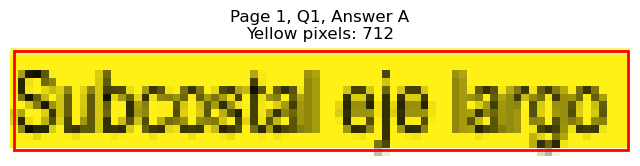

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=95.4, y1=114.7
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 173
Page 1, Q1, B: Yellow percentage: 0.0%


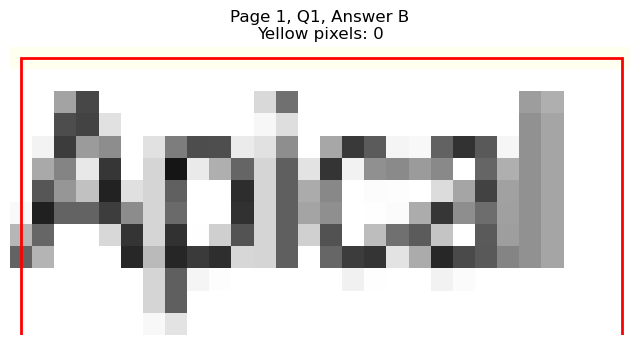

Page 1, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=381.2, y1=102.1
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 271
Page 1, Q1, C: Yellow percentage: 0.0%


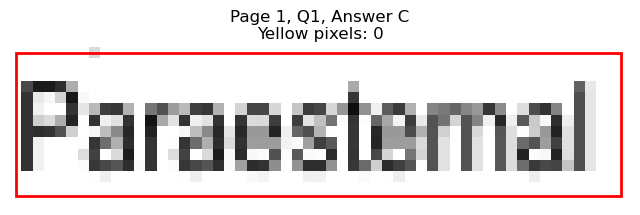

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=386.2, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 289
Page 1, Q1, D: Yellow percentage: 0.0%


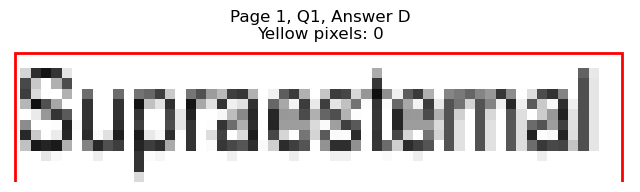


Page 1, Q1 - Selected Answer: A (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=150.5, y1=165.2
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 396
Page 1, Q2, A: Yellow percentage: 0.0%


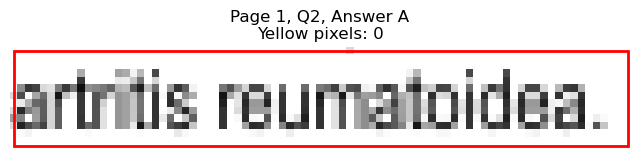

Page 1, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=182.2, y1=177.8
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 555
Page 1, Q2, B: Yellow percentage: 0.0%


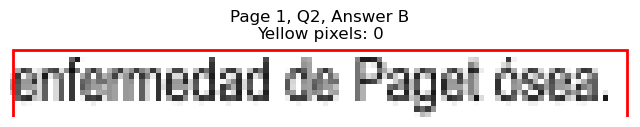

Page 1, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=425.8, y1=165.2
Page 1, Q2, C: Yellow pixels: 900
Page 1, Q2, C: Total non-white pixels: 1386
Page 1, Q2, C: Yellow percentage: 64.9%


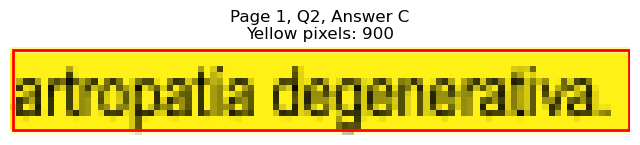

Page 1, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=400.3, y1=177.8
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 442
Page 1, Q2, D: Yellow percentage: 0.0%


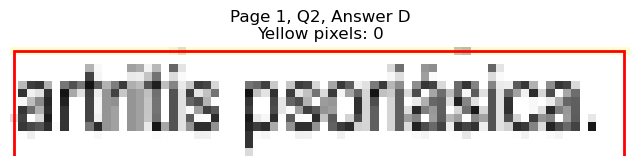


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=202.9, x1=165.6, y1=215.6
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 496
Page 1, Q3, A: Yellow percentage: 0.0%


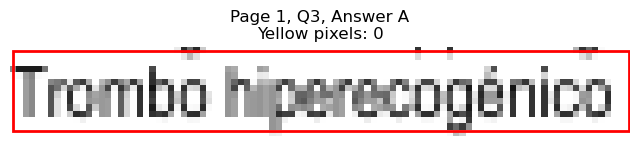

Page 1, Q3 - B: Detected box: x0=68.3, y0=215.7, x1=142.0, y1=228.3
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 390
Page 1, Q3, B: Yellow percentage: 0.0%


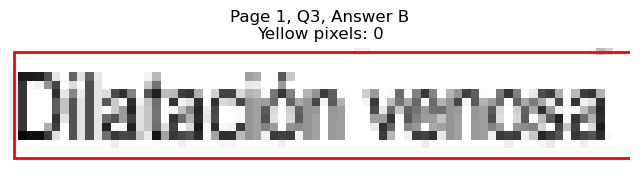

Page 1, Q3 - C: Detected box: x0=327.5, y0=202.9, x1=458.5, y1=215.6
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 678
Page 1, Q3, C: Yellow percentage: 0.0%


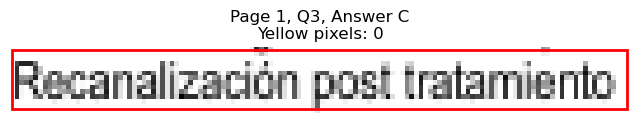

Page 1, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=411.8, y1=228.3
Page 1, Q3, D: Yellow pixels: 664
Page 1, Q3, D: Total non-white pixels: 1190
Page 1, Q3, D: Yellow percentage: 55.8%


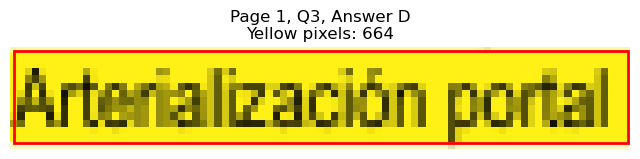


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=104.4, y1=291.5
Page 1, Q4, A: Yellow pixels: 37
Page 1, Q4, A: Total non-white pixels: 205
Page 1, Q4, A: Yellow percentage: 18.0%


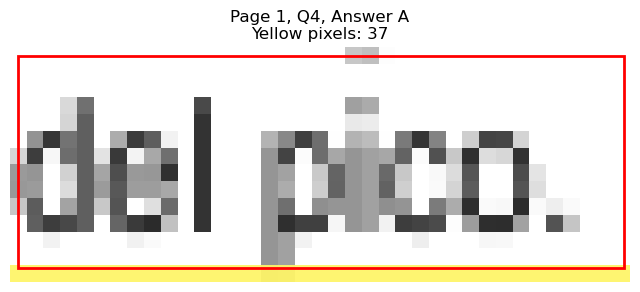

Page 1, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=118.5, y1=304.1
Page 1, Q4, B: Yellow pixels: 491
Page 1, Q4, B: Total non-white pixels: 714
Page 1, Q4, B: Yellow percentage: 68.8%


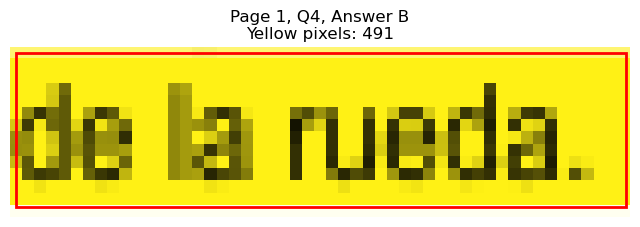

Page 1, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=383.2, y1=291.5
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 260
Page 1, Q4, C: Yellow percentage: 0.0%


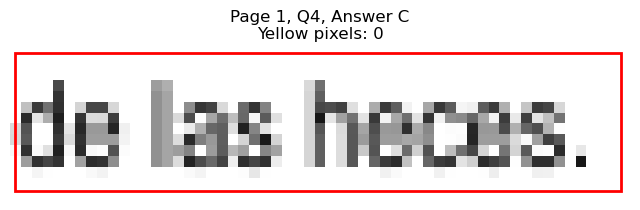

Page 1, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=392.8, y1=304.1
Page 1, Q4, D: Yellow pixels: 0
Page 1, Q4, D: Total non-white pixels: 321
Page 1, Q4, D: Yellow percentage: 0.0%


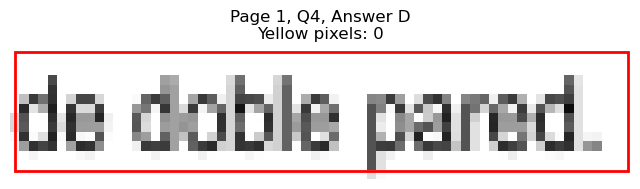


Page 1, Q4 - Selected Answer: B (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=116.9, y1=354.6
Page 1, Q5, A: Yellow pixels: 49
Page 1, Q5, A: Total non-white pixels: 330
Page 1, Q5, A: Yellow percentage: 14.8%


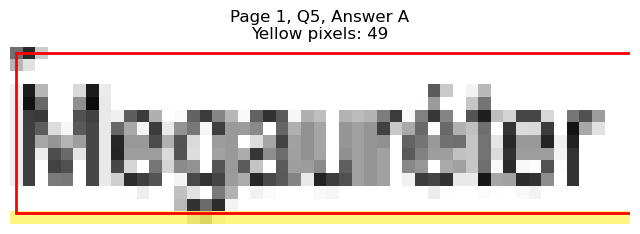

Page 1, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=117.5, y1=367.2
Page 1, Q5, B: Yellow pixels: 451
Page 1, Q5, B: Total non-white pixels: 700
Page 1, Q5, B: Yellow percentage: 64.4%


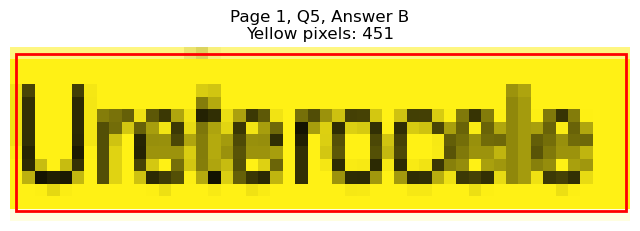

Page 1, Q5 - C: Detected box: x0=327.5, y0=341.9, x1=372.7, y1=354.6
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 230
Page 1, Q5, C: Yellow percentage: 0.0%


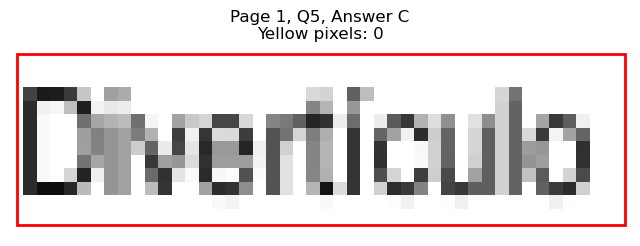

Page 1, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=402.3, y1=367.2
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 379
Page 1, Q5, D: Yellow percentage: 0.0%


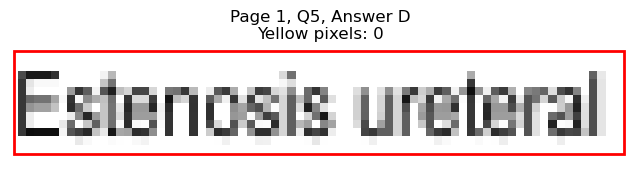


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=392.3, x1=107.9, y1=405.0
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 211
Page 1, Q6, A: Yellow percentage: 0.0%


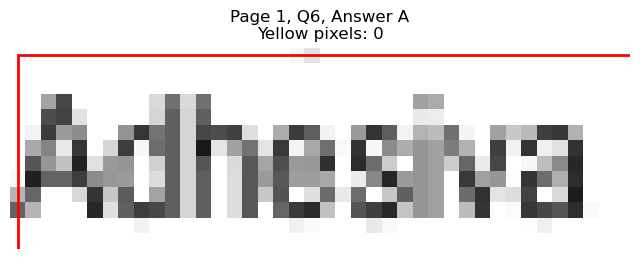

Page 1, Q6 - B: Detected box: x0=68.3, y0=404.9, x1=121.5, y1=417.6
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 281
Page 1, Q6, B: Yellow percentage: 0.0%


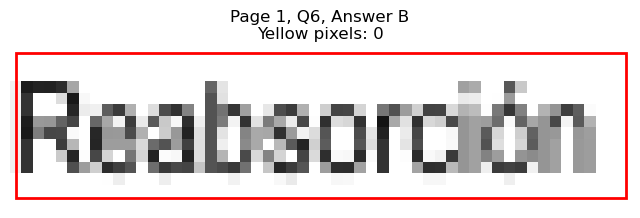

Page 1, Q6 - C: Detected box: x0=327.5, y0=392.3, x1=372.2, y1=405.0
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 292
Page 1, Q6, C: Yellow percentage: 0.0%


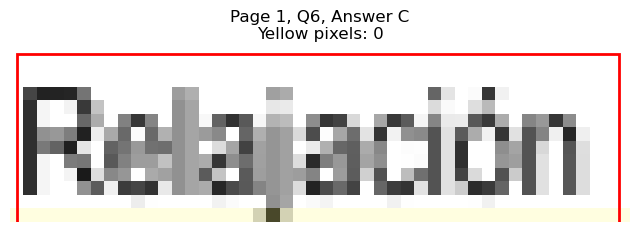

Page 1, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=381.7, y1=417.6
Page 1, Q6, D: Yellow pixels: 493
Page 1, Q6, D: Total non-white pixels: 770
Page 1, Q6, D: Yellow percentage: 64.0%


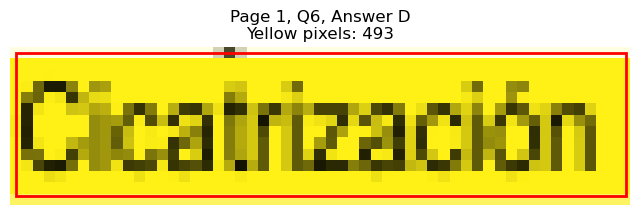


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=455.5, x1=99.4, y1=468.1
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 160
Page 1, Q7, A: Yellow percentage: 0.0%


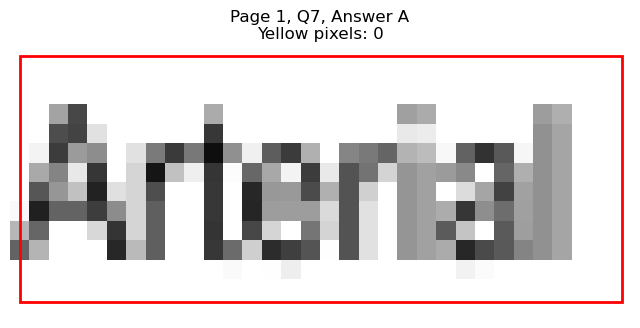

Page 1, Q7 - B: Detected box: x0=68.3, y0=468.1, x1=97.0, y1=480.7
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 138
Page 1, Q7, B: Yellow percentage: 0.0%


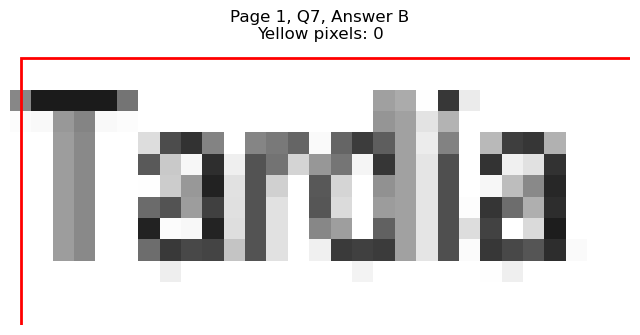

Page 1, Q7 - C: Detected box: x0=327.5, y0=455.5, x1=367.1, y1=468.1
Page 1, Q7, C: Yellow pixels: 41
Page 1, Q7, C: Total non-white pixels: 240
Page 1, Q7, C: Yellow percentage: 17.1%


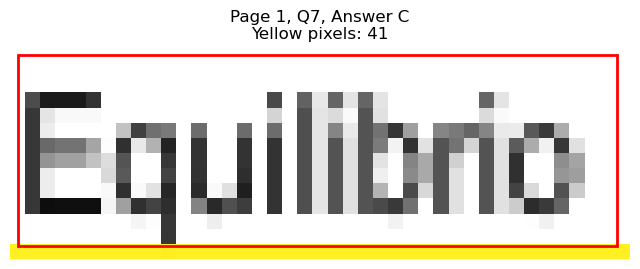

Page 1, Q7 - D: Detected box: x0=327.5, y0=468.1, x1=360.7, y1=480.7
Page 1, Q7, D: Yellow pixels: 330
Page 1, Q7, D: Total non-white pixels: 442
Page 1, Q7, D: Yellow percentage: 74.7%


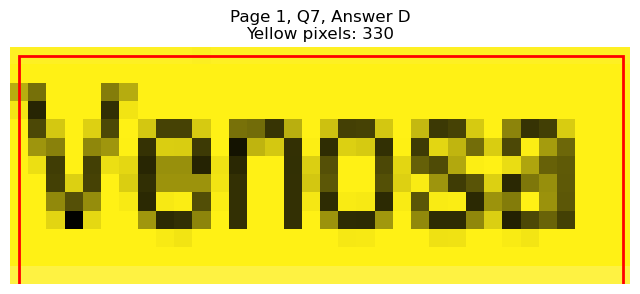


Page 1, Q7 - Selected Answer: D (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=506.0, x1=109.5, y1=518.6
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 224
Page 1, Q8, A: Yellow percentage: 0.0%


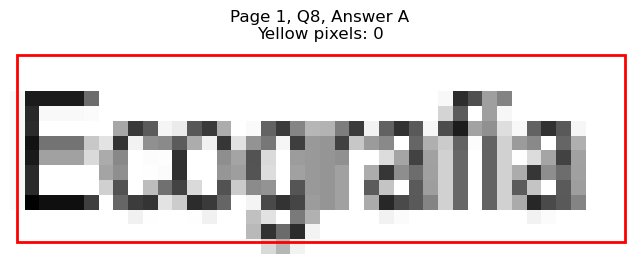

Page 1, Q8 - B: Detected box: x0=68.3, y0=518.6, x1=117.5, y1=531.2
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 285
Page 1, Q8, B: Yellow percentage: 0.0%


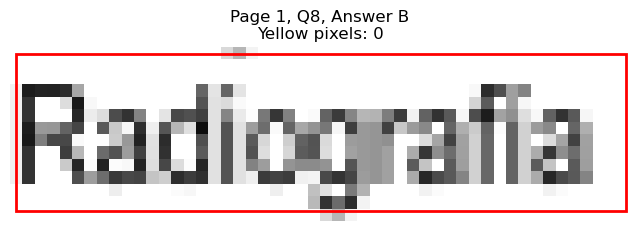

Page 1, Q8 - C: Detected box: x0=327.5, y0=506.0, x1=377.7, y1=518.6
Page 1, Q8, C: Yellow pixels: 51
Page 1, Q8, C: Total non-white pixels: 314
Page 1, Q8, C: Yellow percentage: 16.2%


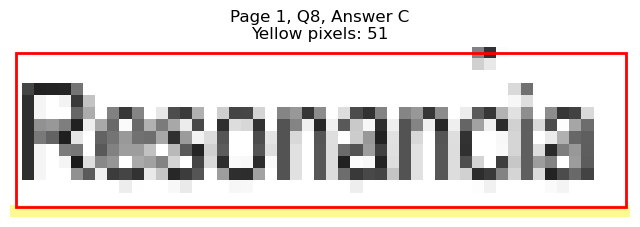

Page 1, Q8 - D: Detected box: x0=327.5, y0=518.6, x1=376.1, y1=531.2
Page 1, Q8, D: Yellow pixels: 467
Page 1, Q8, D: Total non-white pixels: 700
Page 1, Q8, D: Yellow percentage: 66.7%


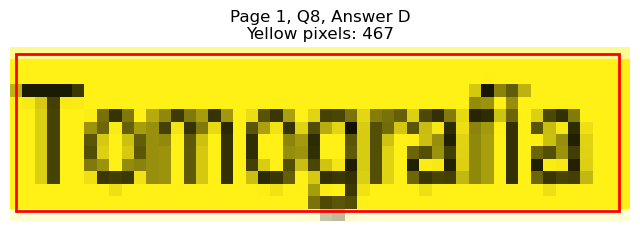


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=569.1, x1=101.4, y1=581.8
Page 1, Q9, A: Yellow pixels: 0
Page 1, Q9, A: Total non-white pixels: 197
Page 1, Q9, A: Yellow percentage: 0.0%


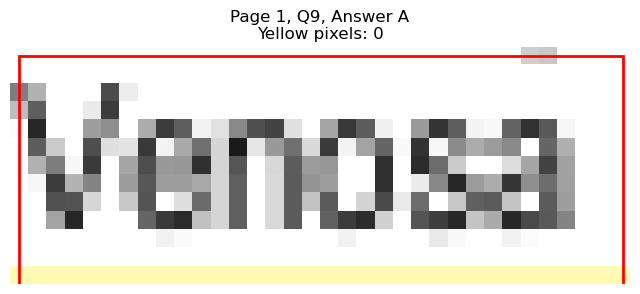

Page 1, Q9 - B: Detected box: x0=68.3, y0=468.1, x1=97.0, y1=480.7
Page 1, Q9, B: Yellow pixels: 0
Page 1, Q9, B: Total non-white pixels: 138
Page 1, Q9, B: Yellow percentage: 0.0%


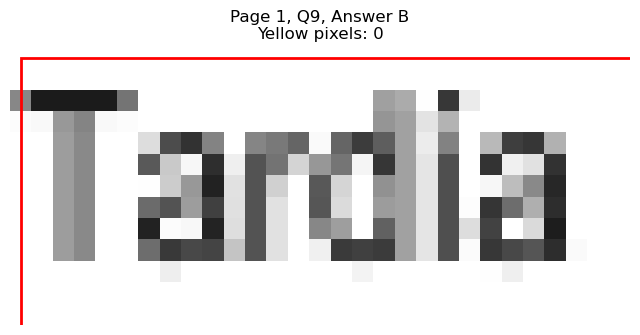

Page 1, Q9 - C: Detected box: x0=327.5, y0=569.1, x1=358.6, y1=581.8
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 159
Page 1, Q9, C: Yellow percentage: 0.0%


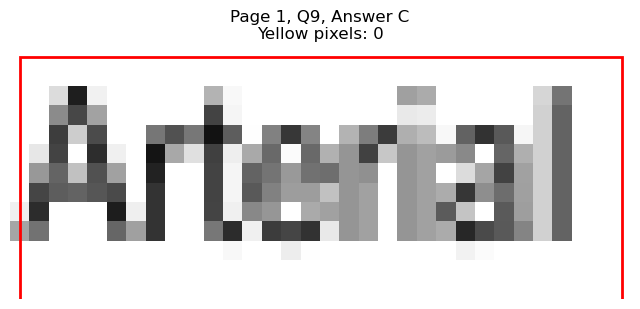

Page 1, Q9 - D: Detected box: x0=327.5, y0=581.7, x1=353.6, y1=594.4
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 130
Page 1, Q9, D: Yellow percentage: 0.0%


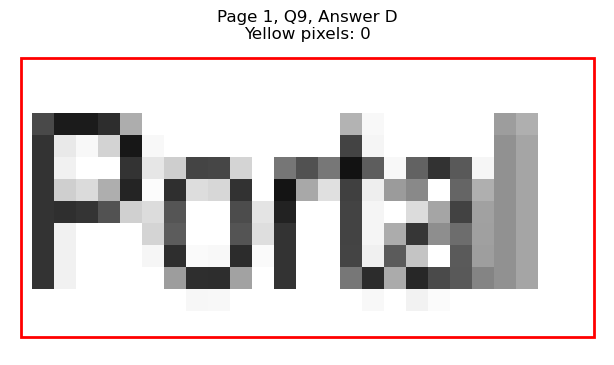

Page 1, Q10 - A: Detected box: x0=68.3, y0=619.6, x1=136.5, y1=632.3
Page 1, Q10, A: Yellow pixels: 584
Page 1, Q10, A: Total non-white pixels: 966
Page 1, Q10, A: Yellow percentage: 60.5%


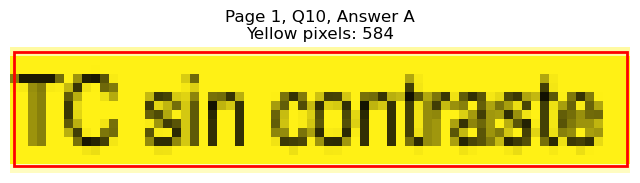

Page 1, Q10 - B: Detected box: x0=68.3, y0=632.2, x1=130.9, y1=644.9
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 390
Page 1, Q10, B: Yellow percentage: 0.0%


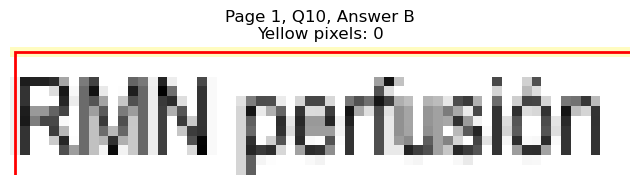

Page 1, Q10 - C: Detected box: x0=327.5, y0=619.6, x1=376.3, y1=632.3
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 245
Page 1, Q10, C: Yellow percentage: 0.0%


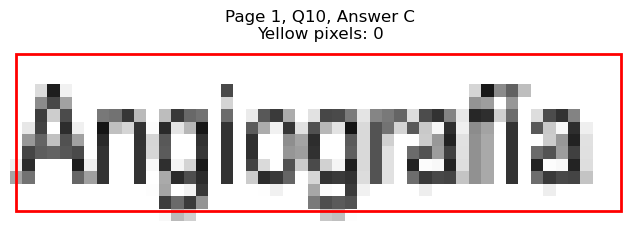

Page 1, Q10 - D: Detected box: x0=327.5, y0=632.2, x1=392.2, y1=644.9
Page 1, Q10, D: Yellow pixels: 0
Page 1, Q10, D: Total non-white pixels: 335
Page 1, Q10, D: Yellow percentage: 0.0%


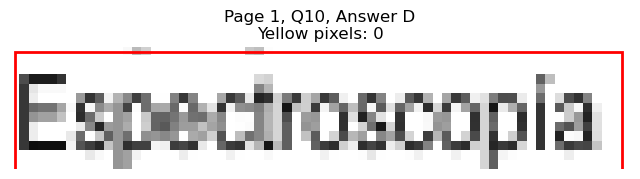


Page 1, Q10 - Selected Answer: A (based on yellow pixel count)




Page 1, Q11 - A: Detected box: x0=68.3, y0=670.1, x1=108.4, y1=682.7
Page 1, Q11, A: Yellow pixels: 0
Page 1, Q11, A: Total non-white pixels: 194
Page 1, Q11, A: Yellow percentage: 0.0%


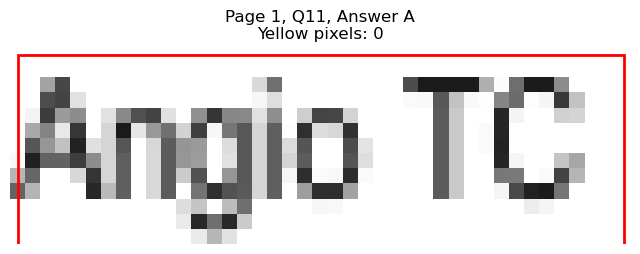

Page 1, Q11 - B: Detected box: x0=68.3, y0=682.7, x1=116.9, y1=695.3
Page 1, Q11, B: Yellow pixels: 0
Page 1, Q11, B: Total non-white pixels: 265
Page 1, Q11, B: Yellow percentage: 0.0%


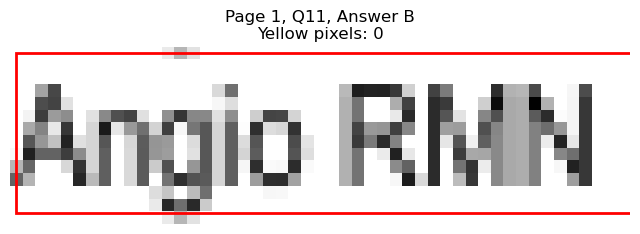

Page 1, Q11 - C: Detected box: x0=327.5, y0=670.1, x1=411.8, y1=682.7
Page 1, Q11, C: Yellow pixels: 3
Page 1, Q11, C: Total non-white pixels: 520
Page 1, Q11, C: Yellow percentage: 0.6%


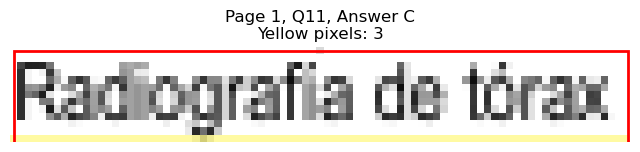

Page 1, Q11 - D: Detected box: x0=327.5, y0=682.7, x1=393.3, y1=695.3
Page 1, Q11, D: Yellow pixels: 557
Page 1, Q11, D: Total non-white pixels: 938
Page 1, Q11, D: Yellow percentage: 59.4%


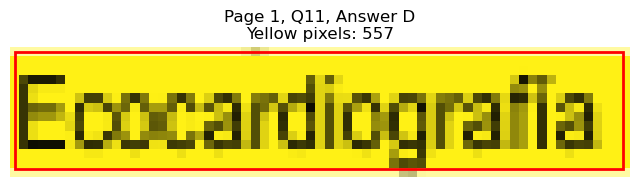


Page 1, Q11 - Selected Answer: D (based on yellow pixel count)




Page 1, Q12 - A: Detected box: x0=68.3, y0=733.2, x1=121.5, y1=745.8
Page 1, Q12, A: Yellow pixels: 0
Page 1, Q12, A: Total non-white pixels: 296
Page 1, Q12, A: Yellow percentage: 0.0%


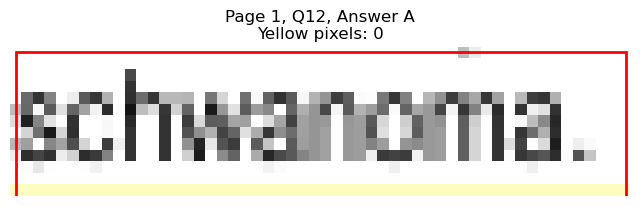

Page 1, Q12 - B: Detected box: x0=68.3, y0=745.8, x1=133.0, y1=758.4
Page 1, Q12, B: Yellow pixels: 590
Page 1, Q12, B: Total non-white pixels: 910
Page 1, Q12, B: Yellow percentage: 64.8%


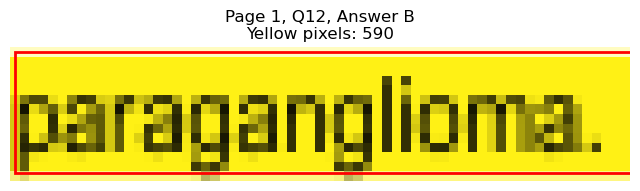

Page 1, Q12 - C: Detected box: x0=327.5, y0=733.2, x1=385.7, y1=745.8
Page 1, Q12, C: Yellow pixels: 0
Page 1, Q12, C: Total non-white pixels: 276
Page 1, Q12, C: Yellow percentage: 0.0%


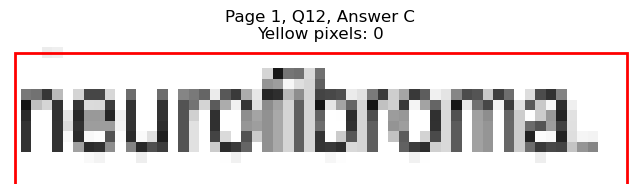

Page 1, Q12 - D: Detected box: x0=327.5, y0=745.8, x1=429.4, y1=758.4
Page 1, Q12, D: Yellow pixels: 0
Page 1, Q12, D: Total non-white pixels: 552
Page 1, Q12, D: Yellow percentage: 0.0%


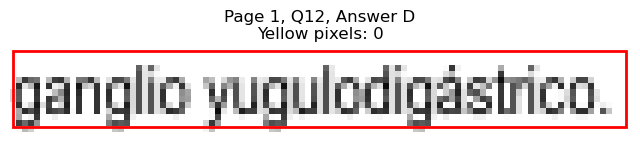


Page 1, Q12 - Selected Answer: B (based on yellow pixel count)





Page 2: Found 12 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=113.9, y1=102.1
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 268
Page 2, Q1, A: Yellow percentage: 0.0%


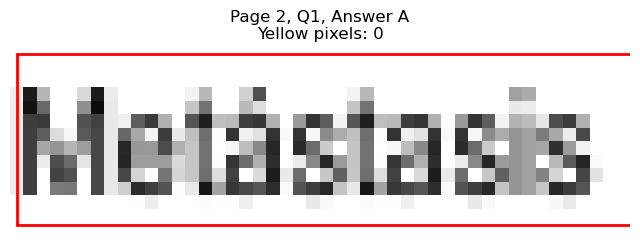

Page 2, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=124.9, y1=114.7
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 278
Page 2, Q1, B: Yellow percentage: 0.0%


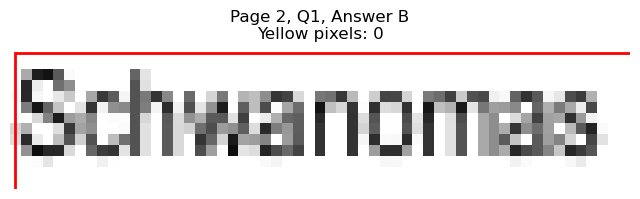

Page 2, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=363.2, y1=102.1
Page 2, Q1, C: Yellow pixels: 352
Page 2, Q1, C: Total non-white pixels: 518
Page 2, Q1, C: Yellow percentage: 68.0%


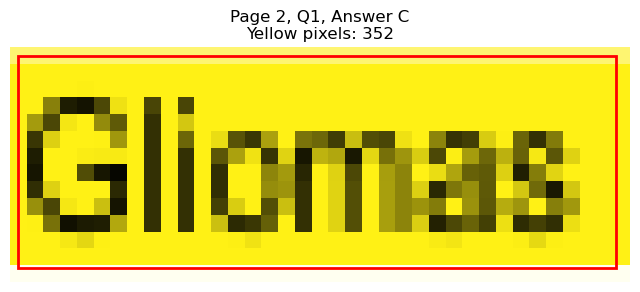

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=389.2, y1=114.7
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 378
Page 2, Q1, D: Yellow percentage: 0.0%


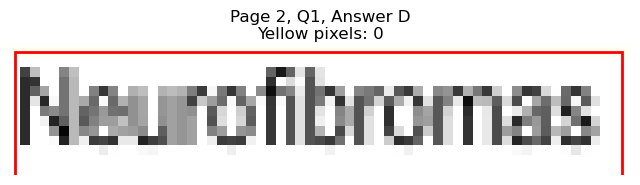


Page 2, Q1 - Selected Answer: C (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=139.9, x1=158.5, y1=152.6
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 441
Page 2, Q2, A: Yellow percentage: 0.0%


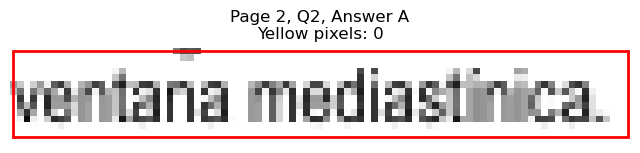

Page 2, Q2 - B: Detected box: x0=68.3, y0=152.5, x1=127.9, y1=165.2
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 286
Page 2, Q2, B: Yellow percentage: 0.0%


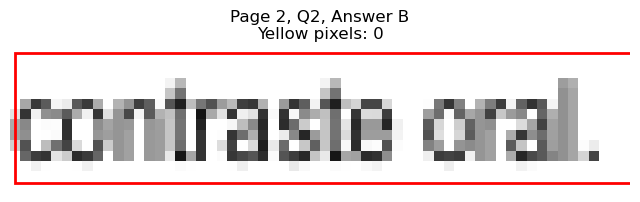

Page 2, Q2 - C: Detected box: x0=327.5, y0=139.9, x1=421.4, y1=152.6
Page 2, Q2, C: Yellow pixels: 95
Page 2, Q2, C: Total non-white pixels: 550
Page 2, Q2, C: Yellow percentage: 17.3%


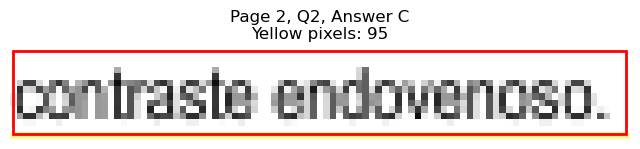

Page 2, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=404.8, y1=165.2
Page 2, Q2, D: Yellow pixels: 726
Page 2, Q2, D: Total non-white pixels: 1092
Page 2, Q2, D: Yellow percentage: 66.5%


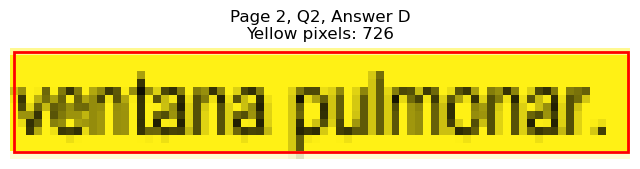


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=202.9, x1=100.9, y1=215.6
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 172
Page 2, Q3, A: Yellow percentage: 0.0%


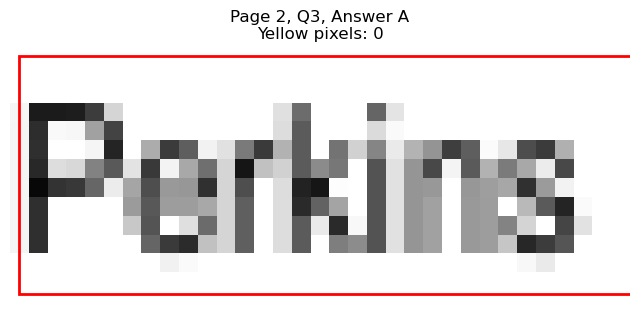

Page 2, Q3 - B: Detected box: x0=68.3, y0=215.7, x1=104.4, y1=228.3
Page 2, Q3, B: Yellow pixels: 300
Page 2, Q3, B: Total non-white pixels: 518
Page 2, Q3, B: Yellow percentage: 57.9%


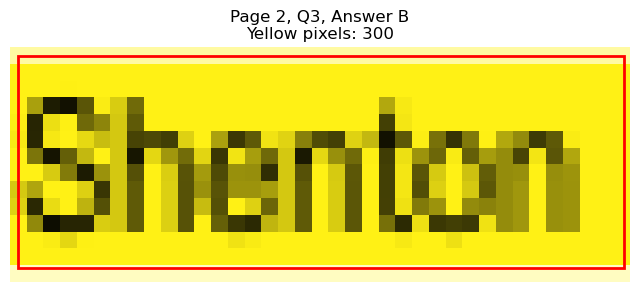

Page 2, Q3 - C: Detected box: x0=327.5, y0=202.9, x1=378.7, y1=215.6
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 294
Page 2, Q3, C: Yellow percentage: 0.0%


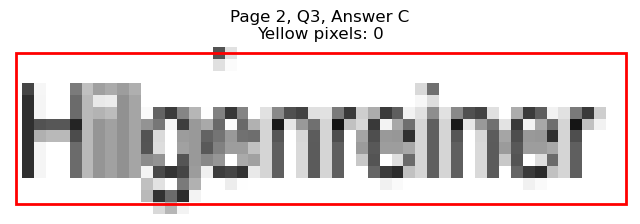

Page 2, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=398.8, y1=228.3
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 386
Page 2, Q3, D: Yellow percentage: 0.0%


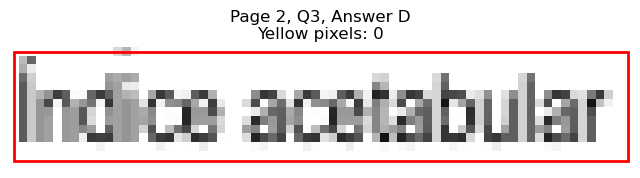


Page 2, Q3 - Selected Answer: B (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=266.1, x1=175.1, y1=278.7
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 547
Page 2, Q4, A: Yellow percentage: 0.0%


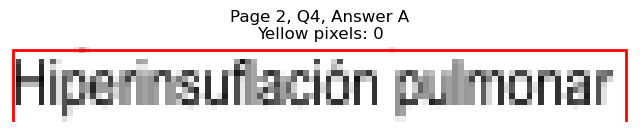

Page 2, Q4 - B: Detected box: x0=68.3, y0=278.8, x1=95.4, y1=291.5
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 153
Page 2, Q4, B: Yellow percentage: 0.0%


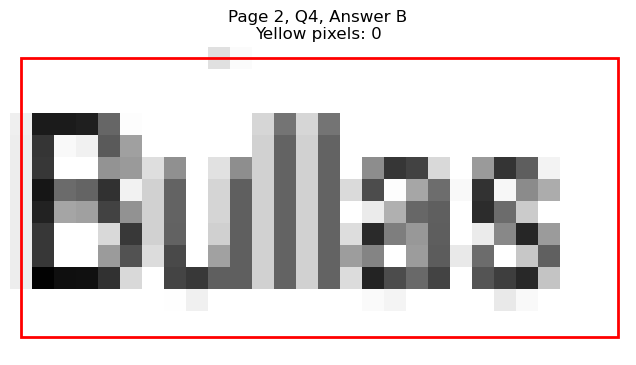

Page 2, Q4 - C: Detected box: x0=327.5, y0=266.1, x1=379.1, y1=278.7
Page 2, Q4, C: Yellow pixels: 465
Page 2, Q4, C: Total non-white pixels: 689
Page 2, Q4, C: Yellow percentage: 67.5%


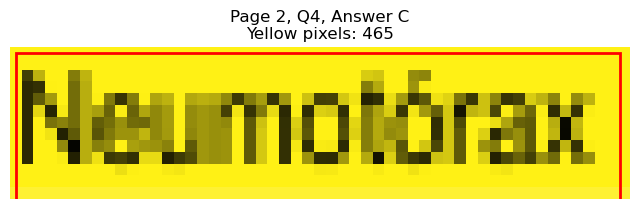

Page 2, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=374.2, y1=291.5
Page 2, Q4, D: Yellow pixels: 48
Page 2, Q4, D: Total non-white pixels: 305
Page 2, Q4, D: Yellow percentage: 15.7%


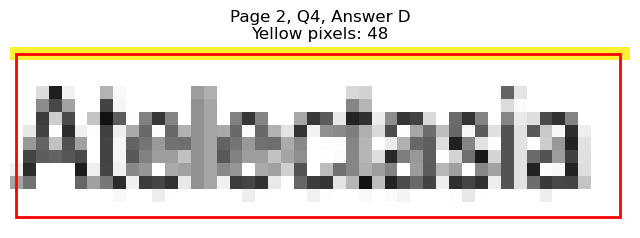


Page 2, Q4 - Selected Answer: C (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=105.4, y1=354.6
Page 2, Q5, A: Yellow pixels: 38
Page 2, Q5, A: Total non-white pixels: 215
Page 2, Q5, A: Yellow percentage: 17.7%


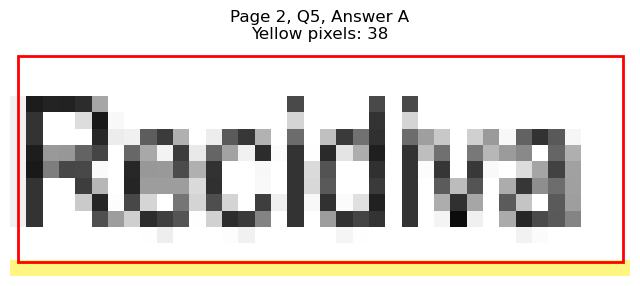

Page 2, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=105.9, y1=367.2
Page 2, Q5, B: Yellow pixels: 353
Page 2, Q5, B: Total non-white pixels: 532
Page 2, Q5, B: Yellow percentage: 66.4%


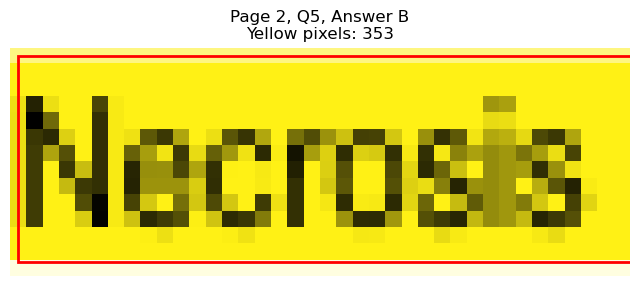

Page 2, Q5 - C: Detected box: x0=327.5, y0=341.9, x1=432.9, y1=354.6
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 522
Page 2, Q5, C: Yellow percentage: 0.0%


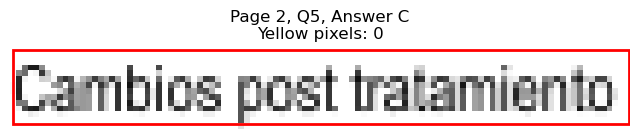

Page 2, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=366.2, y1=367.2
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 201
Page 2, Q5, D: Yellow percentage: 0.0%


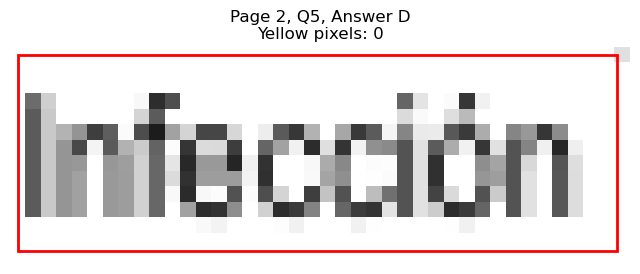


Page 2, Q5 - Selected Answer: B (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=392.3, x1=118.9, y1=405.0
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 267
Page 2, Q6, A: Yellow percentage: 0.0%


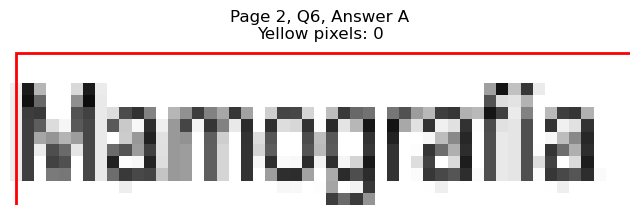

Page 2, Q6 - B: Detected box: x0=68.3, y0=404.9, x1=109.5, y1=417.6
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 231
Page 2, Q6, B: Yellow percentage: 0.0%


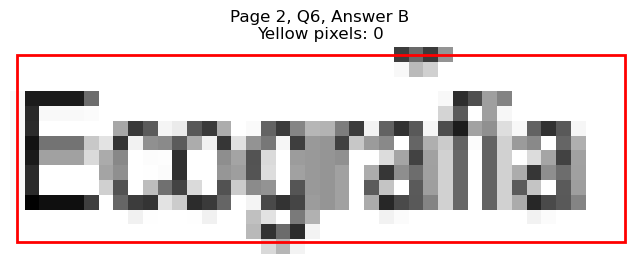

Page 2, Q6 - C: Detected box: x0=327.5, y0=392.3, x1=376.1, y1=405.0
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 284
Page 2, Q6, C: Yellow percentage: 0.0%


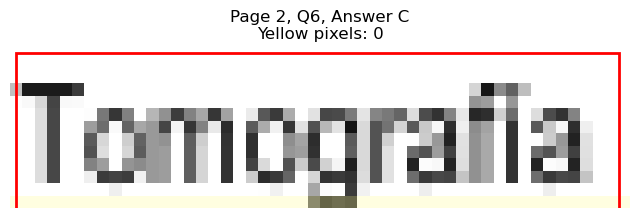

Page 2, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=377.7, y1=417.6
Page 2, Q6, D: Yellow pixels: 477
Page 2, Q6, D: Total non-white pixels: 714
Page 2, Q6, D: Yellow percentage: 66.8%


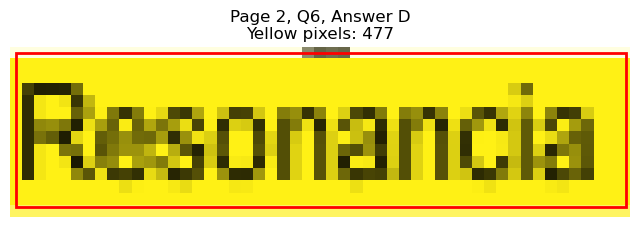


Page 2, Q6 - Selected Answer: D (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=455.5, x1=118.5, y1=468.1
Page 2, Q7, A: Yellow pixels: 475
Page 2, Q7, A: Total non-white pixels: 714
Page 2, Q7, A: Yellow percentage: 66.5%


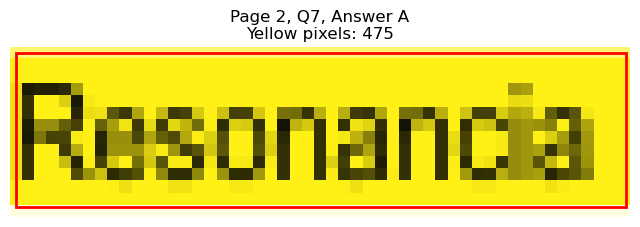

Page 2, Q7 - B: Detected box: x0=68.3, y0=468.1, x1=126.0, y1=480.7
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 348
Page 2, Q7, B: Yellow percentage: 0.0%


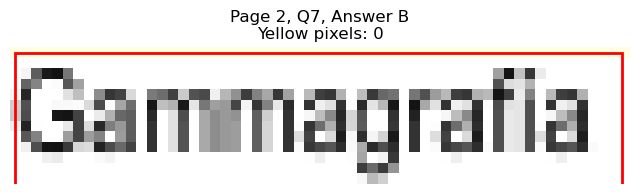

Page 2, Q7 - C: Detected box: x0=327.5, y0=392.3, x1=376.1, y1=405.0
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 284
Page 2, Q7, C: Yellow percentage: 0.0%


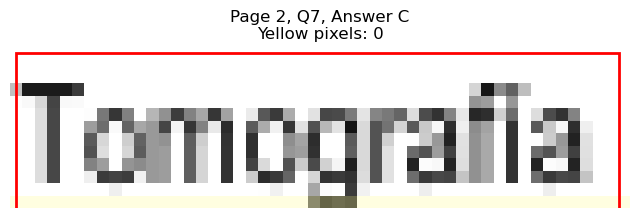

Page 2, Q7 - D: Detected box: x0=327.5, y0=468.1, x1=376.7, y1=480.7
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 278
Page 2, Q7, D: Yellow percentage: 0.0%


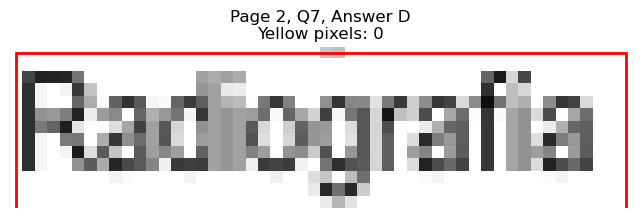


Page 2, Q7 - Selected Answer: A (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=518.6, x1=116.9, y1=531.2
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 235
Page 2, Q8, A: Yellow percentage: 0.0%


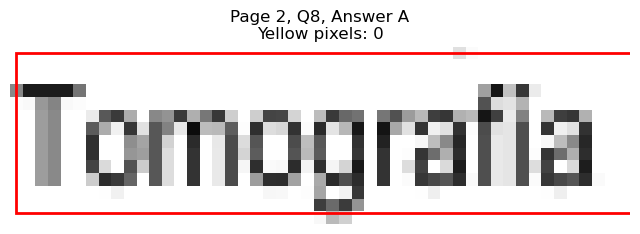

Page 2, Q8 - B: Detected box: x0=68.3, y0=404.9, x1=109.5, y1=417.6
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 231
Page 2, Q8, B: Yellow percentage: 0.0%


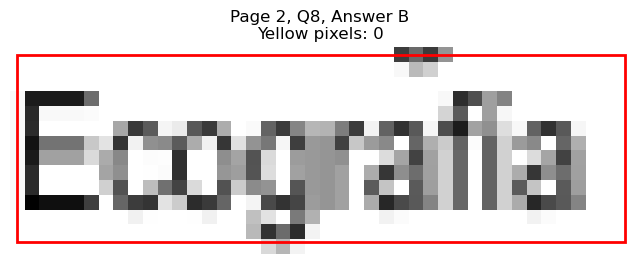

Page 2, Q8 - C: Detected box: x0=327.5, y0=518.6, x1=376.7, y1=531.2
Page 2, Q8, C: Yellow pixels: 50
Page 2, Q8, C: Total non-white pixels: 323
Page 2, Q8, C: Yellow percentage: 15.5%


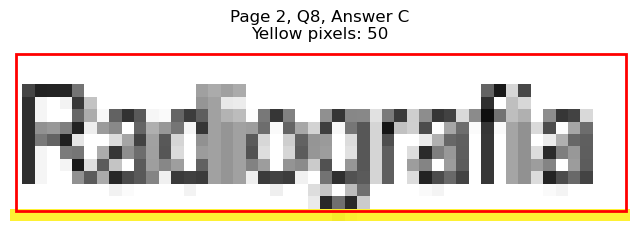

Page 2, Q8 - D: Detected box: x0=327.5, y0=404.9, x1=377.7, y1=417.6
Page 2, Q8, D: Yellow pixels: 477
Page 2, Q8, D: Total non-white pixels: 714
Page 2, Q8, D: Yellow percentage: 66.8%


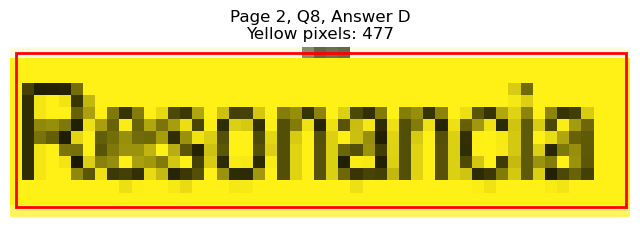


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=581.7, x1=152.5, y1=594.4
Page 2, Q9, A: Yellow pixels: 694
Page 2, Q9, A: Total non-white pixels: 1190
Page 2, Q9, A: Yellow percentage: 58.3%


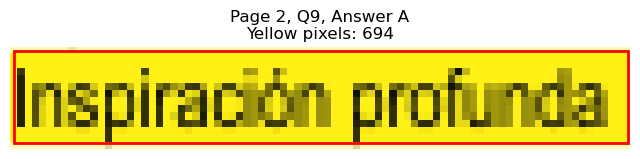

Page 2, Q9 - B: Detected box: x0=68.3, y0=594.3, x1=276.4, y1=607.0
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 1251
Page 2, Q9, B: Yellow percentage: 0.0%


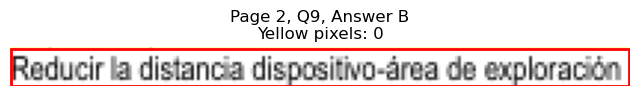

Page 2, Q9 - C: Detected box: x0=327.5, y0=581.7, x1=435.4, y1=594.4
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 530
Page 2, Q9, C: Yellow percentage: 0.0%


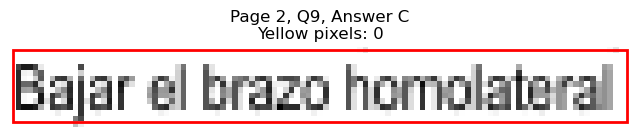

Page 2, Q9 - D: Detected box: x0=327.5, y0=594.3, x1=442.4, y1=607.0
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 564
Page 2, Q9, D: Yellow percentage: 0.0%


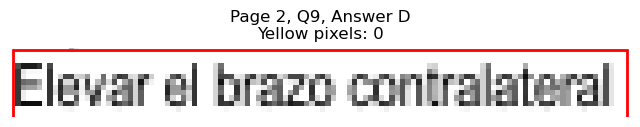


Page 2, Q9 - Selected Answer: A (based on yellow pixel count)




Page 2, Q10 - A: Detected box: x0=68.3, y0=455.5, x1=118.5, y1=468.1
Page 2, Q10, A: Yellow pixels: 475
Page 2, Q10, A: Total non-white pixels: 714
Page 2, Q10, A: Yellow percentage: 66.5%


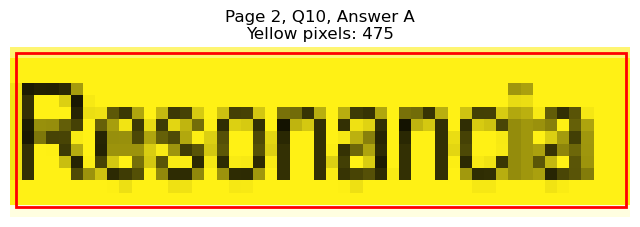

Page 2, Q10 - B: Detected box: x0=68.3, y0=644.9, x1=156.0, y1=657.5
Page 2, Q10, B: Yellow pixels: 814
Page 2, Q10, B: Total non-white pixels: 1246
Page 2, Q10, B: Yellow percentage: 65.3%


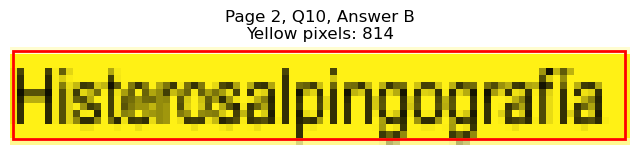

Page 2, Q10 - C: Detected box: x0=327.5, y0=392.3, x1=376.1, y1=405.0
Page 2, Q10, C: Yellow pixels: 0
Page 2, Q10, C: Total non-white pixels: 284
Page 2, Q10, C: Yellow percentage: 0.0%


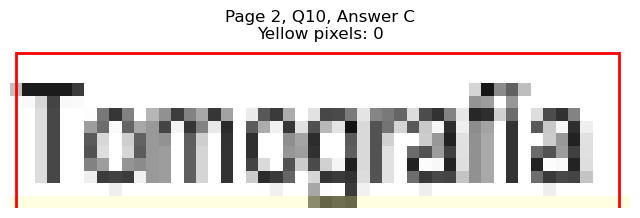

Page 2, Q10 - D: Detected box: x0=327.5, y0=644.9, x1=368.7, y1=657.5
Page 2, Q10, D: Yellow pixels: 0
Page 2, Q10, D: Total non-white pixels: 226
Page 2, Q10, D: Yellow percentage: 0.0%


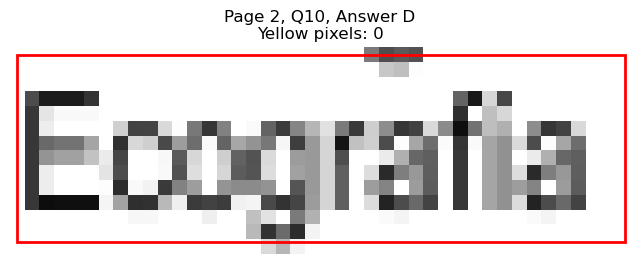


Page 2, Q10 - Selected Answer: B (based on yellow pixel count)




Page 2, Q11 - A: Detected box: x0=68.3, y0=695.4, x1=102.4, y1=708.0
Page 2, Q11, A: Yellow pixels: 35
Page 2, Q11, A: Total non-white pixels: 253
Page 2, Q11, A: Yellow percentage: 13.8%


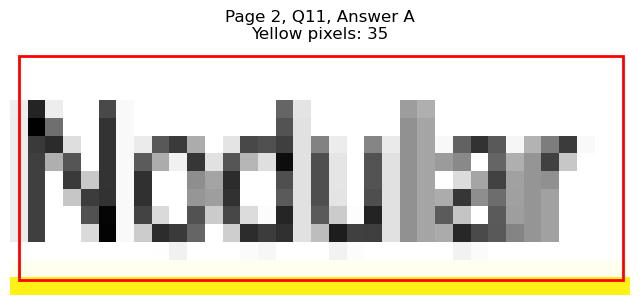

Page 2, Q11 - B: Detected box: x0=68.3, y0=708.0, x1=123.5, y1=720.6
Page 2, Q11, B: Yellow pixels: 517
Page 2, Q11, B: Total non-white pixels: 784
Page 2, Q11, B: Yellow percentage: 65.9%


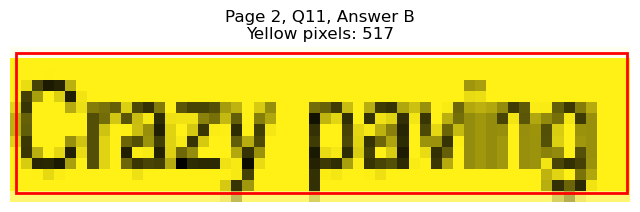

Page 2, Q11 - C: Detected box: x0=327.5, y0=695.4, x1=389.2, y1=708.0
Page 2, Q11, C: Yellow pixels: 0
Page 2, Q11, C: Total non-white pixels: 296
Page 2, Q11, C: Yellow percentage: 0.0%


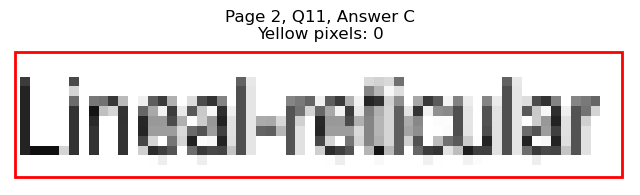

Page 2, Q11 - D: Detected box: x0=327.5, y0=708.0, x1=362.7, y1=720.6
Page 2, Q11, D: Yellow pixels: 0
Page 2, Q11, D: Total non-white pixels: 170
Page 2, Q11, D: Yellow percentage: 0.0%


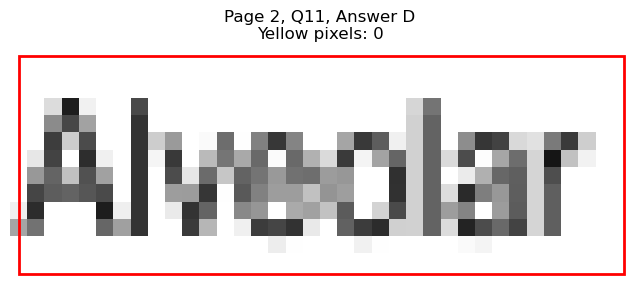


Page 2, Q11 - Selected Answer: B (based on yellow pixel count)




Page 2, Q12 - A: Detected box: x0=68.3, y0=745.8, x1=148.6, y1=758.4
Page 2, Q12, A: Yellow pixels: 0
Page 2, Q12, A: Total non-white pixels: 437
Page 2, Q12, A: Yellow percentage: 0.0%


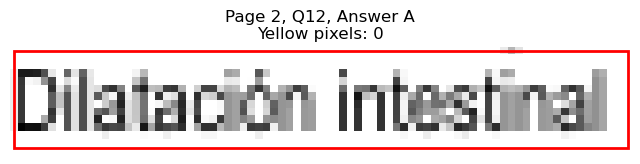

Page 2, Q12 - B: Detected box: x0=68.3, y0=758.5, x1=170.1, y1=771.2
Page 2, Q12, B: Yellow pixels: 0
Page 2, Q12, B: Total non-white pixels: 496
Page 2, Q12, B: Yellow percentage: 0.0%


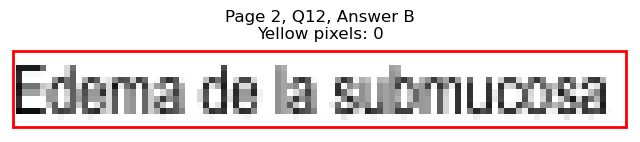

Page 2, Q12 - C: Detected box: x0=327.5, y0=745.8, x1=411.8, y1=758.4
Page 2, Q12, C: Yellow pixels: 0
Page 2, Q12, C: Total non-white pixels: 445
Page 2, Q12, C: Yellow percentage: 0.0%


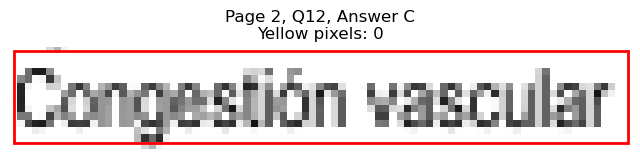

Page 2, Q12 - D: Detected box: x0=327.5, y0=758.5, x1=410.9, y1=771.2
Page 2, Q12, D: Yellow pixels: 796
Page 2, Q12, D: Total non-white pixels: 1176
Page 2, Q12, D: Yellow percentage: 67.7%


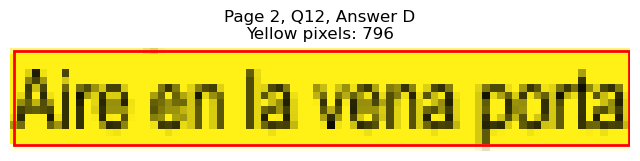


Page 2, Q12 - Selected Answer: D (based on yellow pixel count)





Page 3: Found 11 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=109.9, y1=114.7
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 241
Page 3, Q1, A: Yellow percentage: 0.0%


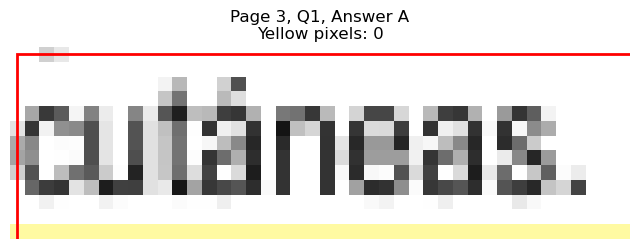

Page 3, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=124.9, y1=127.3
Page 3, Q1, B: Yellow pixels: 454
Page 3, Q1, B: Total non-white pixels: 798
Page 3, Q1, B: Yellow percentage: 56.9%


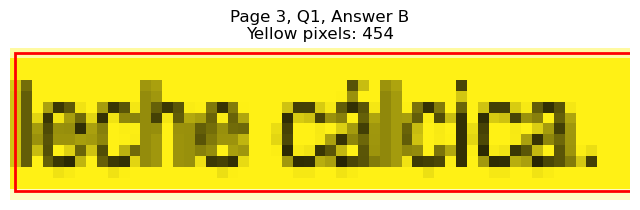

Page 3, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=375.7, y1=114.7
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 239
Page 3, Q1, C: Yellow percentage: 0.0%


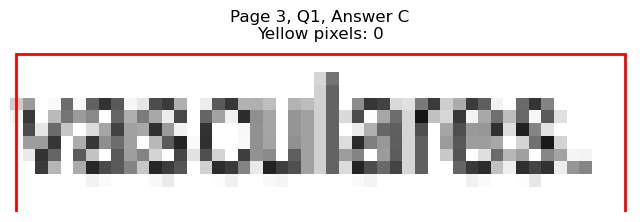

Page 3, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=365.1, y1=127.3
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 168
Page 3, Q1, D: Yellow percentage: 0.0%


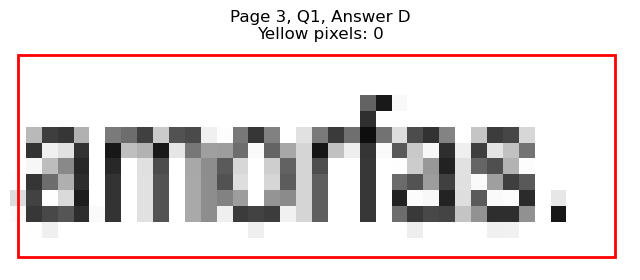


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=109.5, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 234
Page 3, Q2, A: Yellow percentage: 0.0%


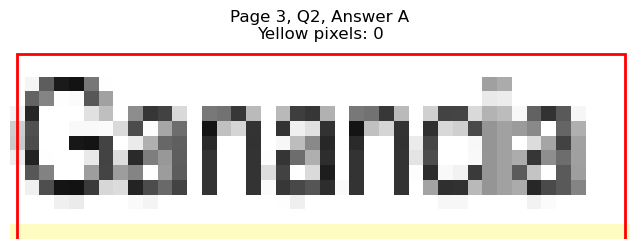

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=90.9, y1=190.4
Page 3, Q2, B: Yellow pixels: 201
Page 3, Q2, B: Total non-white pixels: 322
Page 3, Q2, B: Yellow percentage: 62.4%


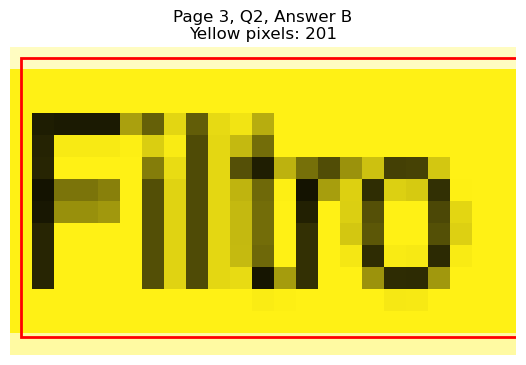

Page 3, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=400.7, y1=177.8
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 346
Page 3, Q2, C: Yellow percentage: 0.0%


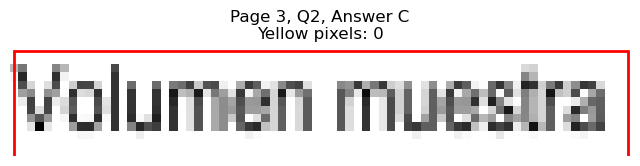

Page 3, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=413.3, y1=190.4
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 424
Page 3, Q2, D: Yellow percentage: 0.0%


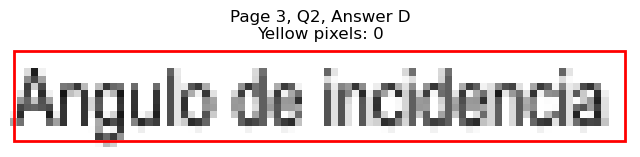


Page 3, Q2 - Selected Answer: B (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=98.4, y1=253.5
Page 3, Q3, A: Yellow pixels: 31
Page 3, Q3, A: Total non-white pixels: 206
Page 3, Q3, A: Yellow percentage: 15.0%


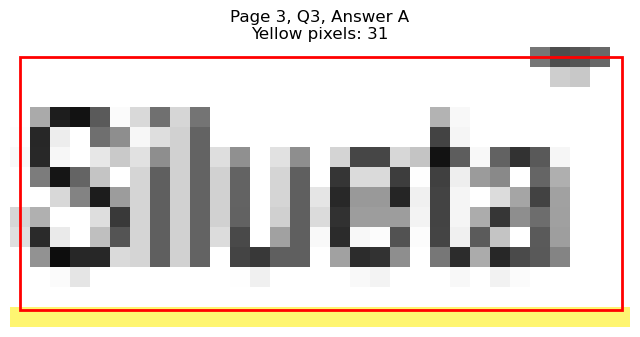

Page 3, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=129.5, y1=266.1
Page 3, Q3, B: Yellow pixels: 564
Page 3, Q3, B: Total non-white pixels: 868
Page 3, Q3, B: Yellow percentage: 65.0%


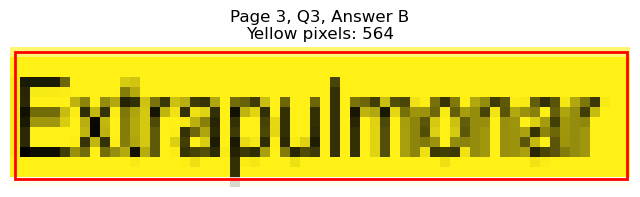

Page 3, Q3 - C: Detected box: x0=327.5, y0=240.9, x1=385.7, y1=253.5
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 296
Page 3, Q3, C: Yellow percentage: 0.0%


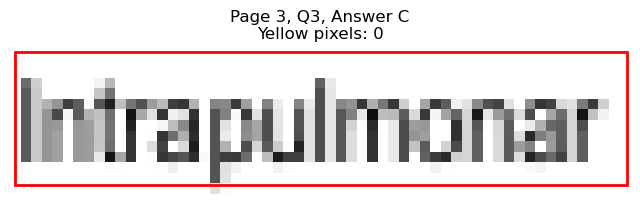

Page 3, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=392.2, y1=266.1
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 311
Page 3, Q3, D: Yellow percentage: 0.0%


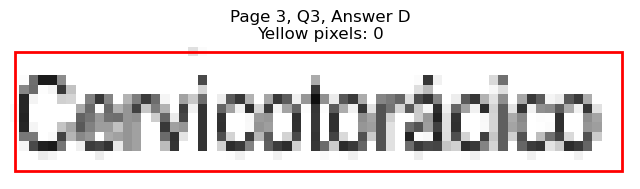


Page 3, Q3 - Selected Answer: B (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=137.1, y1=304.1
Page 3, Q4, A: Yellow pixels: 636
Page 3, Q4, A: Total non-white pixels: 980
Page 3, Q4, A: Yellow percentage: 64.9%


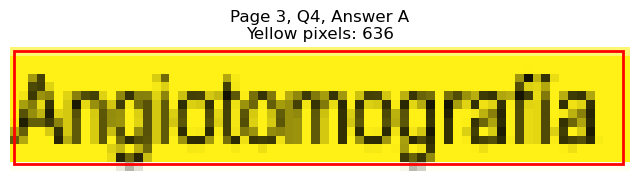

Page 3, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=109.5, y1=316.7
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 266
Page 3, Q4, B: Yellow percentage: 0.0%


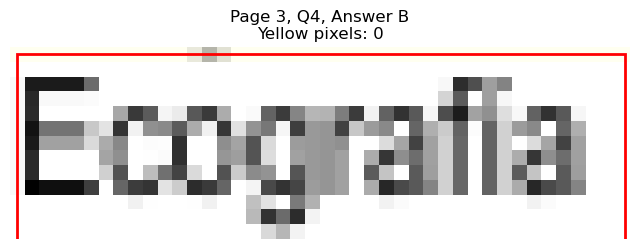

Page 3, Q4 - C: Detected box: x0=327.5, y0=291.4, x1=397.3, y1=304.1
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 350
Page 3, Q4, C: Yellow percentage: 0.0%


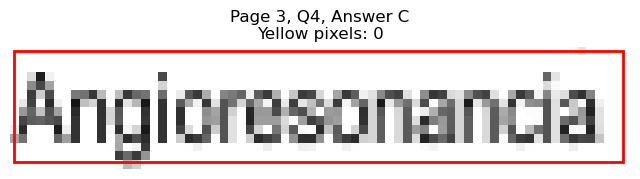

Page 3, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=362.1, y1=316.7
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 159
Page 3, Q4, D: Yellow percentage: 0.0%


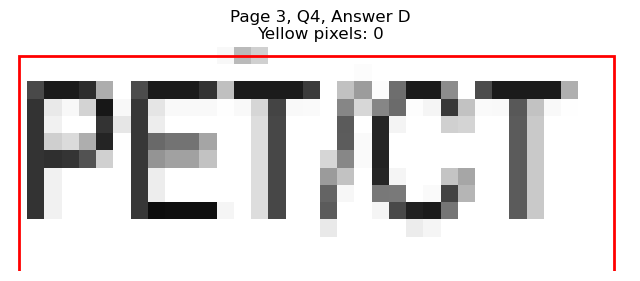


Page 3, Q4 - Selected Answer: A (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=367.1, x1=148.6, y1=379.8
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 390
Page 3, Q5, A: Yellow percentage: 0.0%


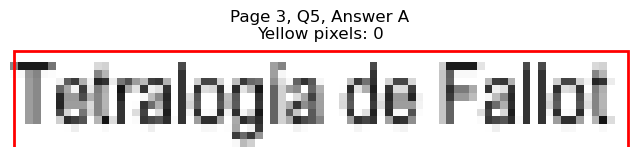

Page 3, Q5 - B: Detected box: x0=68.3, y0=379.7, x1=176.7, y1=392.4
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 578
Page 3, Q5, B: Yellow percentage: 0.0%


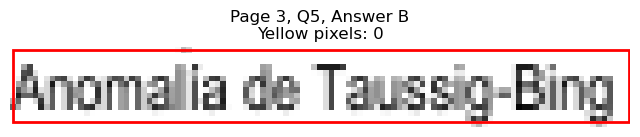

Page 3, Q5 - C: Detected box: x0=327.5, y0=367.1, x1=490.5, y1=379.8
Page 3, Q5, C: Yellow pixels: 1510
Page 3, Q5, C: Total non-white pixels: 2132
Page 3, Q5, C: Yellow percentage: 70.8%


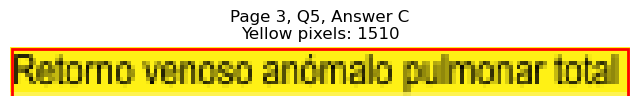

Page 3, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=404.2, y1=392.4
Page 3, Q5, D: Yellow pixels: 78
Page 3, Q5, D: Total non-white pixels: 477
Page 3, Q5, D: Yellow percentage: 16.4%


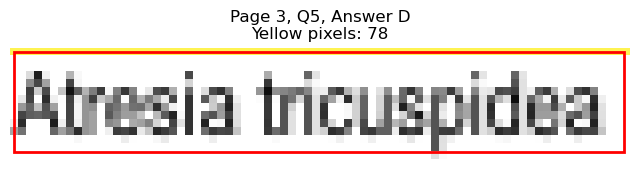


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=85.2, y1=430.3
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 73
Page 3, Q6, A: Yellow percentage: 0.0%


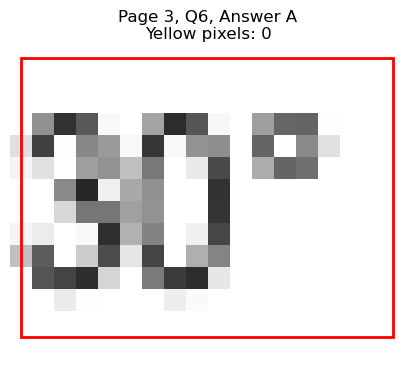

Page 3, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=85.2, y1=442.9
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 74
Page 3, Q6, B: Yellow percentage: 0.0%


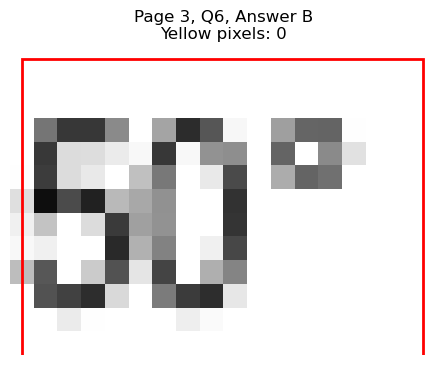

Page 3, Q6 - C: Detected box: x0=327.5, y0=417.6, x1=344.5, y1=430.3
Page 3, Q6, C: Yellow pixels: 164
Page 3, Q6, C: Total non-white pixels: 252
Page 3, Q6, C: Yellow percentage: 65.1%


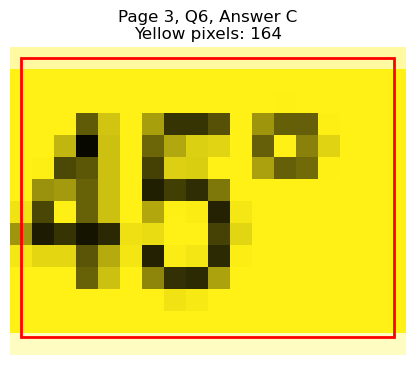

Page 3, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=344.5, y1=442.9
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 84
Page 3, Q6, D: Yellow percentage: 0.0%


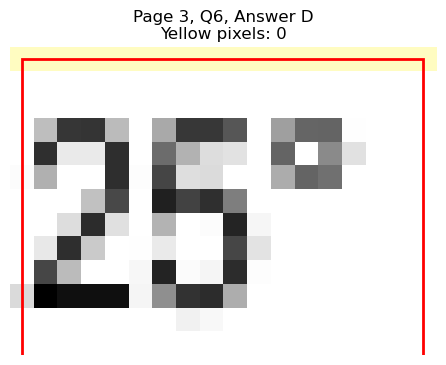


Page 3, Q6 - Selected Answer: C (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=480.8, x1=134.1, y1=493.4
Page 3, Q7, A: Yellow pixels: 574
Page 3, Q7, A: Total non-white pixels: 938
Page 3, Q7, A: Yellow percentage: 61.2%


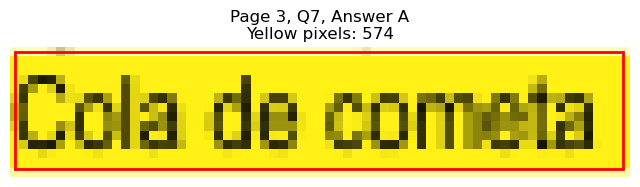

Page 3, Q7 - B: Detected box: x0=68.3, y0=493.4, x1=175.6, y1=506.0
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 672
Page 3, Q7, B: Yellow percentage: 0.0%


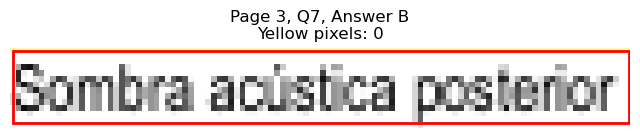

Page 3, Q7 - C: Detected box: x0=327.5, y0=480.8, x1=401.8, y1=493.4
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 377
Page 3, Q7, C: Yellow percentage: 0.0%


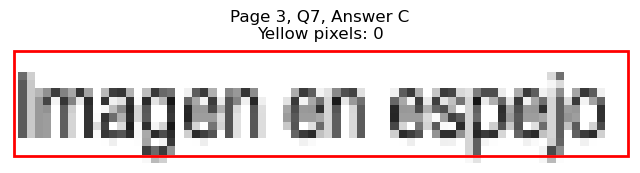

Page 3, Q7 - D: Detected box: x0=327.5, y0=493.4, x1=439.9, y1=506.0
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 566
Page 3, Q7, D: Yellow percentage: 0.0%


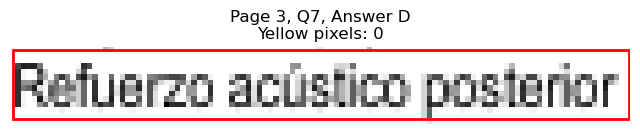


Page 3, Q7 - Selected Answer: A (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=543.8, x1=109.0, y1=556.4
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 200
Page 3, Q8, A: Yellow percentage: 0.0%


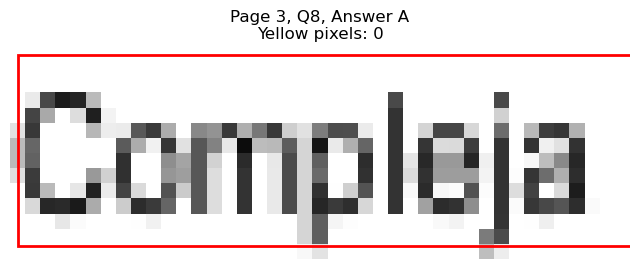

Page 3, Q8 - B: Detected box: x0=68.3, y0=556.5, x1=115.0, y1=569.2
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 236
Page 3, Q8, B: Yellow percentage: 0.0%


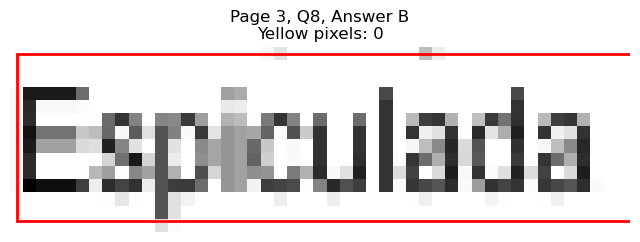

Page 3, Q8 - C: Detected box: x0=327.5, y0=543.8, x1=416.8, y1=556.4
Page 3, Q8, C: Yellow pixels: 816
Page 3, Q8, C: Total non-white pixels: 1260
Page 3, Q8, C: Yellow percentage: 64.8%


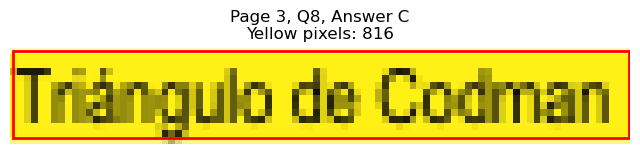

Page 3, Q8 - D: Detected box: x0=327.5, y0=556.5, x1=362.7, y1=569.2
Page 3, Q8, D: Yellow pixels: 35
Page 3, Q8, D: Total non-white pixels: 197
Page 3, Q8, D: Yellow percentage: 17.8%


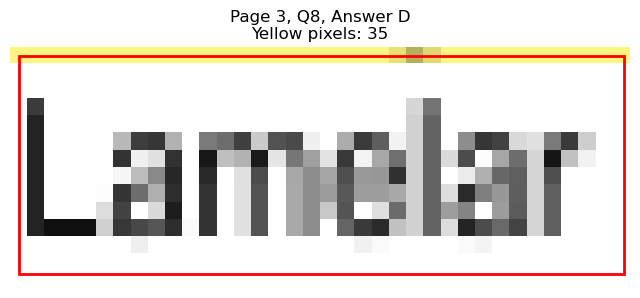


Page 3, Q8 - Selected Answer: C (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=56.6, y0=606.9, x1=65.2, y1=619.6
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 35
Page 3, Q9, A: Yellow percentage: 0.0%


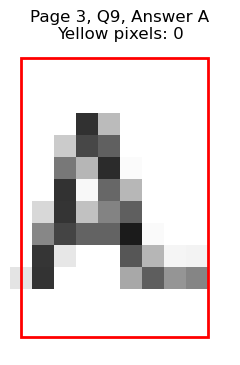

Page 3, Q9 - B: Detected box: x0=56.6, y0=619.6, x1=65.2, y1=632.3
Page 3, Q9, B: Yellow pixels: 83
Page 3, Q9, B: Total non-white pixels: 140
Page 3, Q9, B: Yellow percentage: 59.3%


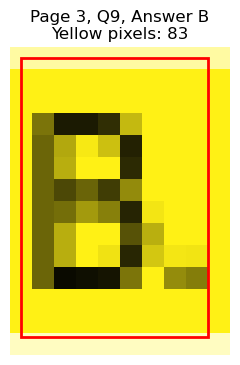

Page 3, Q9 - C: Detected box: x0=327.5, y0=606.9, x1=337.6, y1=619.6
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 48
Page 3, Q9, C: Yellow percentage: 0.0%


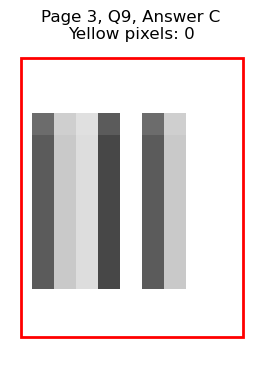

Page 3, Q9 - D: Detected box: x0=327.5, y0=619.6, x1=338.6, y1=632.3
Page 3, Q9, D: Yellow pixels: 0
Page 3, Q9, D: Total non-white pixels: 42
Page 3, Q9, D: Yellow percentage: 0.0%


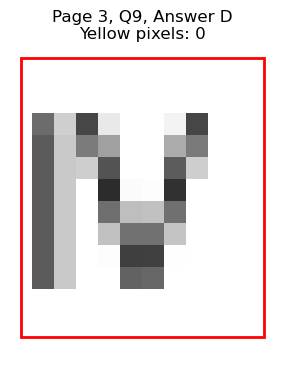


Page 3, Q9 - Selected Answer: B (based on yellow pixel count)




Page 3, Q10 - A: Detected box: x0=68.3, y0=657.5, x1=109.5, y1=670.1
Page 3, Q10, A: Yellow pixels: 365
Page 3, Q10, A: Total non-white pixels: 588
Page 3, Q10, A: Yellow percentage: 62.1%


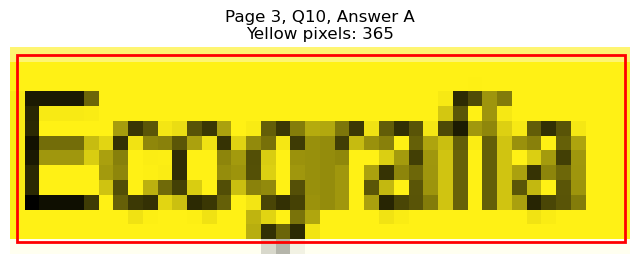

Page 3, Q10 - B: Detected box: x0=68.3, y0=670.1, x1=116.9, y1=682.7
Page 3, Q10, B: Yellow pixels: 0
Page 3, Q10, B: Total non-white pixels: 283
Page 3, Q10, B: Yellow percentage: 0.0%


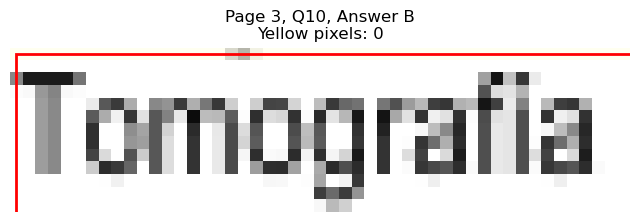

Page 3, Q10 - C: Detected box: x0=327.5, y0=657.5, x1=377.7, y1=670.1
Page 3, Q10, C: Yellow pixels: 0
Page 3, Q10, C: Total non-white pixels: 261
Page 3, Q10, C: Yellow percentage: 0.0%


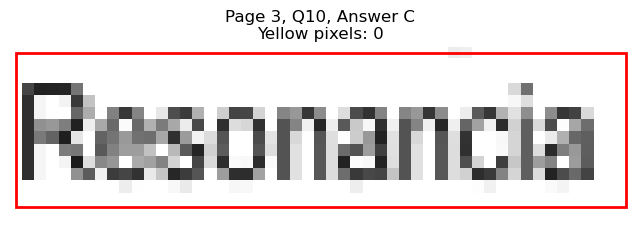

Page 3, Q10 - D: Detected box: x0=327.5, y0=670.1, x1=376.7, y1=682.7
Page 3, Q10, D: Yellow pixels: 0
Page 3, Q10, D: Total non-white pixels: 276
Page 3, Q10, D: Yellow percentage: 0.0%


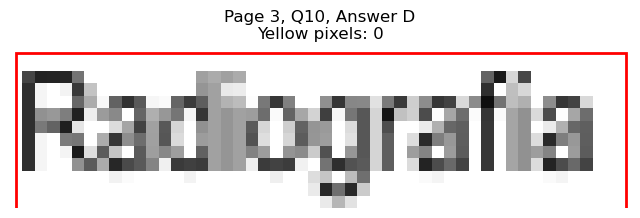


Page 3, Q10 - Selected Answer: A (based on yellow pixel count)




Page 3, Q11 - A: Detected box: x0=68.3, y0=708.0, x1=95.9, y1=720.6
Page 3, Q11, A: Yellow pixels: 0
Page 3, Q11, A: Total non-white pixels: 142
Page 3, Q11, A: Yellow percentage: 0.0%


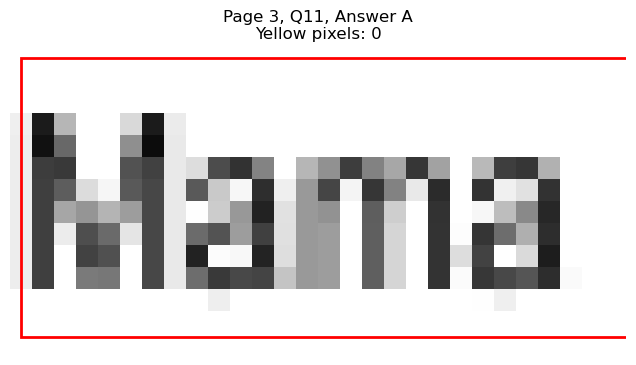

Page 3, Q11 - B: Detected box: x0=68.3, y0=720.6, x1=101.4, y1=733.2
Page 3, Q11, B: Yellow pixels: 0
Page 3, Q11, B: Total non-white pixels: 168
Page 3, Q11, B: Yellow percentage: 0.0%


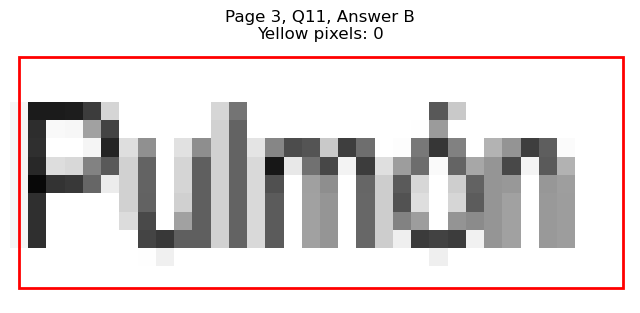

Page 3, Q11 - C: Detected box: x0=327.5, y0=708.0, x1=363.7, y1=720.6
Page 3, Q11, C: Yellow pixels: 37
Page 3, Q11, C: Total non-white pixels: 226
Page 3, Q11, C: Yellow percentage: 16.4%


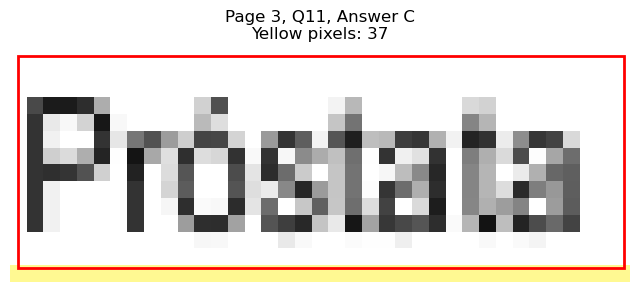

Page 3, Q11 - D: Detected box: x0=327.5, y0=720.6, x1=372.2, y1=733.2
Page 3, Q11, D: Yellow pixels: 407
Page 3, Q11, D: Total non-white pixels: 644
Page 3, Q11, D: Yellow percentage: 63.2%


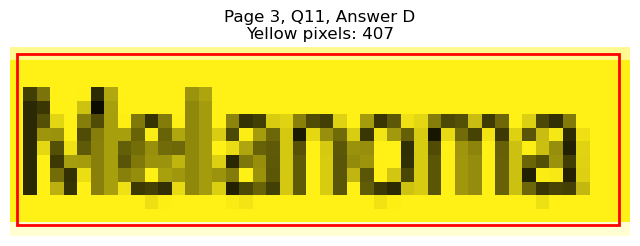


Page 3, Q11 - Selected Answer: D (based on yellow pixel count)





Page 4: Found 11 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=124.5, y1=114.7
Page 4, Q1, A: Yellow pixels: 530
Page 4, Q1, A: Total non-white pixels: 741
Page 4, Q1, A: Yellow percentage: 71.5%


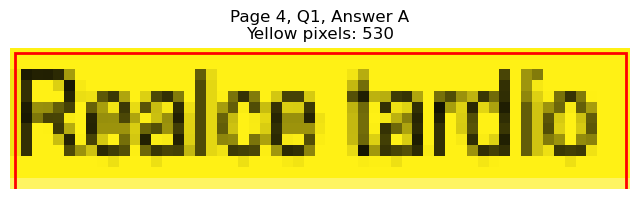

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=145.1, y1=127.3
Page 4, Q1, B: Yellow pixels: 78
Page 4, Q1, B: Total non-white pixels: 459
Page 4, Q1, B: Yellow percentage: 17.0%


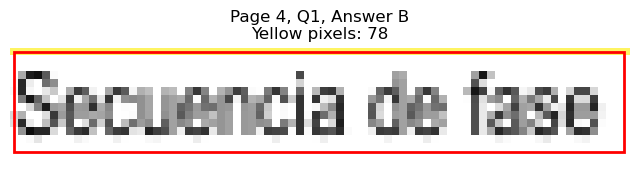

Page 4, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=384.8, y1=114.7
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 287
Page 4, Q1, C: Yellow percentage: 0.0%


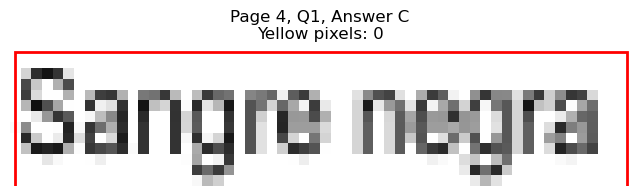

Page 4, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=424.9, y1=127.3
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 486
Page 4, Q1, D: Yellow percentage: 0.0%


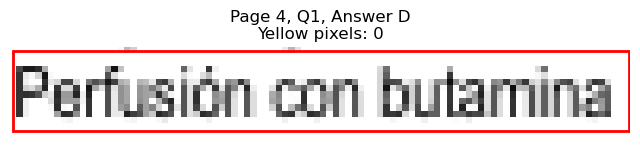


Page 4, Q1 - Selected Answer: A (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=115.0, y1=177.8
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 263
Page 4, Q2, A: Yellow percentage: 0.0%


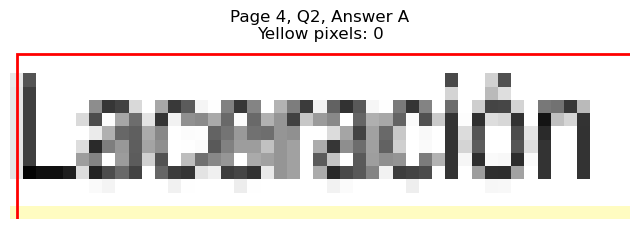

Page 4, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=111.4, y1=190.4
Page 4, Q2, B: Yellow pixels: 355
Page 4, Q2, B: Total non-white pixels: 616
Page 4, Q2, B: Yellow percentage: 57.6%


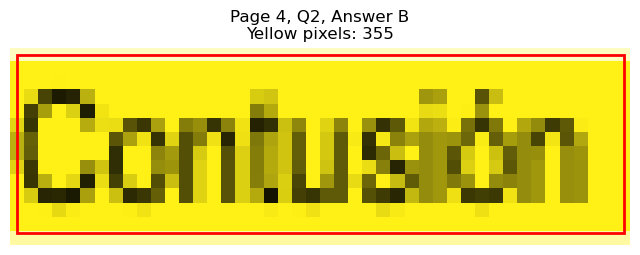

Page 4, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=374.2, y1=177.8
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 234
Page 4, Q2, C: Yellow percentage: 0.0%


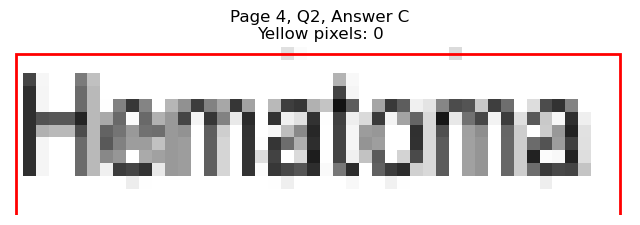

Page 4, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=355.6, y1=190.4
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 142
Page 4, Q2, D: Yellow percentage: 0.0%


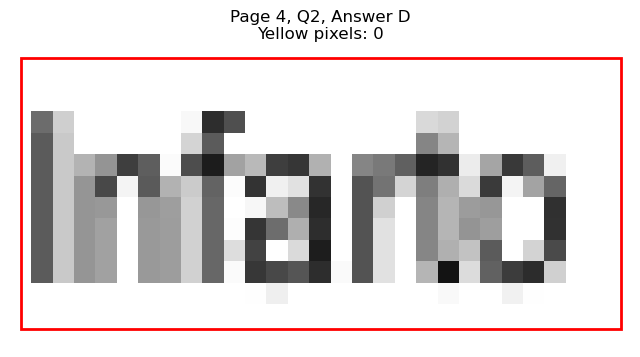


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=171.6, y1=240.9
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 599
Page 4, Q3, A: Yellow percentage: 0.0%


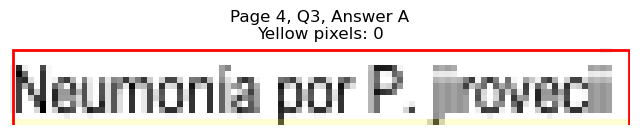

Page 4, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=183.6, y1=253.5
Page 4, Q3, B: Yellow pixels: 1083
Page 4, Q3, B: Total non-white pixels: 1624
Page 4, Q3, B: Yellow percentage: 66.7%


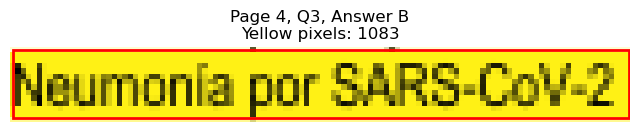

Page 4, Q3 - C: Detected box: x0=327.5, y0=228.3, x1=400.7, y1=240.9
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 384
Page 4, Q3, C: Yellow percentage: 0.0%


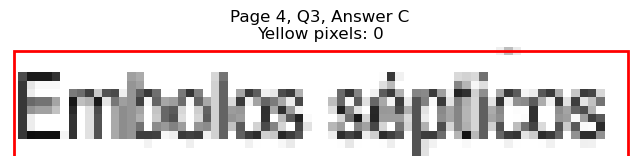

Page 4, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=450.9, y1=253.5
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 631
Page 4, Q3, D: Yellow percentage: 0.0%


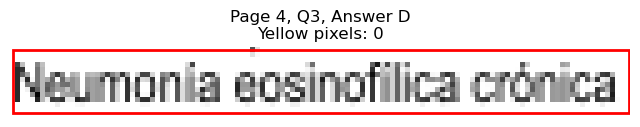


Page 4, Q3 - Selected Answer: B (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=128.5, y1=291.5
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 295
Page 4, Q4, A: Yellow percentage: 0.0%


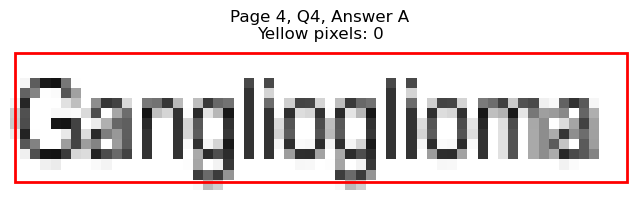

Page 4, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=119.9, y1=304.1
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 295
Page 4, Q4, B: Yellow percentage: 0.0%


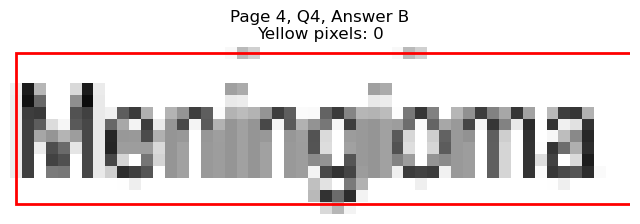

Page 4, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=443.3, y1=291.5
Page 4, Q4, C: Yellow pixels: 117
Page 4, Q4, C: Total non-white pixels: 683
Page 4, Q4, C: Yellow percentage: 17.1%


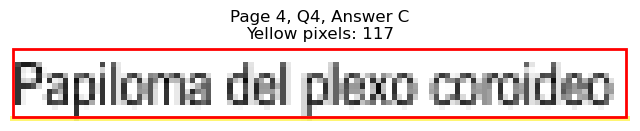

Page 4, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=396.3, y1=304.1
Page 4, Q4, D: Yellow pixels: 597
Page 4, Q4, D: Total non-white pixels: 980
Page 4, Q4, D: Yellow percentage: 60.9%


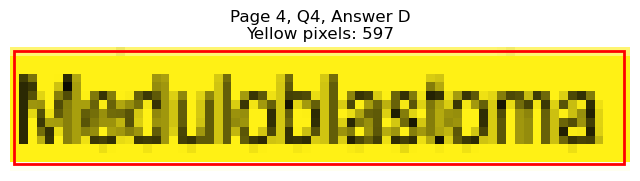


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=341.9, x1=155.5, y1=354.6
Page 4, Q5, A: Yellow pixels: 0
Page 4, Q5, A: Total non-white pixels: 450
Page 4, Q5, A: Yellow percentage: 0.0%


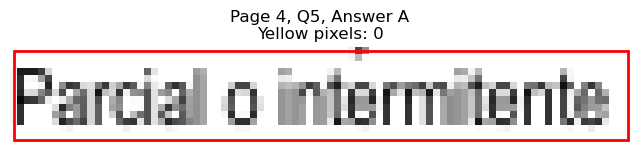

Page 4, Q5 - B: Detected box: x0=68.3, y0=354.5, x1=167.7, y1=367.2
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 486
Page 4, Q5, B: Yellow percentage: 0.0%


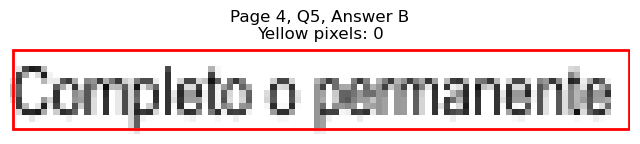

Page 4, Q5 - C: Detected box: x0=327.5, y0=341.9, x1=401.8, y1=354.6
Page 4, Q5, C: Yellow pixels: 75
Page 4, Q5, C: Total non-white pixels: 457
Page 4, Q5, C: Yellow percentage: 16.4%


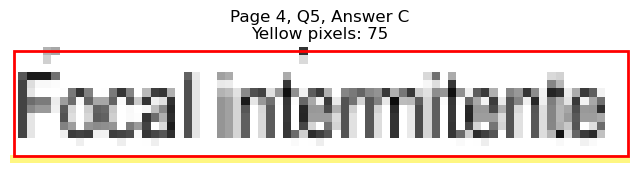

Page 4, Q5 - D: Detected box: x0=327.5, y0=354.5, x1=394.3, y1=367.2
Page 4, Q5, D: Yellow pixels: 644
Page 4, Q5, D: Total non-white pixels: 952
Page 4, Q5, D: Yellow percentage: 67.6%


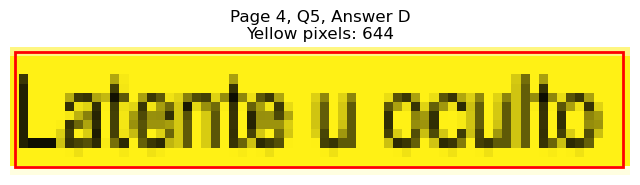


Page 4, Q5 - Selected Answer: D (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=417.6, x1=139.0, y1=430.3
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 321
Page 4, Q6, A: Yellow percentage: 0.0%


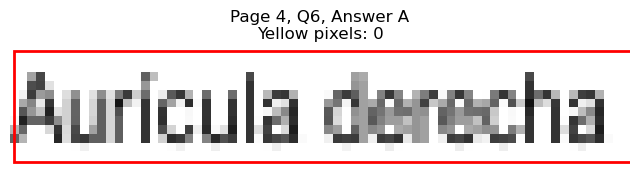

Page 4, Q6 - B: Detected box: x0=68.3, y0=430.2, x1=146.5, y1=442.9
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 391
Page 4, Q6, B: Yellow percentage: 0.0%


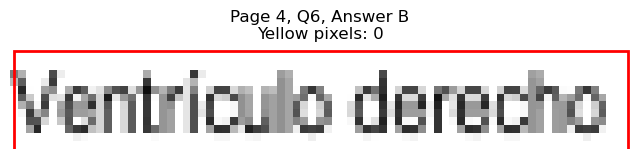

Page 4, Q6 - C: Detected box: x0=327.5, y0=417.6, x1=409.7, y1=430.3
Page 4, Q6, C: Yellow pixels: 83
Page 4, Q6, C: Total non-white pixels: 495
Page 4, Q6, C: Yellow percentage: 16.8%


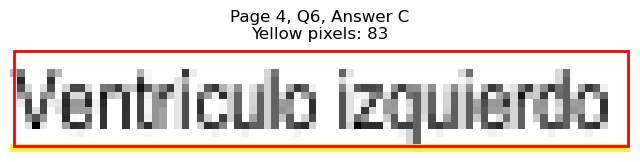

Page 4, Q6 - D: Detected box: x0=327.5, y0=430.2, x1=402.3, y1=442.9
Page 4, Q6, D: Yellow pixels: 726
Page 4, Q6, D: Total non-white pixels: 988
Page 4, Q6, D: Yellow percentage: 73.5%


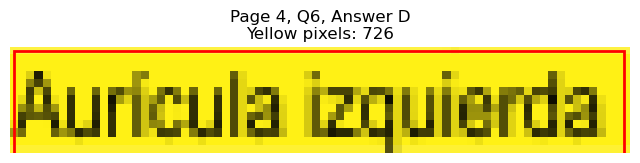


Page 4, Q6 - Selected Answer: D (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=146.5, y1=480.7
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 391
Page 4, Q7, A: Yellow percentage: 0.0%


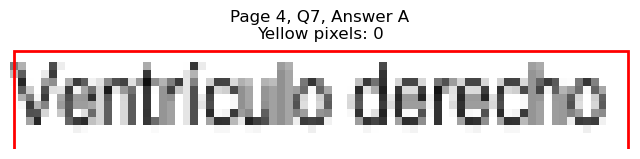

Page 4, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=137.5, y1=493.4
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 324
Page 4, Q7, B: Yellow percentage: 0.0%


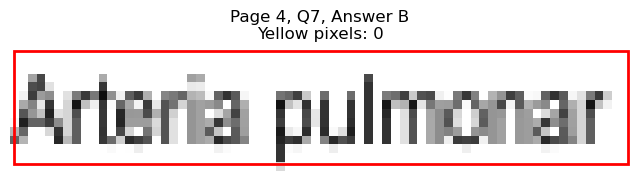

Page 4, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=402.8, y1=480.7
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 358
Page 4, Q7, C: Yellow percentage: 0.0%


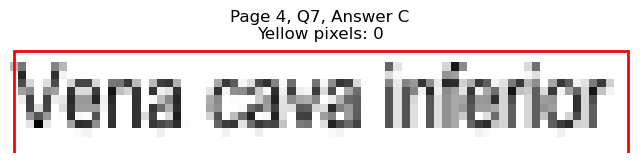

Page 4, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=393.8, y1=493.4
Page 4, Q7, D: Yellow pixels: 564
Page 4, Q7, D: Total non-white pixels: 938
Page 4, Q7, D: Yellow percentage: 60.1%


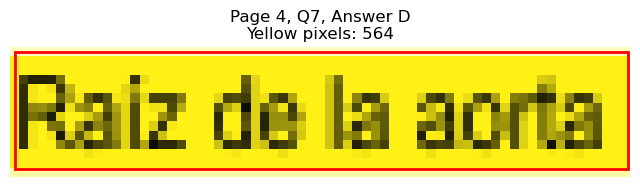


Page 4, Q7 - Selected Answer: D (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=531.2, x1=135.5, y1=543.8
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 347
Page 4, Q8, A: Yellow percentage: 0.0%


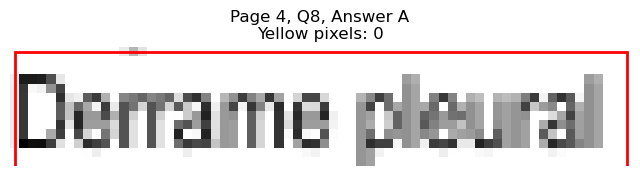

Page 4, Q8 - B: Detected box: x0=68.3, y0=543.8, x1=150.0, y1=556.4
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 396
Page 4, Q8, B: Yellow percentage: 0.0%


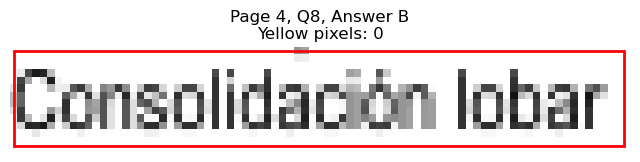

Page 4, Q8 - C: Detected box: x0=327.5, y0=531.2, x1=418.3, y1=543.8
Page 4, Q8, C: Yellow pixels: 832
Page 4, Q8, C: Total non-white pixels: 1196
Page 4, Q8, C: Yellow percentage: 69.6%


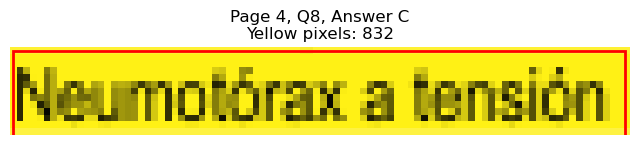

Page 4, Q8 - D: Detected box: x0=327.5, y0=543.8, x1=404.2, y1=556.4
Page 4, Q8, D: Yellow pixels: 78
Page 4, Q8, D: Total non-white pixels: 500
Page 4, Q8, D: Yellow percentage: 15.6%


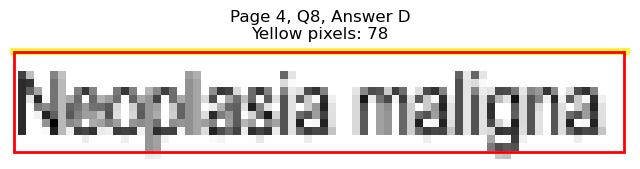


Page 4, Q8 - Selected Answer: C (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=594.3, x1=153.0, y1=607.0
Page 4, Q9, A: Yellow pixels: 790
Page 4, Q9, A: Total non-white pixels: 1118
Page 4, Q9, A: Yellow percentage: 70.7%


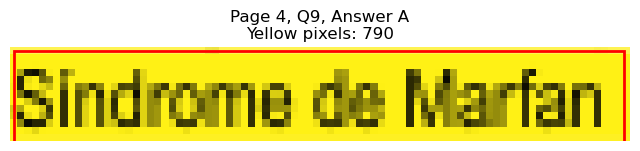

Page 4, Q9 - B: Detected box: x0=68.3, y0=606.9, x1=167.1, y1=619.6
Page 4, Q9, B: Yellow pixels: 100
Page 4, Q9, B: Total non-white pixels: 643
Page 4, Q9, B: Yellow percentage: 15.6%


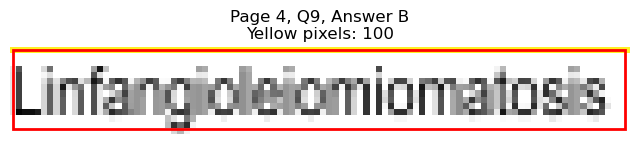

Page 4, Q9 - C: Detected box: x0=327.5, y0=594.3, x1=408.8, y1=607.0
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 410
Page 4, Q9, C: Yellow percentage: 0.0%


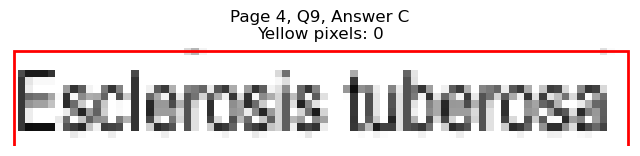

Page 4, Q9 - D: Detected box: x0=327.5, y0=606.9, x1=403.3, y1=619.6
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 391
Page 4, Q9, D: Yellow percentage: 0.0%


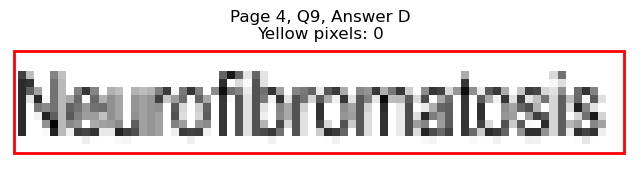


Page 4, Q9 - Selected Answer: A (based on yellow pixel count)




Page 4, Q10 - A: Detected box: x0=68.3, y0=657.5, x1=185.2, y1=670.1
Page 4, Q10, A: Yellow pixels: 0
Page 4, Q10, A: Total non-white pixels: 606
Page 4, Q10, A: Yellow percentage: 0.0%


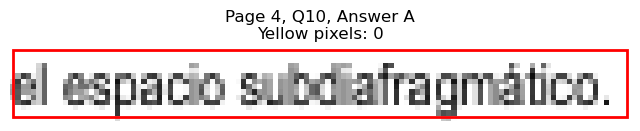

Page 4, Q10 - B: Detected box: x0=68.3, y0=670.1, x1=172.6, y1=682.7
Page 4, Q10, B: Yellow pixels: 0
Page 4, Q10, B: Total non-white pixels: 509
Page 4, Q10, B: Yellow percentage: 0.0%


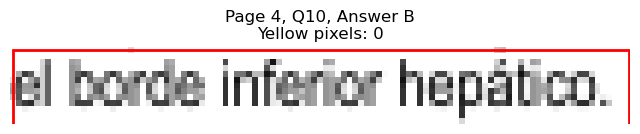

Page 4, Q10 - C: Detected box: x0=327.5, y0=657.5, x1=469.5, y1=670.1
Page 4, Q10, C: Yellow pixels: 143
Page 4, Q10, C: Total non-white pixels: 855
Page 4, Q10, C: Yellow percentage: 16.7%


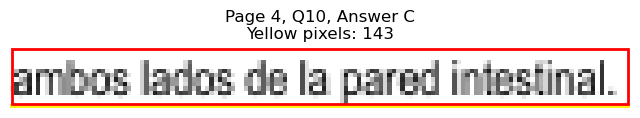

Page 4, Q10 - D: Detected box: x0=327.5, y0=670.1, x1=523.2, y1=682.7
Page 4, Q10, D: Yellow pixels: 1779
Page 4, Q10, D: Total non-white pixels: 2561
Page 4, Q10, D: Yellow percentage: 69.5%


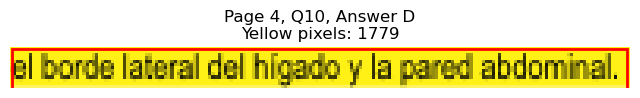


Page 4, Q10 - Selected Answer: D (based on yellow pixel count)




Page 4, Q11 - A: Detected box: x0=68.3, y0=720.6, x1=147.5, y1=733.2
Page 4, Q11, A: Yellow pixels: 80
Page 4, Q11, A: Total non-white pixels: 482
Page 4, Q11, A: Yellow percentage: 16.6%


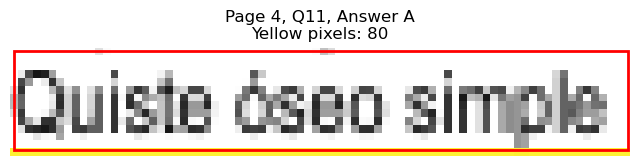

Page 4, Q11 - B: Detected box: x0=68.3, y0=733.2, x1=138.5, y1=745.8
Page 4, Q11, B: Yellow pixels: 623
Page 4, Q11, B: Total non-white pixels: 923
Page 4, Q11, B: Yellow percentage: 67.5%


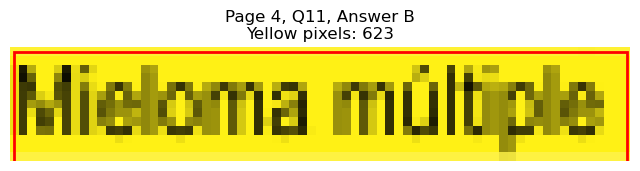

Page 4, Q11 - C: Detected box: x0=327.5, y0=720.6, x1=385.3, y1=733.2
Page 4, Q11, C: Yellow pixels: 0
Page 4, Q11, C: Total non-white pixels: 294
Page 4, Q11, C: Yellow percentage: 0.0%


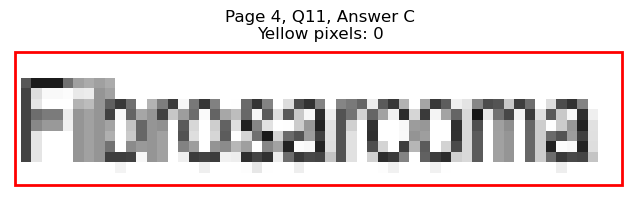

Page 4, Q11 - D: Detected box: x0=327.5, y0=733.2, x1=381.2, y1=745.8
Page 4, Q11, D: Yellow pixels: 0
Page 4, Q11, D: Total non-white pixels: 276
Page 4, Q11, D: Yellow percentage: 0.0%


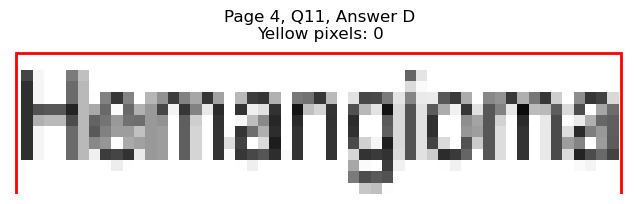


Page 4, Q11 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 12 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=123.0, y1=114.7
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 280
Page 5, Q1, A: Yellow percentage: 0.0%


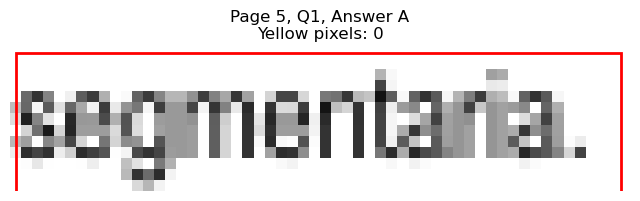

Page 5, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=158.5, y1=127.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 461
Page 5, Q1, B: Yellow percentage: 0.0%


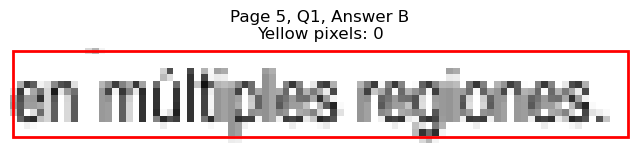

Page 5, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=353.6, y1=114.7
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 135
Page 5, Q1, C: Yellow percentage: 0.0%


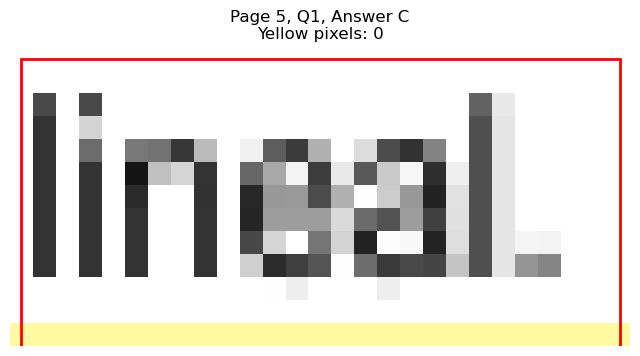

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=364.6, y1=127.3
Page 5, Q1, D: Yellow pixels: 332
Page 5, Q1, D: Total non-white pixels: 532
Page 5, Q1, D: Yellow percentage: 62.4%


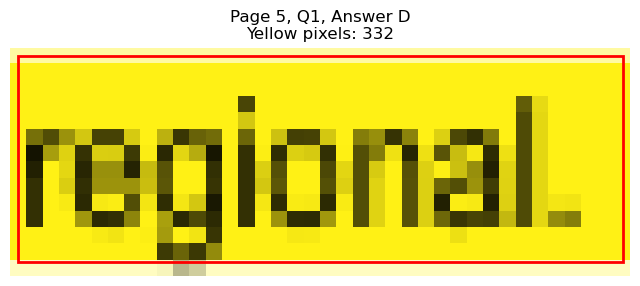


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=181.7, y1=165.2
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 584
Page 5, Q2, A: Yellow percentage: 0.0%


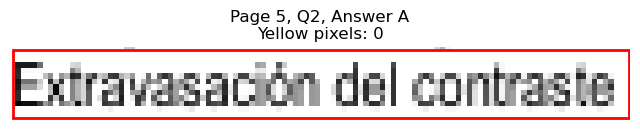

Page 5, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=139.0, y1=177.8
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 340
Page 5, Q2, B: Yellow percentage: 0.0%


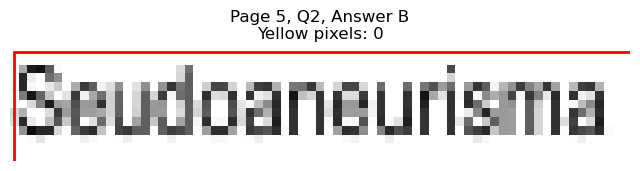

Page 5, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=418.9, y1=165.2
Page 5, Q2, C: Yellow pixels: 829
Page 5, Q2, C: Total non-white pixels: 1288
Page 5, Q2, C: Yellow percentage: 64.4%


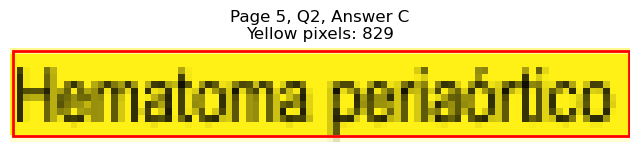

Page 5, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=409.7, y1=177.8
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 501
Page 5, Q2, D: Yellow percentage: 0.0%


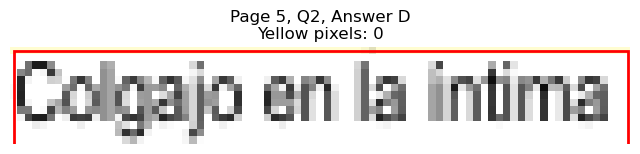


Page 5, Q2 - Selected Answer: C (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=94.9, y1=228.3
Page 5, Q3, A: Yellow pixels: 27
Page 5, Q3, A: Total non-white pixels: 147
Page 5, Q3, A: Yellow percentage: 18.4%


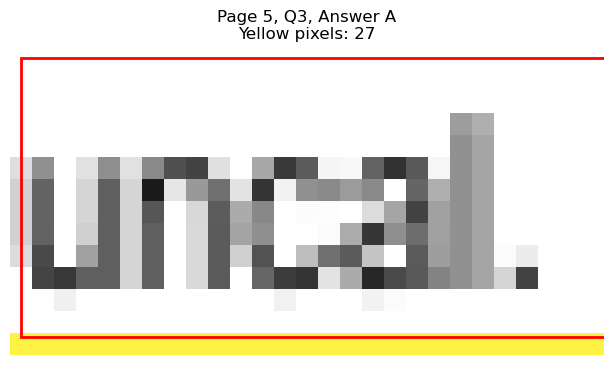

Page 5, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=113.9, y1=240.9
Page 5, Q3, B: Yellow pixels: 414
Page 5, Q3, B: Total non-white pixels: 598
Page 5, Q3, B: Yellow percentage: 69.2%


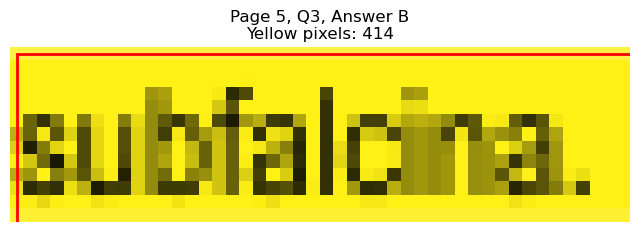

Page 5, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=384.8, y1=228.3
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 302
Page 5, Q3, C: Yellow percentage: 0.0%


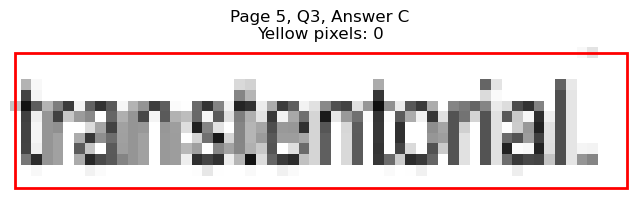

Page 5, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=381.2, y1=240.9
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 284
Page 5, Q3, D: Yellow percentage: 0.0%


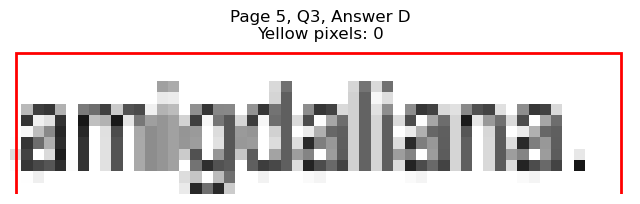


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=115.5, y1=291.5
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 243
Page 5, Q4, A: Yellow percentage: 0.0%


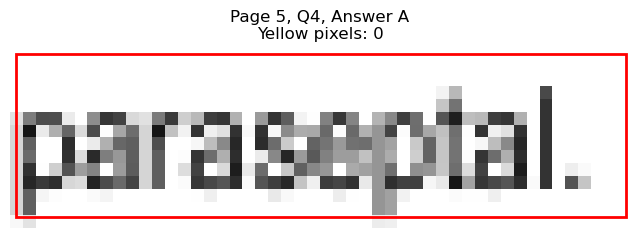

Page 5, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=131.5, y1=304.1
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 285
Page 5, Q4, B: Yellow percentage: 0.0%


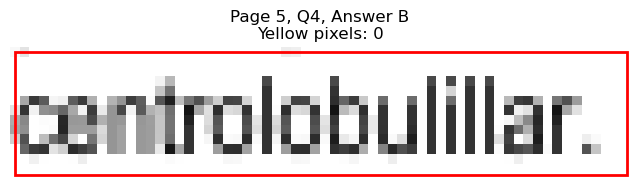

Page 5, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=380.7, y1=291.5
Page 5, Q4, C: Yellow pixels: 520
Page 5, Q4, C: Total non-white pixels: 756
Page 5, Q4, C: Yellow percentage: 68.8%


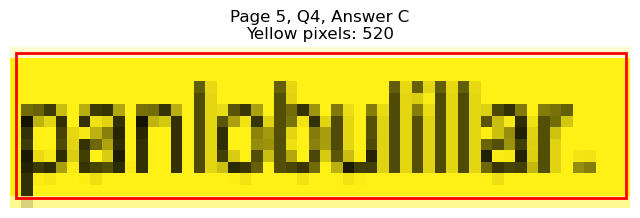

Page 5, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=371.7, y1=304.1
Page 5, Q4, D: Yellow pixels: 45
Page 5, Q4, D: Total non-white pixels: 264
Page 5, Q4, D: Yellow percentage: 17.0%


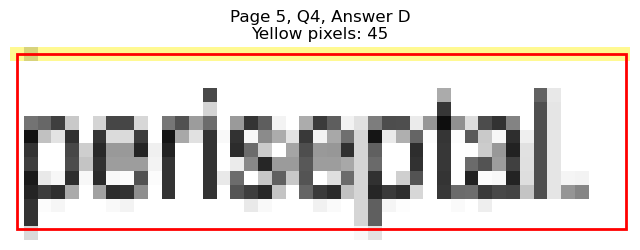


Page 5, Q4 - Selected Answer: C (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=175.6, y1=341.9
Page 5, Q5, A: Yellow pixels: 978
Page 5, Q5, A: Total non-white pixels: 1404
Page 5, Q5, A: Yellow percentage: 69.7%


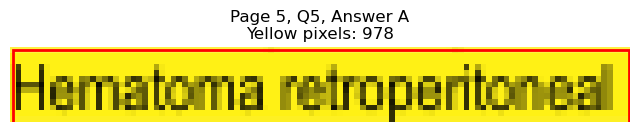

Page 5, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=260.4, y1=354.6
Page 5, Q5, B: Yellow pixels: 192
Page 5, Q5, B: Total non-white pixels: 1160
Page 5, Q5, B: Yellow percentage: 16.6%


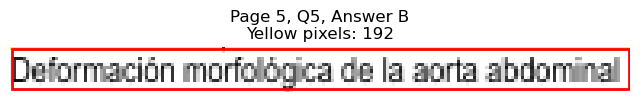

Page 5, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=487.1, y1=341.9
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 763
Page 5, Q5, C: Yellow percentage: 0.0%


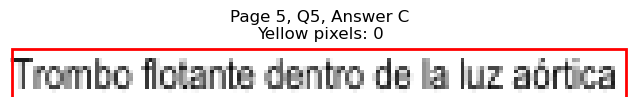

Page 5, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=487.1, y1=354.6
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 787
Page 5, Q5, D: Yellow percentage: 0.0%


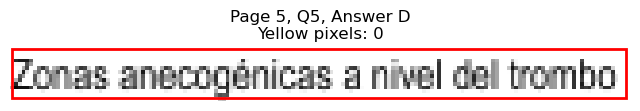


Page 5, Q5 - Selected Answer: A (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=379.7, x1=119.4, y1=392.4
Page 5, Q6, A: Yellow pixels: 403
Page 5, Q6, A: Total non-white pixels: 728
Page 5, Q6, A: Yellow percentage: 55.4%


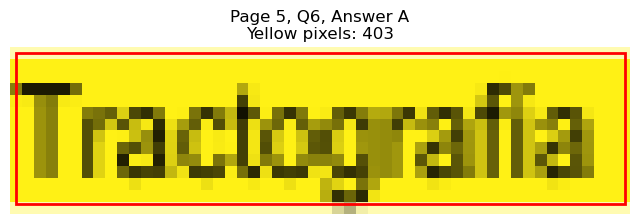

Page 5, Q6 - B: Detected box: x0=68.3, y0=392.3, x1=109.9, y1=405.0
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 222
Page 5, Q6, B: Yellow percentage: 0.0%


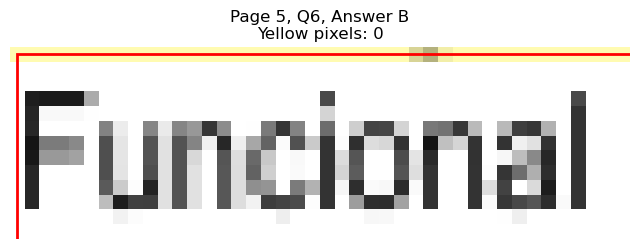

Page 5, Q6 - C: Detected box: x0=327.5, y0=379.7, x1=368.2, y1=392.4
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 210
Page 5, Q6, C: Yellow percentage: 0.0%


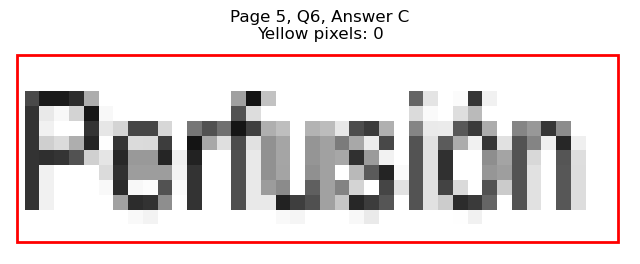

Page 5, Q6 - D: Detected box: x0=327.5, y0=392.3, x1=392.2, y1=405.0
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 330
Page 5, Q6, D: Yellow percentage: 0.0%


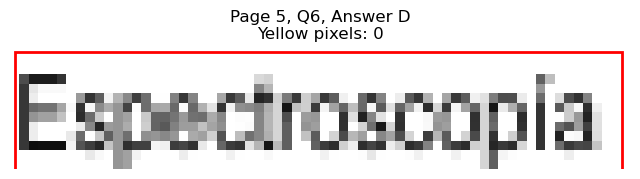


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=229.4, y1=455.5
Page 5, Q7, A: Yellow pixels: 1499
Page 5, Q7, A: Total non-white pixels: 2268
Page 5, Q7, A: Yellow percentage: 66.1%


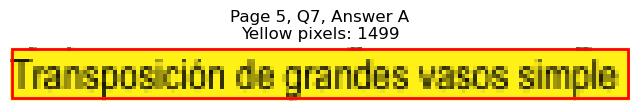

Page 5, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=154.1, y1=468.1
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 433
Page 5, Q7, B: Yellow percentage: 0.0%


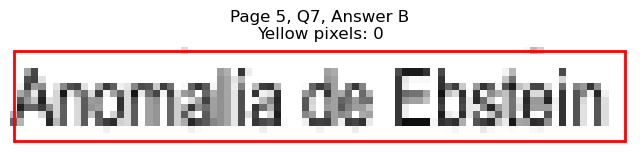

Page 5, Q7 - C: Detected box: x0=327.5, y0=442.8, x1=445.9, y1=455.5
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 624
Page 5, Q7, C: Yellow percentage: 0.0%


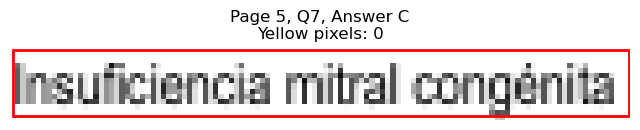

Page 5, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=407.8, y1=468.1
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 406
Page 5, Q7, D: Yellow percentage: 0.0%


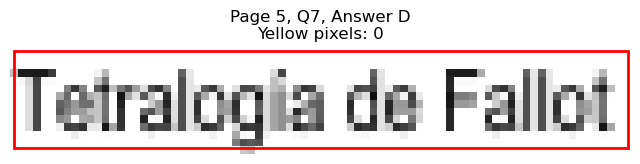


Page 5, Q7 - Selected Answer: A (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=506.0, x1=173.2, y1=518.6
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 561
Page 5, Q8, A: Yellow percentage: 0.0%


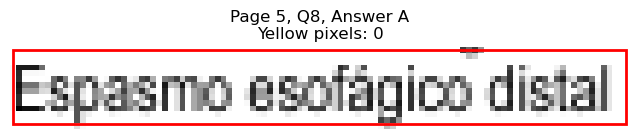

Page 5, Q8 - B: Detected box: x0=68.3, y0=518.6, x1=158.1, y1=531.2
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 497
Page 5, Q8, B: Yellow percentage: 0.0%


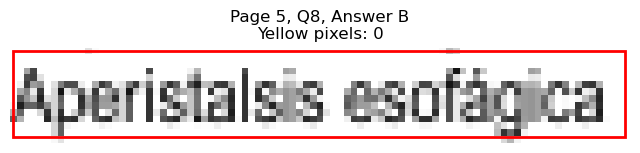

Page 5, Q8 - C: Detected box: x0=327.5, y0=506.0, x1=364.1, y1=518.6
Page 5, Q8, C: Yellow pixels: 347
Page 5, Q8, C: Total non-white pixels: 532
Page 5, Q8, C: Yellow percentage: 65.2%


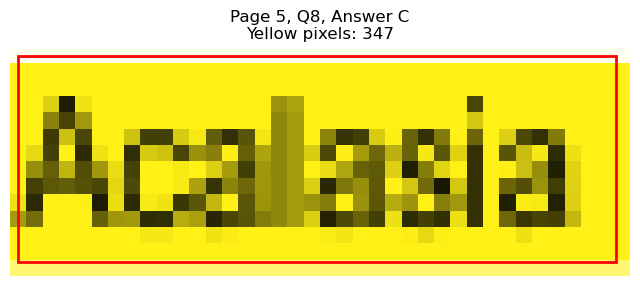

Page 5, Q8 - D: Detected box: x0=327.5, y0=518.6, x1=380.7, y1=531.2
Page 5, Q8, D: Yellow pixels: 54
Page 5, Q8, D: Total non-white pixels: 336
Page 5, Q8, D: Yellow percentage: 16.1%


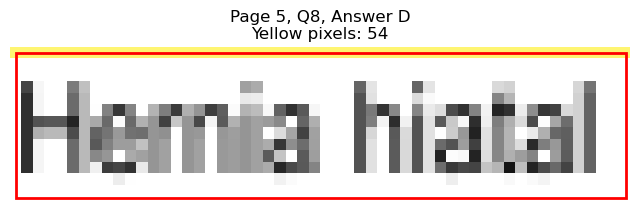


Page 5, Q8 - Selected Answer: C (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=569.1, x1=135.0, y1=581.8
Page 5, Q9, A: Yellow pixels: 0
Page 5, Q9, A: Total non-white pixels: 377
Page 5, Q9, A: Yellow percentage: 0.0%


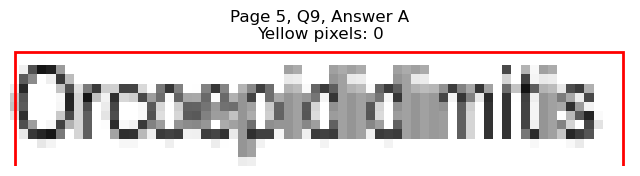

Page 5, Q9 - B: Detected box: x0=68.3, y0=581.7, x1=135.0, y1=594.4
Page 5, Q9, B: Yellow pixels: 0
Page 5, Q9, B: Total non-white pixels: 323
Page 5, Q9, B: Yellow percentage: 0.0%


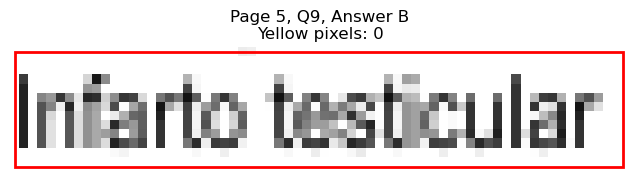

Page 5, Q9 - C: Detected box: x0=327.5, y0=569.1, x1=408.8, y1=581.8
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 514
Page 5, Q9, C: Yellow percentage: 0.0%


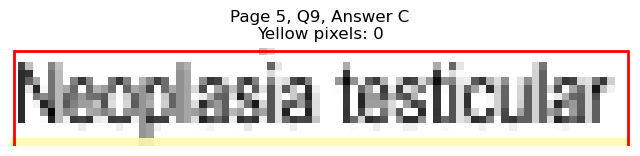

Page 5, Q9 - D: Detected box: x0=327.5, y0=581.7, x1=398.7, y1=594.4
Page 5, Q9, D: Yellow pixels: 599
Page 5, Q9, D: Total non-white pixels: 1008
Page 5, Q9, D: Yellow percentage: 59.4%


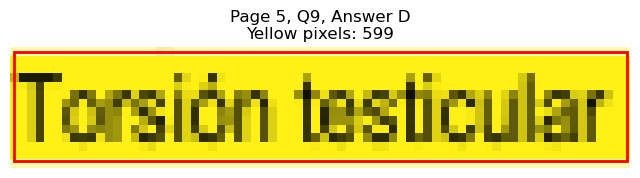


Page 5, Q9 - Selected Answer: D (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=68.3, y0=619.6, x1=101.4, y1=632.3
Page 5, Q10, A: Yellow pixels: 322
Page 5, Q10, A: Total non-white pixels: 476
Page 5, Q10, A: Yellow percentage: 67.6%


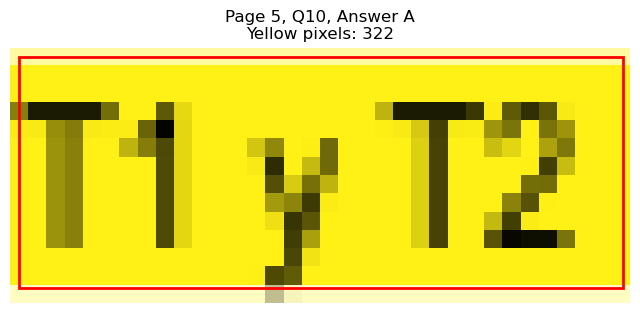

Page 5, Q10 - B: Detected box: x0=68.3, y0=632.2, x1=81.4, y1=644.9
Page 5, Q10, B: Yellow pixels: 0
Page 5, Q10, B: Total non-white pixels: 55
Page 5, Q10, B: Yellow percentage: 0.0%


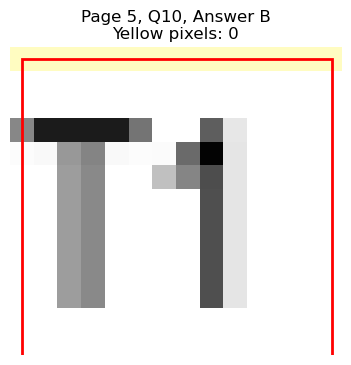

Page 5, Q10 - C: Detected box: x0=327.5, y0=619.6, x1=340.6, y1=632.3
Page 5, Q10, C: Yellow pixels: 0
Page 5, Q10, C: Total non-white pixels: 48
Page 5, Q10, C: Yellow percentage: 0.0%


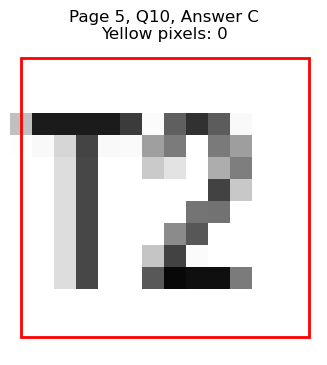

Page 5, Q10 - D: Detected box: x0=327.5, y0=632.2, x1=397.3, y1=644.9
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 310
Page 5, Q10, D: Yellow percentage: 0.0%


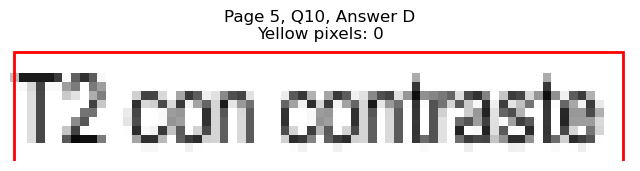


Page 5, Q10 - Selected Answer: A (based on yellow pixel count)




Page 5, Q11 - A: Detected box: x0=68.3, y0=682.7, x1=148.1, y1=695.3
Page 5, Q11, A: Yellow pixels: 692
Page 5, Q11, A: Total non-white pixels: 1134
Page 5, Q11, A: Yellow percentage: 61.0%


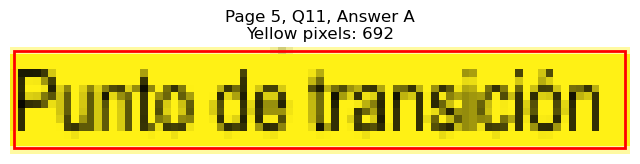

Page 5, Q11 - B: Detected box: x0=68.3, y0=695.4, x1=150.5, y1=708.0
Page 5, Q11, B: Yellow pixels: 0
Page 5, Q11, B: Total non-white pixels: 495
Page 5, Q11, B: Yellow percentage: 0.0%


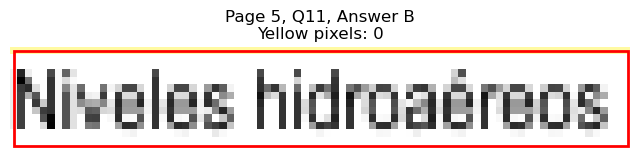

Page 5, Q11 - C: Detected box: x0=327.5, y0=682.7, x1=406.3, y1=695.3
Page 5, Q11, C: Yellow pixels: 0
Page 5, Q11, C: Total non-white pixels: 379
Page 5, Q11, C: Yellow percentage: 0.0%


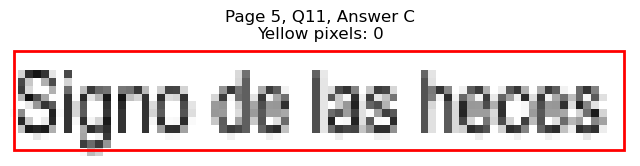

Page 5, Q11 - D: Detected box: x0=327.5, y0=695.4, x1=397.3, y1=708.0
Page 5, Q11, D: Yellow pixels: 0
Page 5, Q11, D: Total non-white pixels: 357
Page 5, Q11, D: Yellow percentage: 0.0%


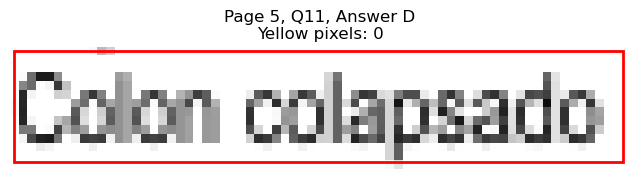


Page 5, Q11 - Selected Answer: A (based on yellow pixel count)




Page 5, Q12 - A: Detected box: x0=68.3, y0=733.2, x1=151.1, y1=745.8
Page 5, Q12, A: Yellow pixels: 0
Page 5, Q12, A: Total non-white pixels: 380
Page 5, Q12, A: Yellow percentage: 0.0%


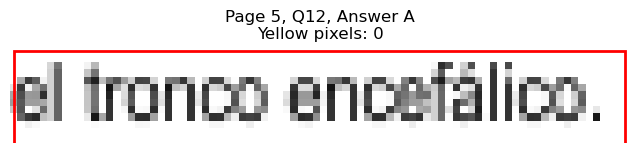

Page 5, Q12 - B: Detected box: x0=68.3, y0=745.8, x1=117.5, y1=758.4
Page 5, Q12, B: Yellow pixels: 0
Page 5, Q12, B: Total non-white pixels: 229
Page 5, Q12, B: Yellow percentage: 0.0%


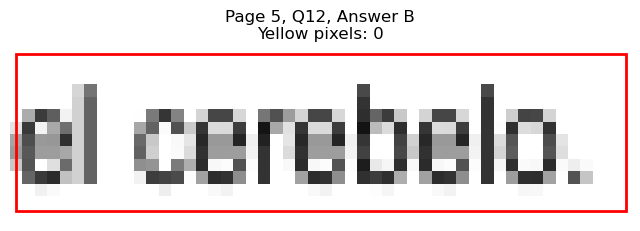

Page 5, Q12 - C: Detected box: x0=327.5, y0=733.2, x1=487.5, y1=745.8
Page 5, Q12, C: Yellow pixels: 1499
Page 5, Q12, C: Total non-white pixels: 2093
Page 5, Q12, C: Yellow percentage: 71.6%


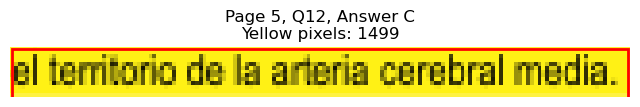

Page 5, Q12 - D: Detected box: x0=327.5, y0=745.8, x1=403.7, y1=758.4
Page 5, Q12, D: Yellow pixels: 77
Page 5, Q12, D: Total non-white pixels: 439
Page 5, Q12, D: Yellow percentage: 17.5%


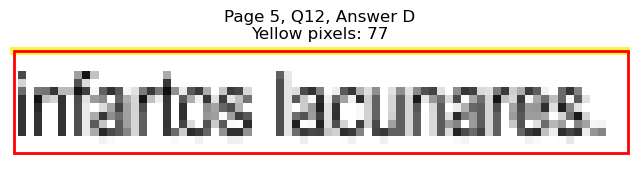


Page 5, Q12 - Selected Answer: C (based on yellow pixel count)





Page 6: Found 11 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=98.4, y1=114.7
Page 6, Q1, A: Yellow pixels: 282
Page 6, Q1, A: Total non-white pixels: 403
Page 6, Q1, A: Yellow percentage: 70.0%


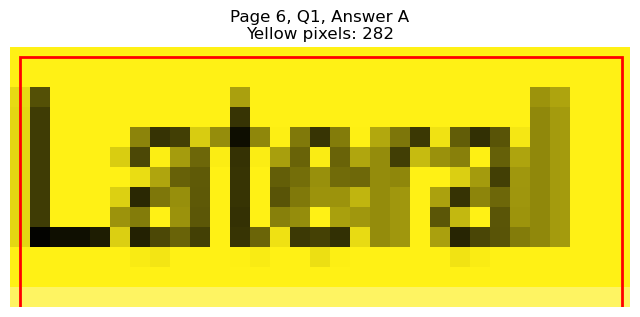

Page 6, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=98.9, y1=127.3
Page 6, Q1, B: Yellow pixels: 31
Page 6, Q1, B: Total non-white pixels: 167
Page 6, Q1, B: Yellow percentage: 18.6%


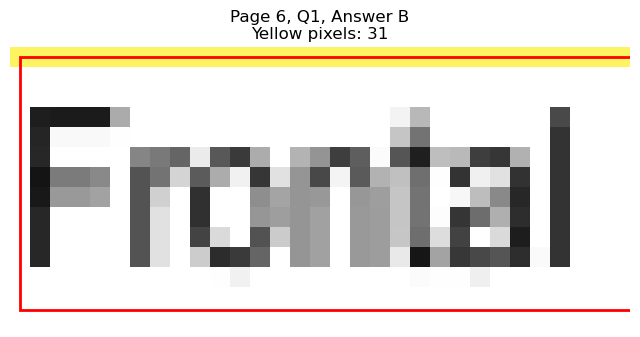

Page 6, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=374.2, y1=114.7
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 250
Page 6, Q1, C: Yellow percentage: 0.0%


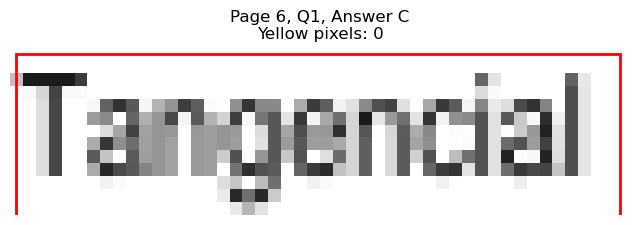

Page 6, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=365.7, y1=127.3
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 199
Page 6, Q1, D: Yellow percentage: 0.0%


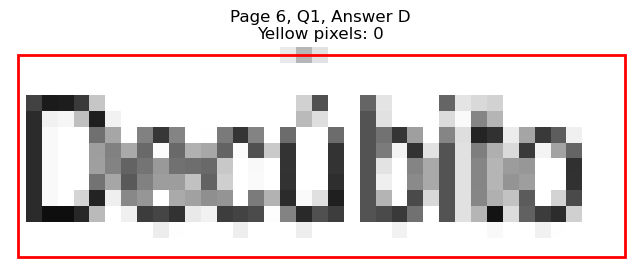


Page 6, Q1 - Selected Answer: A (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=172.1, y1=177.8
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 509
Page 6, Q2, A: Yellow percentage: 0.0%


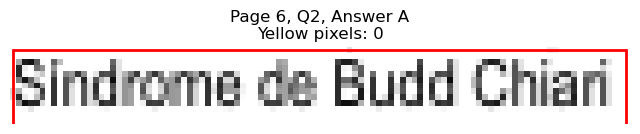

Page 6, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=105.9, y1=190.4
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 211
Page 6, Q2, B: Yellow percentage: 0.0%


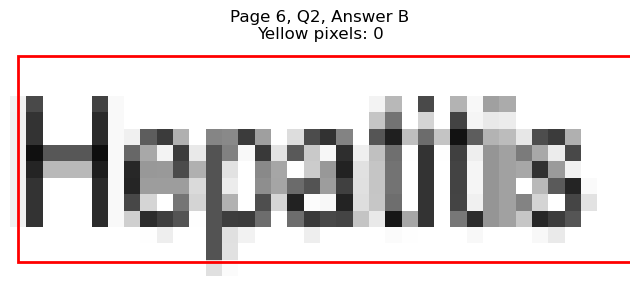

Page 6, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=412.3, y1=177.8
Page 6, Q2, C: Yellow pixels: 758
Page 6, Q2, C: Total non-white pixels: 1118
Page 6, Q2, C: Yellow percentage: 67.8%


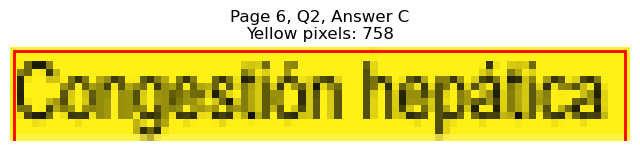

Page 6, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=397.3, y1=190.4
Page 6, Q2, D: Yellow pixels: 70
Page 6, Q2, D: Total non-white pixels: 445
Page 6, Q2, D: Yellow percentage: 15.7%


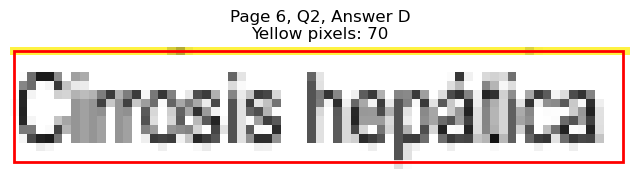


Page 6, Q2 - Selected Answer: C (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=148.1, y1=228.3
Page 6, Q3, A: Yellow pixels: 671
Page 6, Q3, A: Total non-white pixels: 1134
Page 6, Q3, A: Yellow percentage: 59.2%


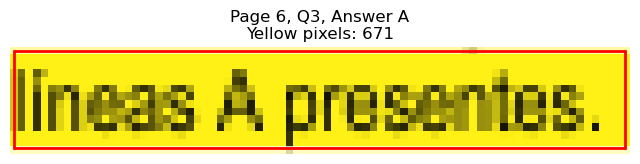

Page 6, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=266.9, y1=240.9
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 1156
Page 6, Q3, B: Yellow percentage: 0.0%


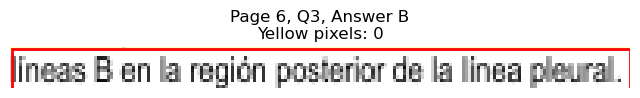

Page 6, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=452.0, y1=228.3
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 645
Page 6, Q3, C: Yellow percentage: 0.0%


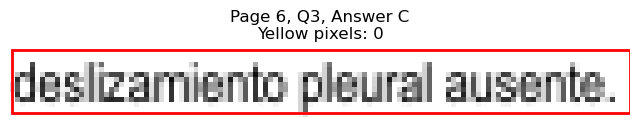

Page 6, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=404.3, y1=240.9
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 363
Page 6, Q3, D: Yellow percentage: 0.0%


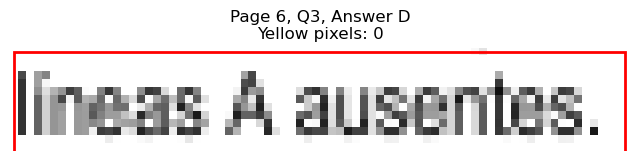


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=266.1, x1=163.6, y1=278.7
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 444
Page 6, Q4, A: Yellow percentage: 0.0%


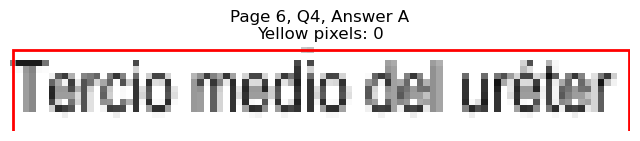

Page 6, Q4 - B: Detected box: x0=68.3, y0=278.8, x1=146.5, y1=291.5
Page 6, Q4, B: Yellow pixels: 732
Page 6, Q4, B: Total non-white pixels: 1106
Page 6, Q4, B: Yellow percentage: 66.2%


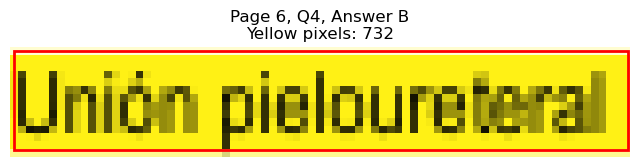

Page 6, Q4 - C: Detected box: x0=327.5, y0=266.1, x1=378.7, y1=278.7
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 274
Page 6, Q4, C: Yellow percentage: 0.0%


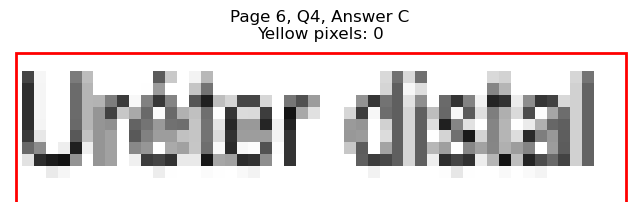

Page 6, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=412.3, y1=291.5
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 445
Page 6, Q4, D: Yellow percentage: 0.0%


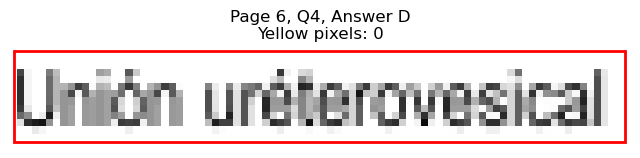


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=97.5, y1=341.9
Page 6, Q5, A: Yellow pixels: 278
Page 6, Q5, A: Total non-white pixels: 390
Page 6, Q5, A: Yellow percentage: 71.3%


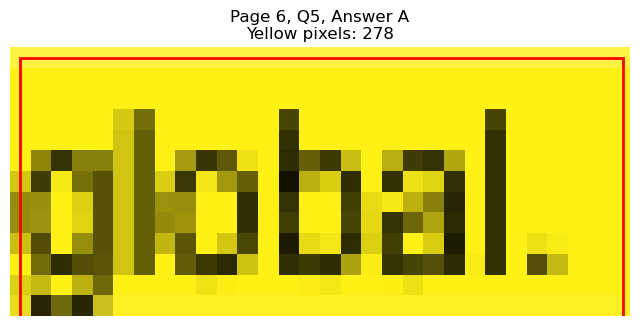

Page 6, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=92.4, y1=354.6
Page 6, Q5, B: Yellow pixels: 21
Page 6, Q5, B: Total non-white pixels: 123
Page 6, Q5, B: Yellow percentage: 17.1%


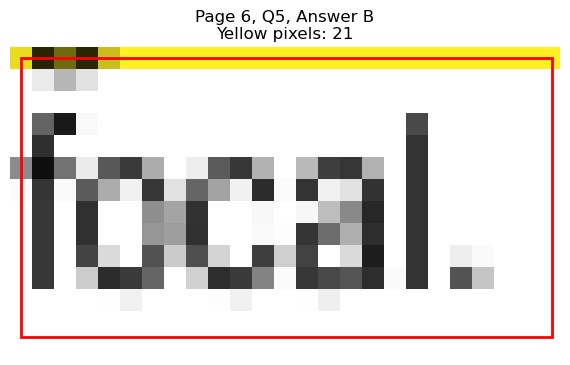

Page 6, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=384.8, y1=341.9
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 273
Page 6, Q5, C: Yellow percentage: 0.0%


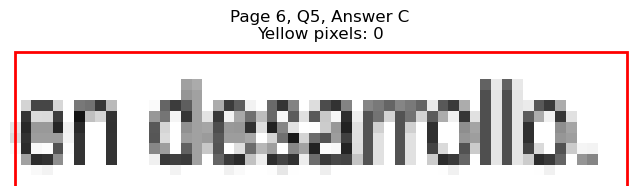

Page 6, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=359.7, y1=354.6
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 149
Page 6, Q5, D: Yellow percentage: 0.0%


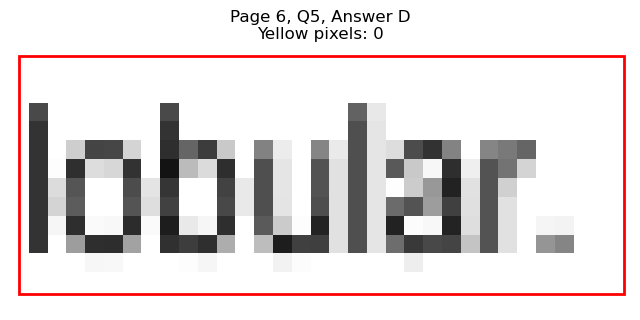


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=404.9, x1=124.5, y1=417.6
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 281
Page 6, Q6, A: Yellow percentage: 0.0%


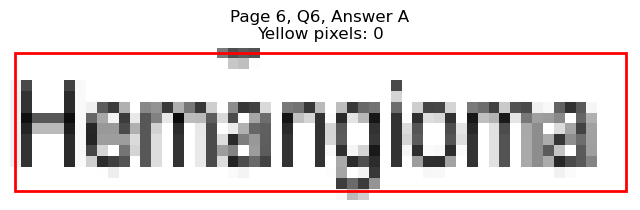

Page 6, Q6 - B: Detected box: x0=68.3, y0=417.6, x1=109.5, y1=430.3
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 210
Page 6, Q6, B: Yellow percentage: 0.0%


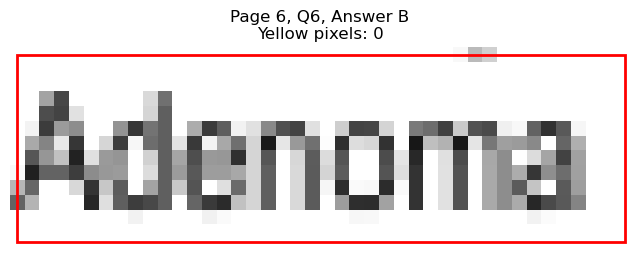

Page 6, Q6 - C: Detected box: x0=327.5, y0=404.9, x1=400.7, y1=417.6
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 377
Page 6, Q6, C: Yellow percentage: 0.0%


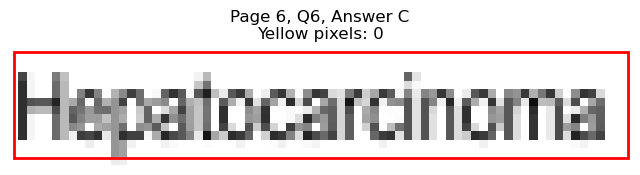

Page 6, Q6 - D: Detected box: x0=327.5, y0=417.6, x1=429.3, y1=430.3
Page 6, Q6, D: Yellow pixels: 797
Page 6, Q6, D: Total non-white pixels: 1442
Page 6, Q6, D: Yellow percentage: 55.3%


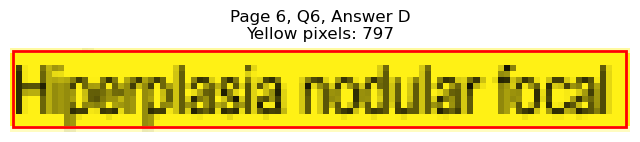


Page 6, Q6 - Selected Answer: D (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=468.1, x1=111.5, y1=480.7
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 219
Page 6, Q7, A: Yellow percentage: 0.0%


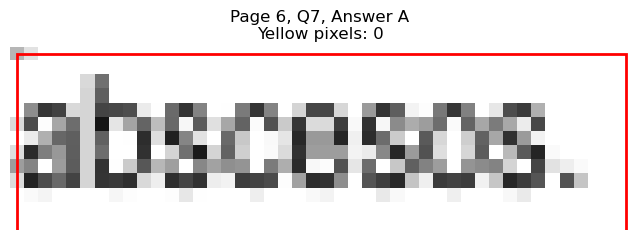

Page 6, Q7 - B: Detected box: x0=68.3, y0=480.8, x1=115.5, y1=493.4
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 223
Page 6, Q7, B: Yellow percentage: 0.0%


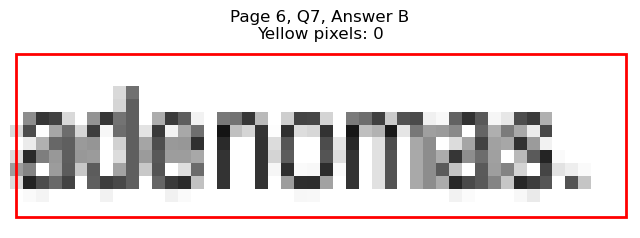

Page 6, Q7 - C: Detected box: x0=327.5, y0=468.1, x1=375.7, y1=480.7
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 241
Page 6, Q7, C: Yellow percentage: 0.0%


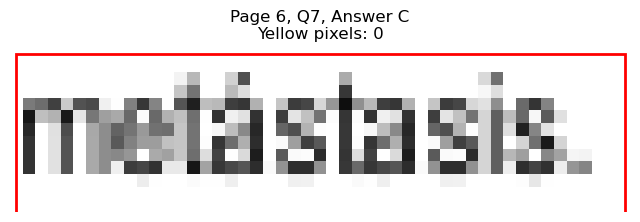

Page 6, Q7 - D: Detected box: x0=327.5, y0=480.8, x1=361.1, y1=493.4
Page 6, Q7, D: Yellow pixels: 298
Page 6, Q7, D: Total non-white pixels: 490
Page 6, Q7, D: Yellow percentage: 60.8%


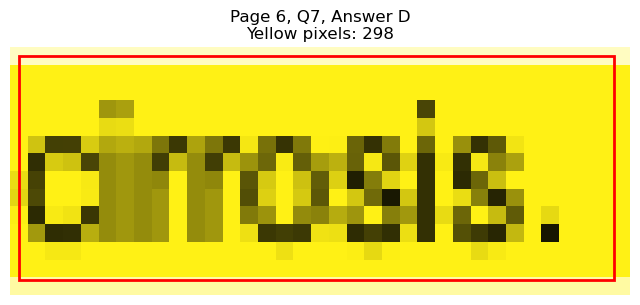


Page 6, Q7 - Selected Answer: D (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=531.2, x1=248.8, y1=543.8
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 871
Page 6, Q8, A: Yellow percentage: 0.0%


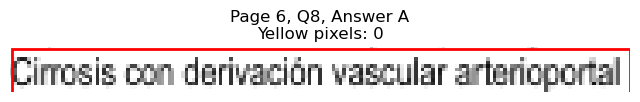

Page 6, Q8 - B: Detected box: x0=68.3, y0=543.8, x1=138.0, y1=556.4
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 336
Page 6, Q8, B: Yellow percentage: 0.0%


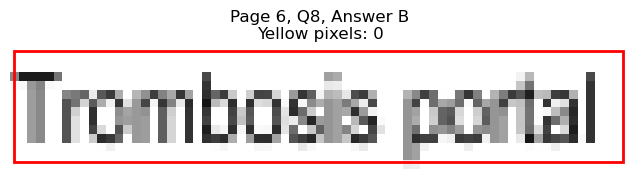

Page 6, Q8 - C: Detected box: x0=327.5, y0=531.2, x1=456.9, y1=543.8
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 782
Page 6, Q8, C: Yellow percentage: 0.0%


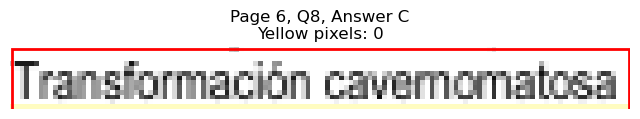

Page 6, Q8 - D: Detected box: x0=327.5, y0=543.8, x1=430.9, y1=556.4
Page 6, Q8, D: Yellow pixels: 912
Page 6, Q8, D: Total non-white pixels: 1456
Page 6, Q8, D: Yellow percentage: 62.6%


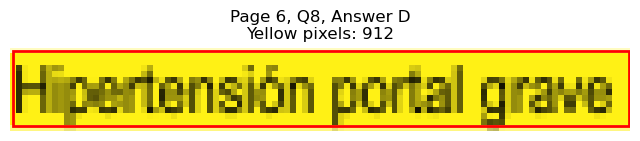


Page 6, Q8 - Selected Answer: D (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=594.3, x1=137.5, y1=607.0
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 354
Page 6, Q9, A: Yellow percentage: 0.0%


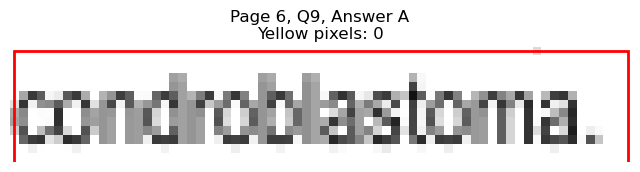

Page 6, Q9 - B: Detected box: x0=68.3, y0=606.9, x1=160.1, y1=619.6
Page 6, Q9, B: Yellow pixels: 0
Page 6, Q9, B: Total non-white pixels: 446
Page 6, Q9, B: Yellow percentage: 0.0%


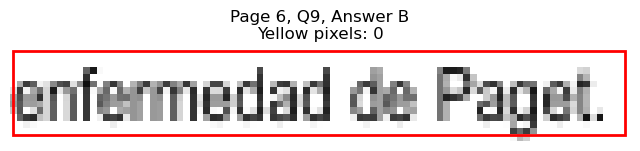

Page 6, Q9 - C: Detected box: x0=327.5, y0=594.3, x1=389.2, y1=607.0
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 363
Page 6, Q9, C: Yellow percentage: 0.0%


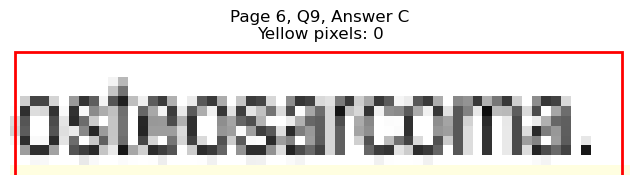

Page 6, Q9 - D: Detected box: x0=327.5, y0=606.9, x1=437.3, y1=619.6
Page 6, Q9, D: Yellow pixels: 1031
Page 6, Q9, D: Total non-white pixels: 1554
Page 6, Q9, D: Yellow percentage: 66.3%


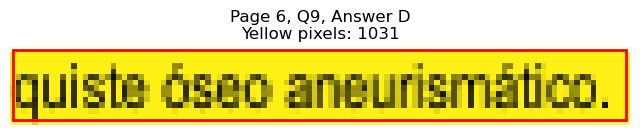


Page 6, Q9 - Selected Answer: D (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=657.5, x1=115.0, y1=670.1
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 232
Page 6, Q10, A: Yellow percentage: 0.0%


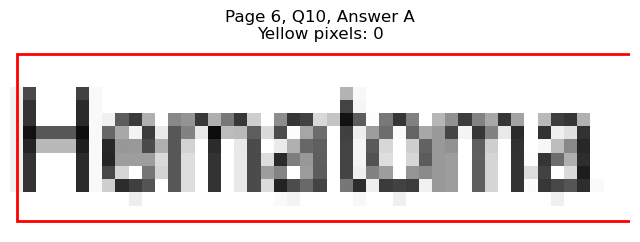

Page 6, Q10 - B: Detected box: x0=68.3, y0=670.1, x1=111.5, y1=682.7
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 222
Page 6, Q10, B: Yellow percentage: 0.0%


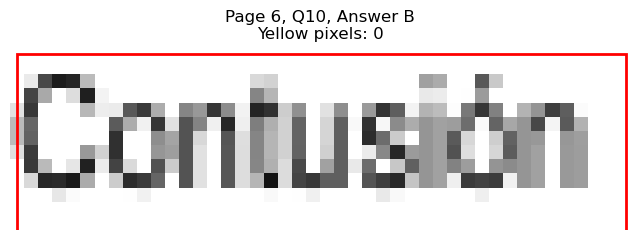

Page 6, Q10 - C: Detected box: x0=327.5, y0=657.5, x1=374.2, y1=670.1
Page 6, Q10, C: Yellow pixels: 459
Page 6, Q10, C: Total non-white pixels: 672
Page 6, Q10, C: Yellow percentage: 68.3%


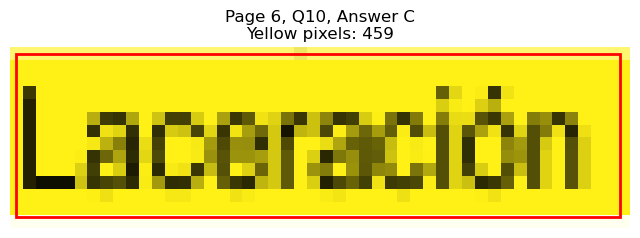

Page 6, Q10 - D: Detected box: x0=327.5, y0=670.1, x1=355.6, y1=682.7
Page 6, Q10, D: Yellow pixels: 0
Page 6, Q10, D: Total non-white pixels: 171
Page 6, Q10, D: Yellow percentage: 0.0%


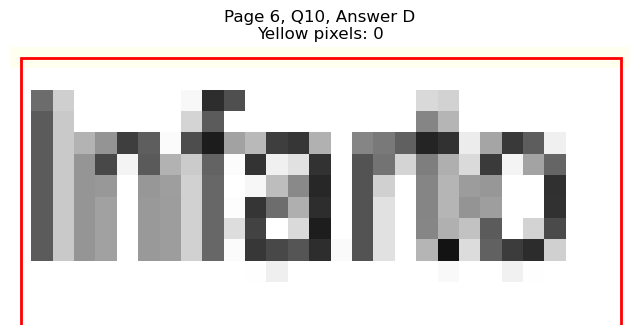


Page 6, Q10 - Selected Answer: C (based on yellow pixel count)




Page 6, Q11 - A: Detected box: x0=68.3, y0=720.6, x1=76.8, y1=733.2
Page 6, Q11, A: Yellow pixels: 92
Page 6, Q11, A: Total non-white pixels: 126
Page 6, Q11, A: Yellow percentage: 73.0%


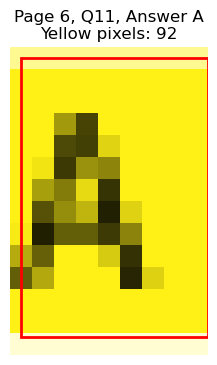

Page 6, Q11 - B: Detected box: x0=68.3, y0=733.2, x1=76.8, y1=745.8
Page 6, Q11, B: Yellow pixels: 0
Page 6, Q11, B: Total non-white pixels: 50
Page 6, Q11, B: Yellow percentage: 0.0%


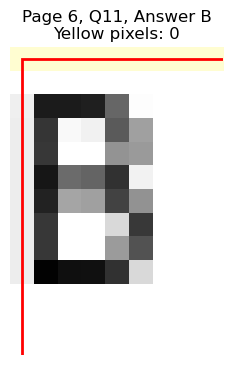

Page 6, Q11 - C: Detected box: x0=327.5, y0=720.6, x1=336.5, y1=733.2
Page 6, Q11, C: Yellow pixels: 0
Page 6, Q11, C: Total non-white pixels: 33
Page 6, Q11, C: Yellow percentage: 0.0%


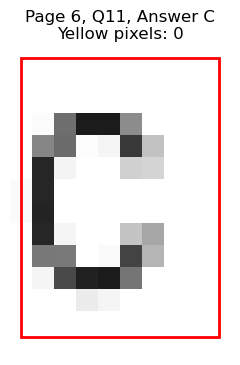

Page 6, Q11 - D: Detected box: x0=327.5, y0=733.2, x1=336.5, y1=745.8
Page 6, Q11, D: Yellow pixels: 0
Page 6, Q11, D: Total non-white pixels: 37
Page 6, Q11, D: Yellow percentage: 0.0%


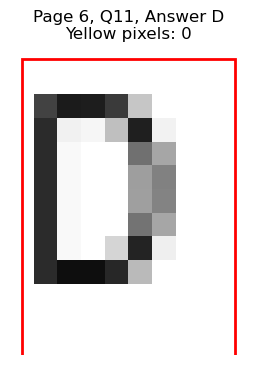


Page 6, Q11 - Selected Answer: A (based on yellow pixel count)





Page 7: Found 12 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=146.1, y1=127.3
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 388
Page 7, Q1, A: Yellow percentage: 0.0%


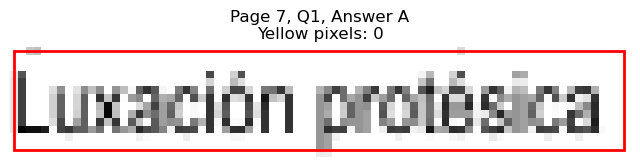

Page 7, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=109.9, y1=139.9
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 224
Page 7, Q1, B: Yellow percentage: 0.0%


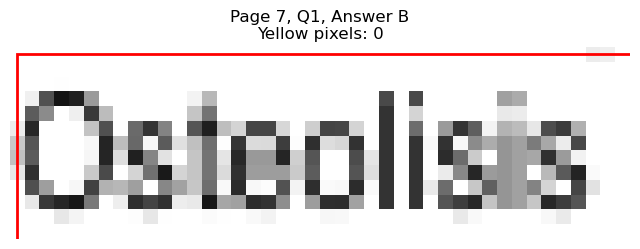

Page 7, Q1 - C: Detected box: x0=327.5, y0=114.6, x1=426.3, y1=127.3
Page 7, Q1, C: Yellow pixels: 795
Page 7, Q1, C: Total non-white pixels: 1400
Page 7, Q1, C: Yellow percentage: 56.8%


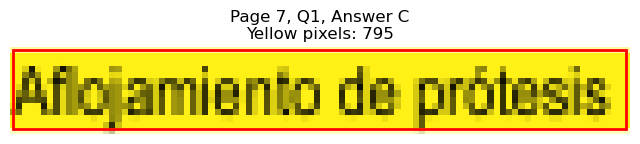

Page 7, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=360.7, y1=139.9
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 199
Page 7, Q1, D: Yellow percentage: 0.0%


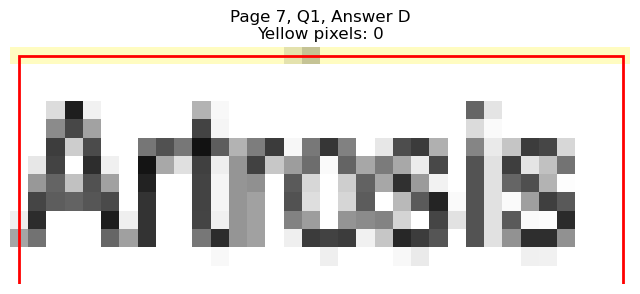


Page 7, Q1 - Selected Answer: C (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=110.9, y1=177.8
Page 7, Q2, A: Yellow pixels: 380
Page 7, Q2, A: Total non-white pixels: 559
Page 7, Q2, A: Yellow percentage: 68.0%


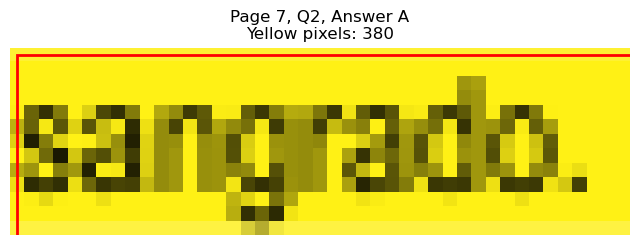

Page 7, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=182.7, y1=190.4
Page 7, Q2, B: Yellow pixels: 114
Page 7, Q2, B: Total non-white pixels: 673
Page 7, Q2, B: Yellow percentage: 16.9%


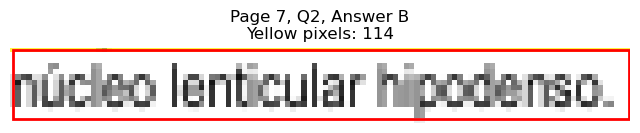

Page 7, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=467.5, y1=177.8
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 718
Page 7, Q2, C: Yellow percentage: 0.0%


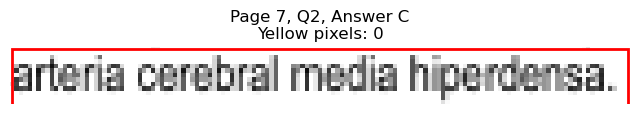

Page 7, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=400.3, y1=190.4
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 346
Page 7, Q2, D: Yellow percentage: 0.0%


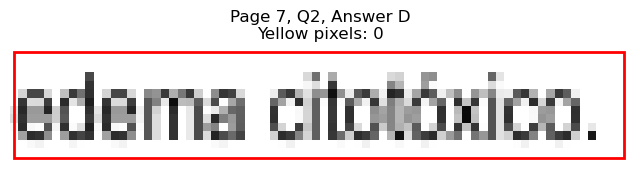


Page 7, Q2 - Selected Answer: A (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=56.6, y0=228.3, x1=65.2, y1=240.9
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 45
Page 7, Q3, A: Yellow percentage: 0.0%


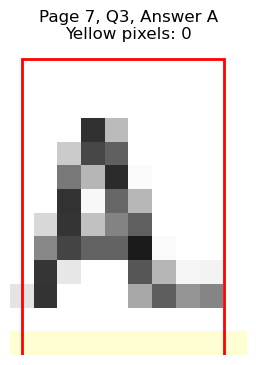

Page 7, Q3 - B: Detected box: x0=56.6, y0=240.9, x1=65.2, y1=253.5
Page 7, Q3, B: Yellow pixels: 93
Page 7, Q3, B: Total non-white pixels: 140
Page 7, Q3, B: Yellow percentage: 66.4%


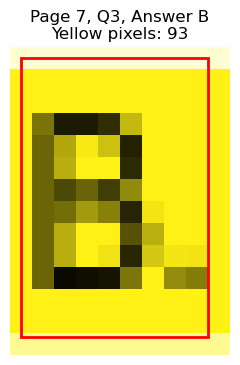

Page 7, Q3 - C: Detected box: x0=315.4, y0=228.3, x1=324.4, y1=240.9
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 36
Page 7, Q3, C: Yellow percentage: 0.0%


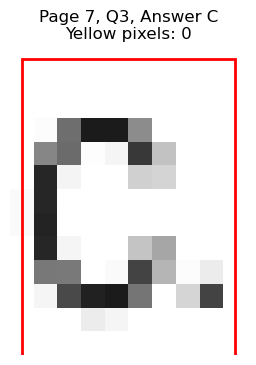

Page 7, Q3 - D: Detected box: x0=315.4, y0=240.9, x1=324.4, y1=253.5
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 40
Page 7, Q3, D: Yellow percentage: 0.0%


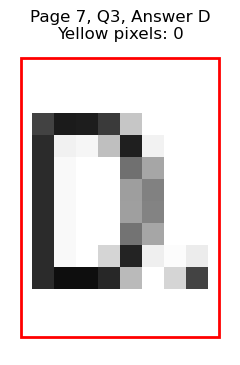


Page 7, Q3 - Selected Answer: B (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=278.8, x1=119.9, y1=291.5
Page 7, Q4, A: Yellow pixels: 52
Page 7, Q4, A: Total non-white pixels: 338
Page 7, Q4, A: Yellow percentage: 15.4%


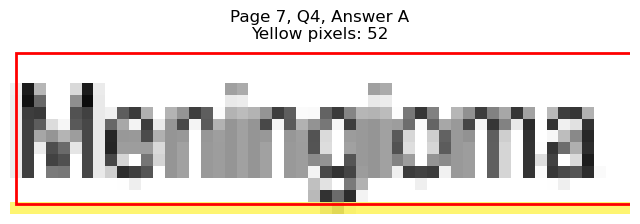

Page 7, Q4 - B: Detected box: x0=68.3, y0=291.4, x1=96.9, y1=304.1
Page 7, Q4, B: Yellow pixels: 263
Page 7, Q4, B: Total non-white pixels: 406
Page 7, Q4, B: Yellow percentage: 64.8%


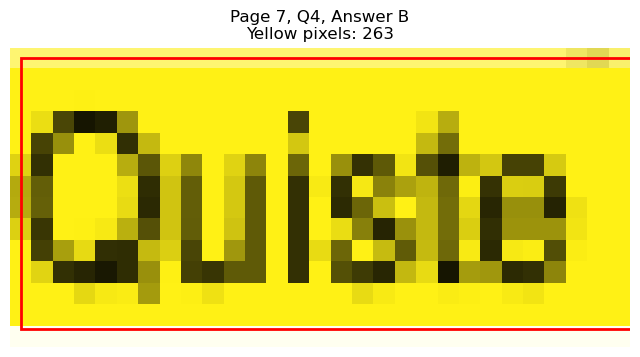

Page 7, Q4 - C: Detected box: x0=327.5, y0=278.8, x1=373.6, y1=291.5
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 217
Page 7, Q4, C: Yellow percentage: 0.0%


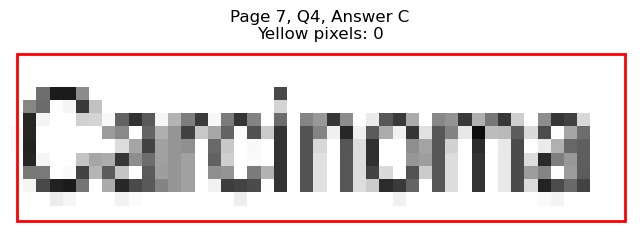

Page 7, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=359.7, y1=304.1
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 132
Page 7, Q4, D: Yellow percentage: 0.0%


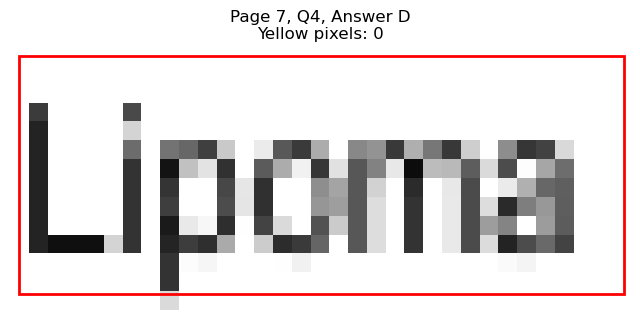


Page 7, Q4 - Selected Answer: B (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=329.2, x1=132.0, y1=341.9
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 302
Page 7, Q5, A: Yellow percentage: 0.0%


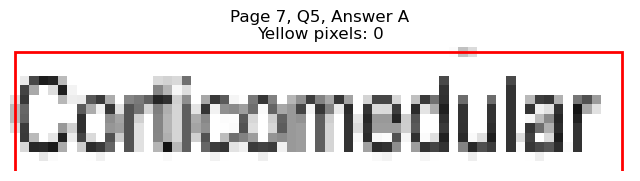

Page 7, Q5 - B: Detected box: x0=68.3, y0=341.9, x1=109.5, y1=354.6
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 202
Page 7, Q5, B: Yellow percentage: 0.0%


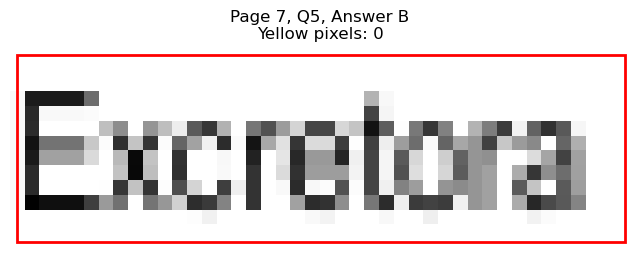

Page 7, Q5 - C: Detected box: x0=327.5, y0=329.2, x1=379.1, y1=341.9
Page 7, Q5, C: Yellow pixels: 463
Page 7, Q5, C: Total non-white pixels: 689
Page 7, Q5, C: Yellow percentage: 67.2%


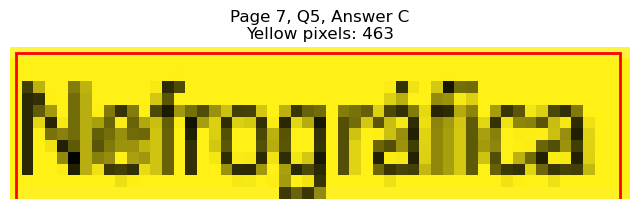

Page 7, Q5 - D: Detected box: x0=327.5, y0=341.9, x1=382.7, y1=354.6
Page 7, Q5, D: Yellow pixels: 52
Page 7, Q5, D: Total non-white pixels: 325
Page 7, Q5, D: Yellow percentage: 16.0%


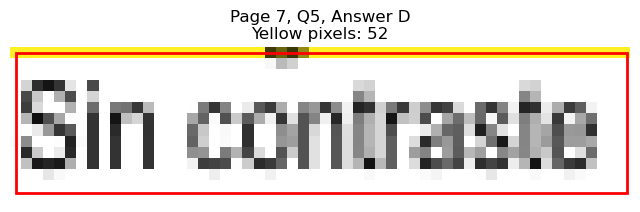


Page 7, Q5 - Selected Answer: C (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=379.7, x1=109.0, y1=392.4
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 202
Page 7, Q6, A: Yellow percentage: 0.0%


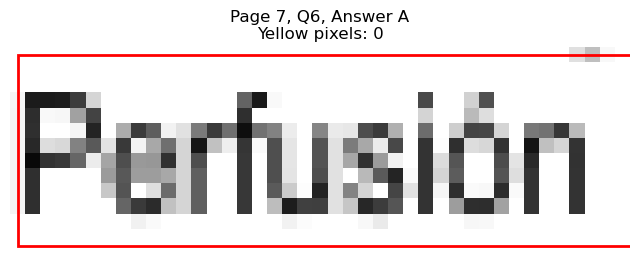

Page 7, Q6 - B: Detected box: x0=68.3, y0=392.3, x1=133.0, y1=405.0
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 346
Page 7, Q6, B: Yellow percentage: 0.0%


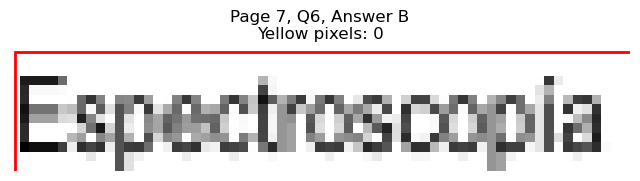

Page 7, Q6 - C: Detected box: x0=327.5, y0=379.7, x1=378.7, y1=392.4
Page 7, Q6, C: Yellow pixels: 52
Page 7, Q6, C: Total non-white pixels: 316
Page 7, Q6, C: Yellow percentage: 16.5%


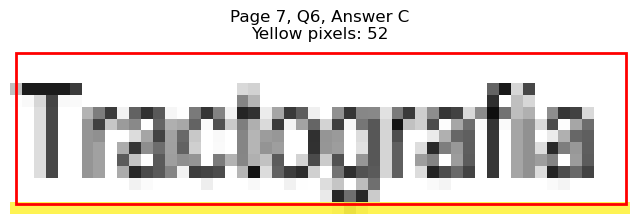

Page 7, Q6 - D: Detected box: x0=327.5, y0=392.3, x1=362.7, y1=405.0
Page 7, Q6, D: Yellow pixels: 322
Page 7, Q6, D: Total non-white pixels: 468
Page 7, Q6, D: Yellow percentage: 68.8%


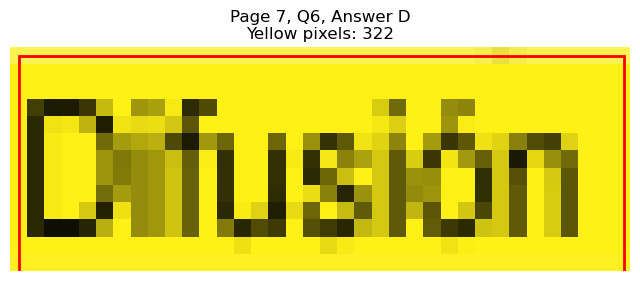


Page 7, Q6 - Selected Answer: D (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=107.9, y1=455.5
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 203
Page 7, Q7, A: Yellow percentage: 0.0%


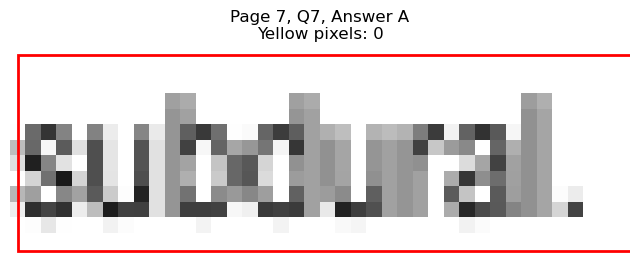

Page 7, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=118.0, y1=468.1
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 250
Page 7, Q7, B: Yellow percentage: 0.0%


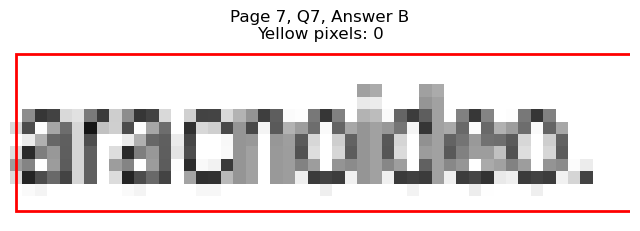

Page 7, Q7 - C: Detected box: x0=327.5, y0=442.8, x1=364.6, y1=455.5
Page 7, Q7, C: Yellow pixels: 374
Page 7, Q7, C: Total non-white pixels: 532
Page 7, Q7, C: Yellow percentage: 70.3%


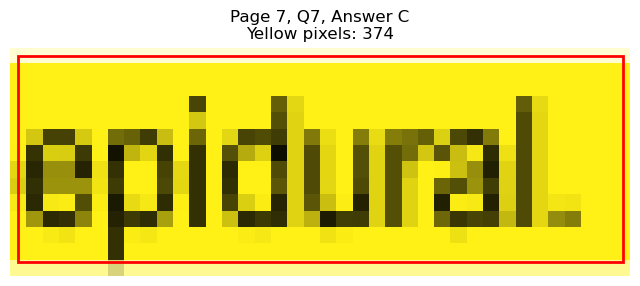

Page 7, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=382.3, y1=468.1
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 271
Page 7, Q7, D: Yellow percentage: 0.0%


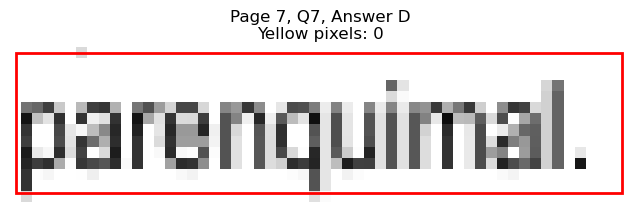


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=506.0, x1=119.9, y1=518.6
Page 7, Q8, A: Yellow pixels: 52
Page 7, Q8, A: Total non-white pixels: 293
Page 7, Q8, A: Yellow percentage: 17.7%


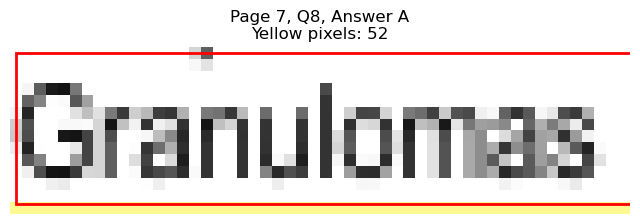

Page 7, Q8 - B: Detected box: x0=68.3, y0=518.6, x1=113.9, y1=531.2
Page 7, Q8, B: Yellow pixels: 398
Page 7, Q8, B: Total non-white pixels: 644
Page 7, Q8, B: Yellow percentage: 61.8%


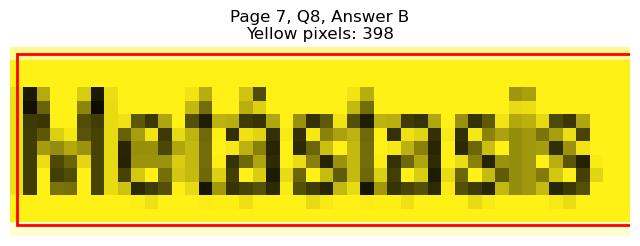

Page 7, Q8 - C: Detected box: x0=327.5, y0=506.0, x1=376.7, y1=518.6
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 274
Page 7, Q8, C: Yellow percentage: 0.0%


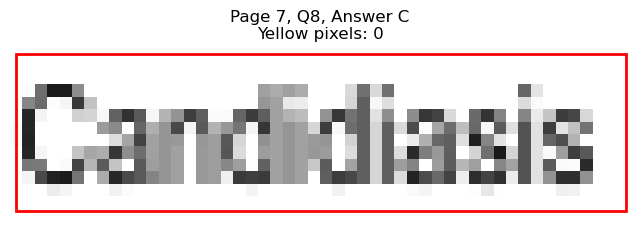

Page 7, Q8 - D: Detected box: x0=327.5, y0=518.6, x1=438.4, y1=531.2
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 571
Page 7, Q8, D: Yellow percentage: 0.0%


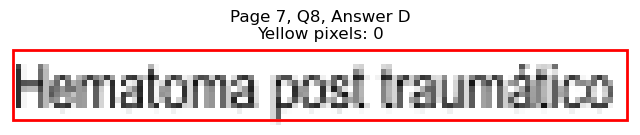


Page 7, Q8 - Selected Answer: B (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=556.5, x1=163.1, y1=569.2
Page 7, Q9, A: Yellow pixels: 96
Page 7, Q9, A: Total non-white pixels: 530
Page 7, Q9, A: Yellow percentage: 18.1%


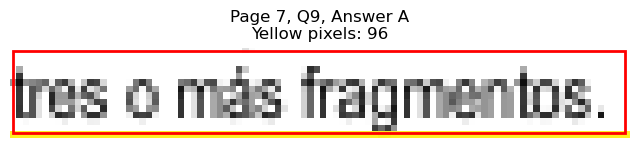

Page 7, Q9 - B: Detected box: x0=68.3, y0=569.1, x1=217.8, y1=581.8
Page 7, Q9, B: Yellow pixels: 1414
Page 7, Q9, B: Total non-white pixels: 1950
Page 7, Q9, B: Yellow percentage: 72.5%


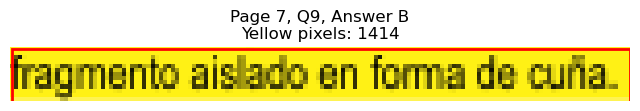

Page 7, Q9 - C: Detected box: x0=327.5, y0=556.5, x1=401.8, y1=569.2
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 388
Page 7, Q9, C: Yellow percentage: 0.0%


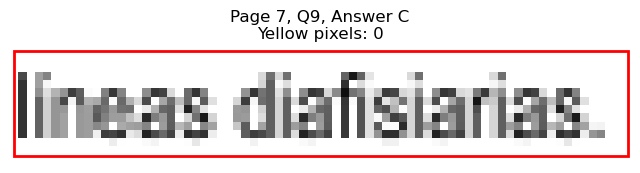

Page 7, Q9 - D: Detected box: x0=327.5, y0=569.1, x1=405.3, y1=581.8
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 389
Page 7, Q9, D: Yellow percentage: 0.0%


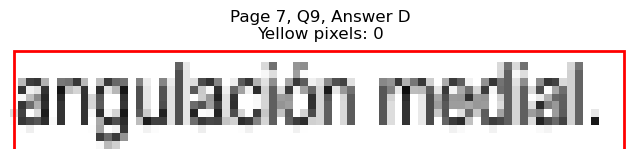


Page 7, Q9 - Selected Answer: B (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=68.3, y0=606.9, x1=135.5, y1=619.6
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 353
Page 7, Q10, A: Yellow percentage: 0.0%


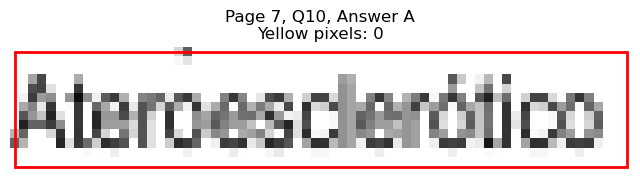

Page 7, Q10 - B: Detected box: x0=68.3, y0=619.6, x1=103.9, y1=632.3
Page 7, Q10, B: Yellow pixels: 294
Page 7, Q10, B: Total non-white pixels: 504
Page 7, Q10, B: Yellow percentage: 58.3%


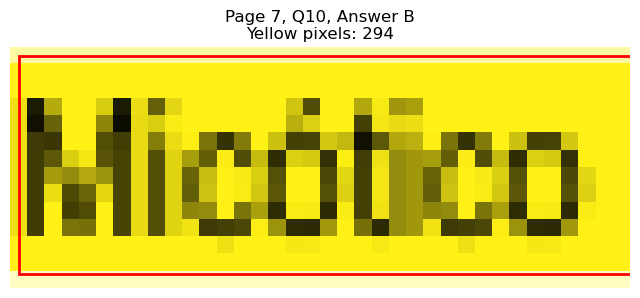

Page 7, Q10 - C: Detected box: x0=327.5, y0=606.9, x1=375.2, y1=619.6
Page 7, Q10, C: Yellow pixels: 0
Page 7, Q10, C: Total non-white pixels: 243
Page 7, Q10, C: Yellow percentage: 0.0%


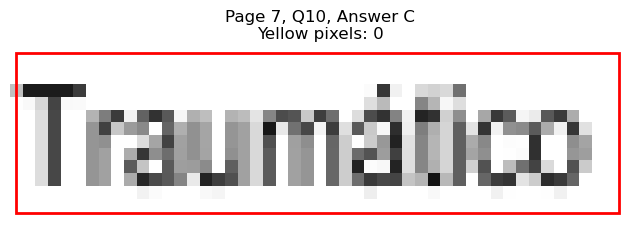

Page 7, Q10 - D: Detected box: x0=327.5, y0=619.6, x1=383.7, y1=632.3
Page 7, Q10, D: Yellow pixels: 0
Page 7, Q10, D: Total non-white pixels: 298
Page 7, Q10, D: Yellow percentage: 0.0%


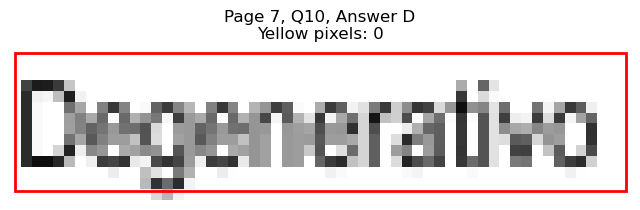


Page 7, Q10 - Selected Answer: B (based on yellow pixel count)




Page 7, Q11 - A: Detected box: x0=68.3, y0=657.5, x1=178.1, y1=670.1
Page 7, Q11, A: Yellow pixels: 1018
Page 7, Q11, A: Total non-white pixels: 1554
Page 7, Q11, A: Yellow percentage: 65.5%


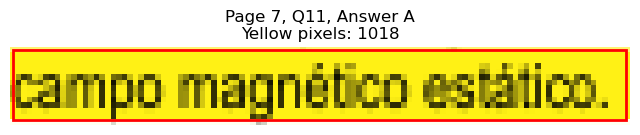

Page 7, Q11 - B: Detected box: x0=68.3, y0=670.1, x1=149.5, y1=682.7
Page 7, Q11, B: Yellow pixels: 0
Page 7, Q11, B: Total non-white pixels: 468
Page 7, Q11, B: Yellow percentage: 0.0%


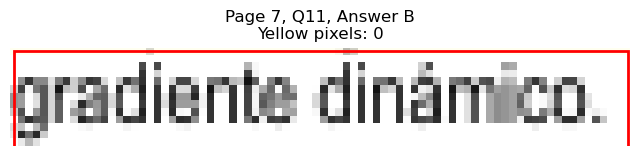

Page 7, Q11 - C: Detected box: x0=327.5, y0=657.5, x1=360.2, y1=670.1
Page 7, Q11, C: Yellow pixels: 0
Page 7, Q11, C: Total non-white pixels: 145
Page 7, Q11, C: Yellow percentage: 0.0%


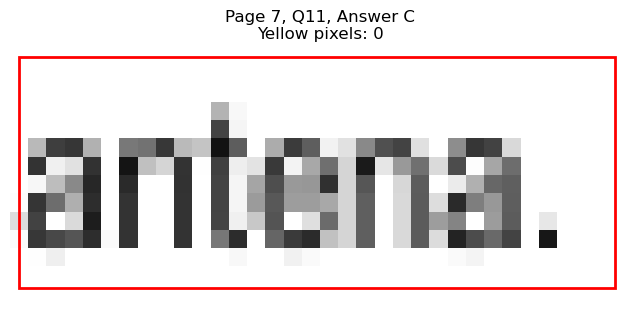

Page 7, Q11 - D: Detected box: x0=327.5, y0=670.1, x1=480.5, y1=682.7
Page 7, Q11, D: Yellow pixels: 0
Page 7, Q11, D: Total non-white pixels: 768
Page 7, Q11, D: Yellow percentage: 0.0%


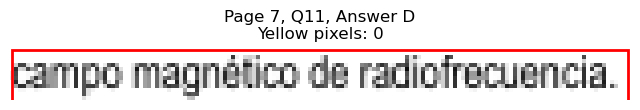


Page 7, Q11 - Selected Answer: A (based on yellow pixel count)




Page 7, Q12 - A: Detected box: x0=68.3, y0=720.6, x1=150.0, y1=733.2
Page 7, Q12, A: Yellow pixels: 83
Page 7, Q12, A: Total non-white pixels: 468
Page 7, Q12, A: Yellow percentage: 17.7%


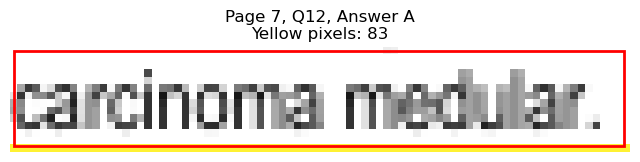

Page 7, Q12 - B: Detected box: x0=68.3, y0=733.2, x1=102.4, y1=745.8
Page 7, Q12, B: Yellow pixels: 328
Page 7, Q12, B: Total non-white pixels: 455
Page 7, Q12, B: Yellow percentage: 72.1%


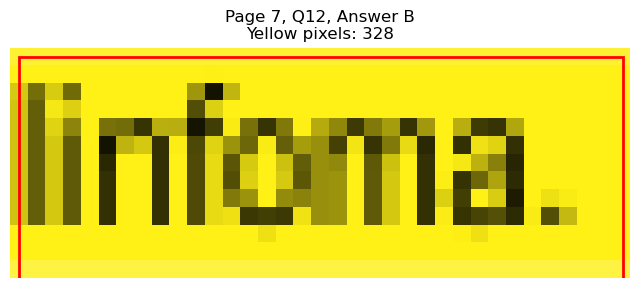

Page 7, Q12 - C: Detected box: x0=327.5, y0=720.6, x1=380.7, y1=733.2
Page 7, Q12, C: Yellow pixels: 0
Page 7, Q12, C: Total non-white pixels: 276
Page 7, Q12, C: Yellow percentage: 0.0%


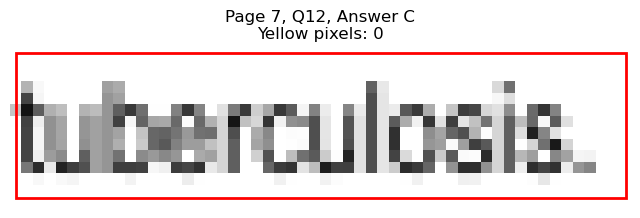

Page 7, Q12 - D: Detected box: x0=327.5, y0=733.2, x1=393.3, y1=745.8
Page 7, Q12, D: Yellow pixels: 0
Page 7, Q12, D: Total non-white pixels: 348
Page 7, Q12, D: Yellow percentage: 0.0%


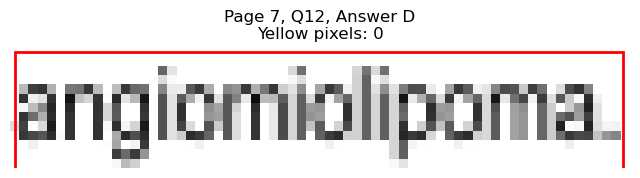


Page 7, Q12 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 11 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=121.0, y1=102.1
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 274
Page 8, Q1, A: Yellow percentage: 0.0%


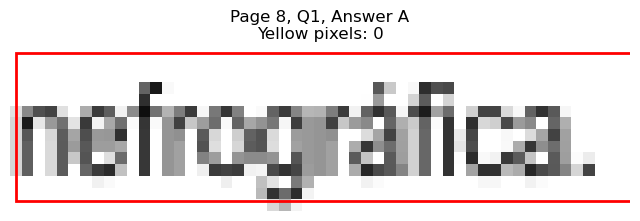

Page 8, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=132.5, y1=114.7
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 291
Page 8, Q1, B: Yellow percentage: 0.0%


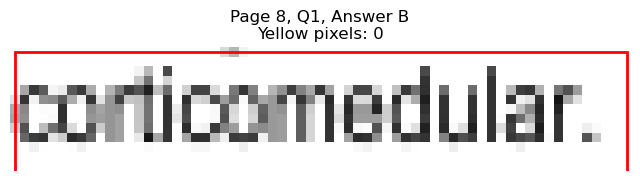

Page 8, Q1 - C: Detected box: x0=327.5, y0=89.4, x1=383.7, y1=102.1
Page 8, Q1, C: Yellow pixels: 57
Page 8, Q1, C: Total non-white pixels: 318
Page 8, Q1, C: Yellow percentage: 17.9%


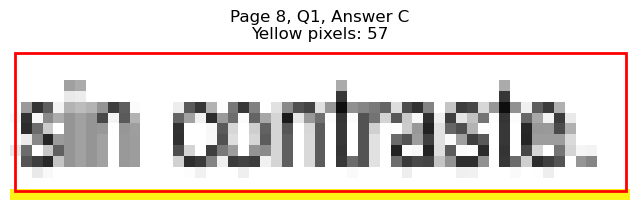

Page 8, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=370.1, y1=114.7
Page 8, Q1, D: Yellow pixels: 413
Page 8, Q1, D: Total non-white pixels: 572
Page 8, Q1, D: Yellow percentage: 72.2%


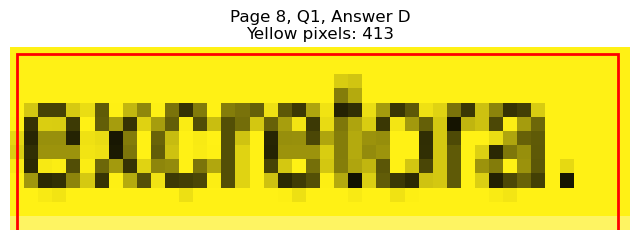


Page 8, Q1 - Selected Answer: D (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=112.9, y1=165.2
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 249
Page 8, Q2, A: Yellow percentage: 0.0%


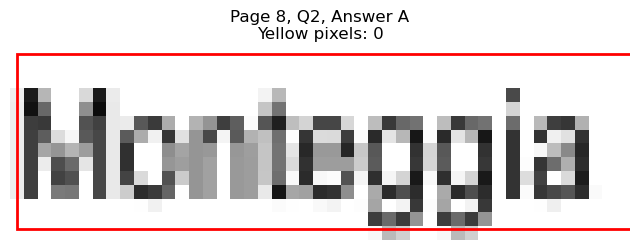

Page 8, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=130.5, y1=177.8
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 328
Page 8, Q2, B: Yellow percentage: 0.0%


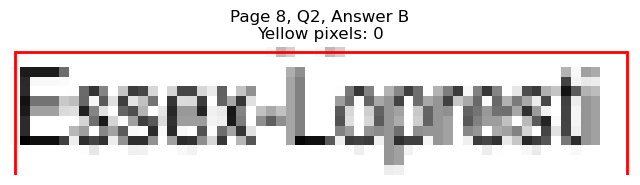

Page 8, Q2 - C: Detected box: x0=327.5, y0=152.5, x1=365.2, y1=165.2
Page 8, Q2, C: Yellow pixels: 373
Page 8, Q2, C: Total non-white pixels: 546
Page 8, Q2, C: Yellow percentage: 68.3%


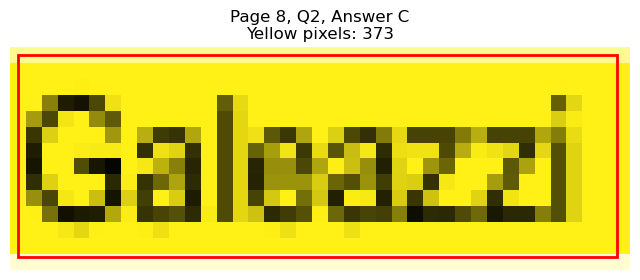

Page 8, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=367.1, y1=177.8
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 245
Page 8, Q2, D: Yellow percentage: 0.0%


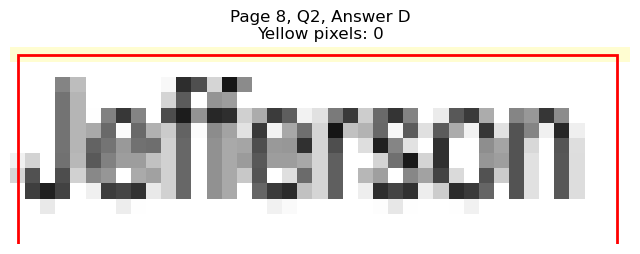


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=202.9, x1=154.6, y1=215.6
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 442
Page 8, Q3, A: Yellow percentage: 0.0%


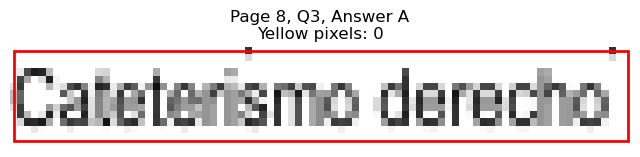

Page 8, Q3 - B: Detected box: x0=68.3, y0=215.7, x1=116.9, y1=228.3
Page 8, Q3, B: Yellow pixels: 413
Page 8, Q3, B: Total non-white pixels: 686
Page 8, Q3, B: Yellow percentage: 60.2%


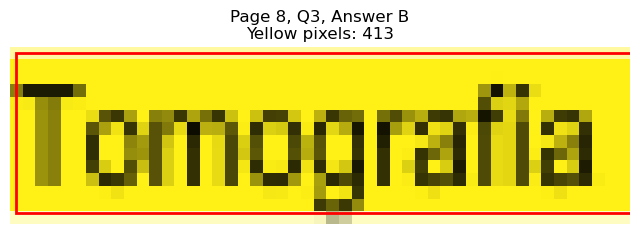

Page 8, Q3 - C: Detected box: x0=327.5, y0=202.9, x1=393.3, y1=215.6
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 363
Page 8, Q3, C: Yellow percentage: 0.0%


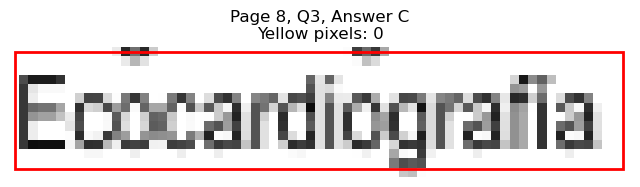

Page 8, Q3 - D: Detected box: x0=327.5, y0=215.7, x1=392.7, y1=228.3
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 345
Page 8, Q3, D: Yellow percentage: 0.0%


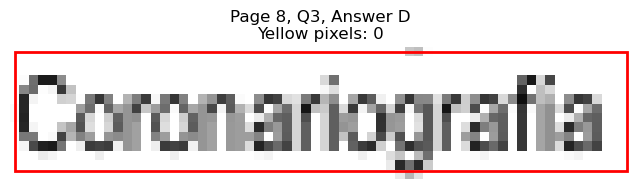


Page 8, Q3 - Selected Answer: B (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=253.5, x1=120.5, y1=266.1
Page 8, Q4, A: Yellow pixels: 490
Page 8, Q4, A: Total non-white pixels: 742
Page 8, Q4, A: Yellow percentage: 66.0%


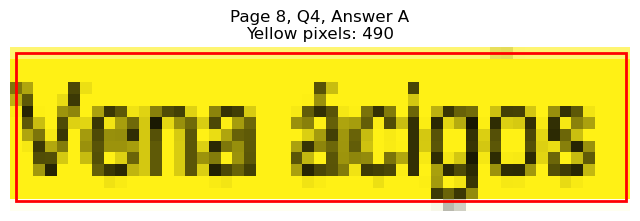

Page 8, Q4 - B: Detected box: x0=68.3, y0=266.1, x1=139.0, y1=278.7
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 394
Page 8, Q4, B: Yellow percentage: 0.0%


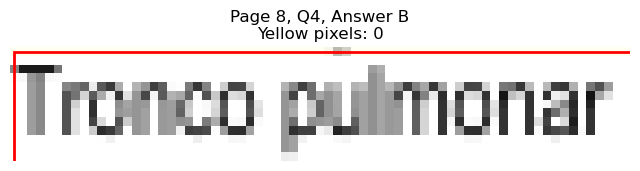

Page 8, Q4 - C: Detected box: x0=327.5, y0=253.5, x1=403.3, y1=266.1
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 405
Page 8, Q4, C: Yellow percentage: 0.0%


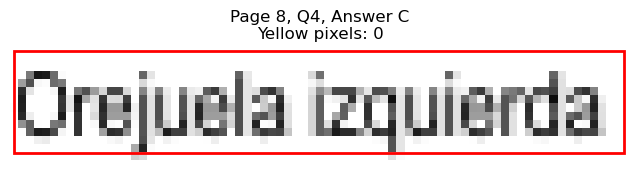

Page 8, Q4 - D: Detected box: x0=327.5, y0=266.1, x1=409.7, y1=278.7
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 417
Page 8, Q4, D: Yellow percentage: 0.0%


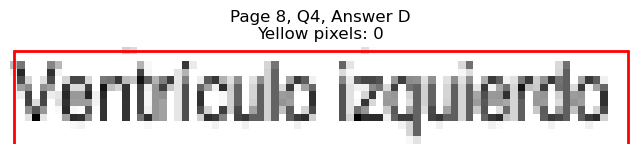


Page 8, Q4 - Selected Answer: A (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=316.6, x1=117.5, y1=329.3
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 284
Page 8, Q5, A: Yellow percentage: 0.0%


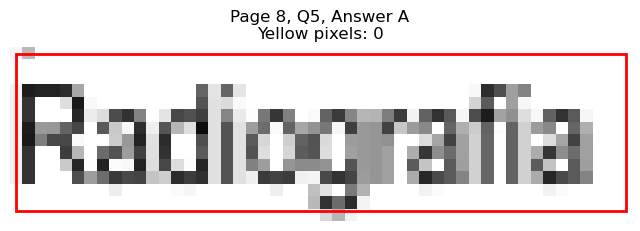

Page 8, Q5 - B: Detected box: x0=68.3, y0=329.2, x1=109.5, y1=341.9
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 224
Page 8, Q5, B: Yellow percentage: 0.0%


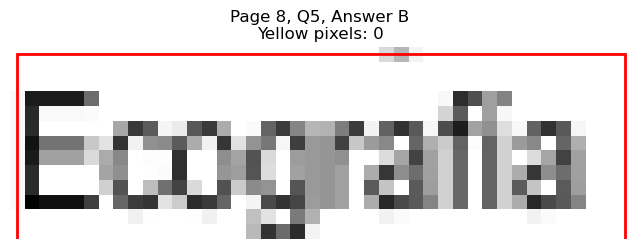

Page 8, Q5 - C: Detected box: x0=327.5, y0=316.6, x1=432.9, y1=329.3
Page 8, Q5, C: Yellow pixels: 877
Page 8, Q5, C: Total non-white pixels: 1484
Page 8, Q5, C: Yellow percentage: 59.1%


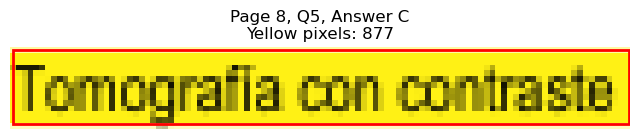

Page 8, Q5 - D: Detected box: x0=327.5, y0=329.2, x1=362.1, y1=341.9
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 192
Page 8, Q5, D: Yellow percentage: 0.0%


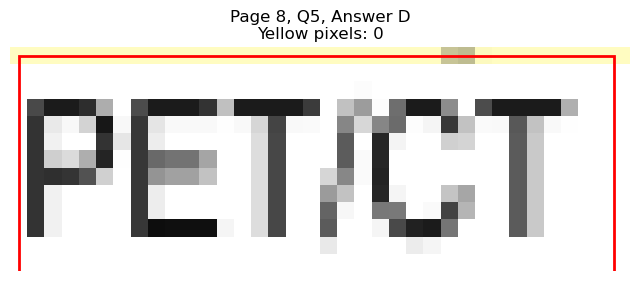


Page 8, Q5 - Selected Answer: C (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=379.7, x1=169.6, y1=392.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 529
Page 8, Q6, A: Yellow percentage: 0.0%


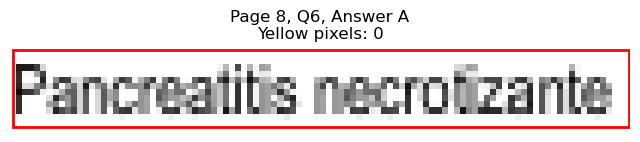

Page 8, Q6 - B: Detected box: x0=68.3, y0=392.3, x1=133.9, y1=405.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 350
Page 8, Q6, B: Yellow percentage: 0.0%


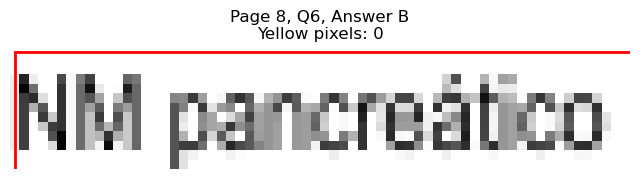

Page 8, Q6 - C: Detected box: x0=327.5, y0=379.7, x1=408.8, y1=392.4
Page 8, Q6, C: Yellow pixels: 682
Page 8, Q6, C: Total non-white pixels: 1148
Page 8, Q6, C: Yellow percentage: 59.4%


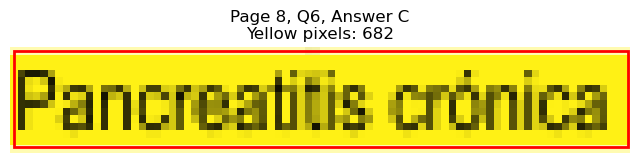

Page 8, Q6 - D: Detected box: x0=327.5, y0=392.3, x1=485.0, y1=405.0
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 973
Page 8, Q6, D: Yellow percentage: 0.0%


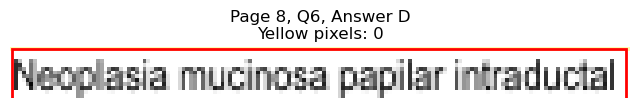


Page 8, Q6 - Selected Answer: C (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=442.8, x1=132.0, y1=455.5
Page 8, Q7, A: Yellow pixels: 65
Page 8, Q7, A: Total non-white pixels: 396
Page 8, Q7, A: Yellow percentage: 16.4%


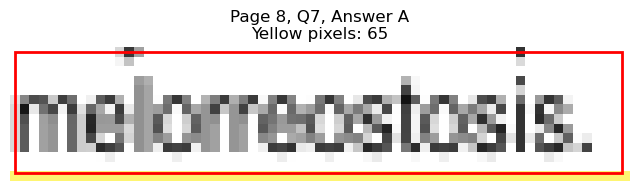

Page 8, Q7 - B: Detected box: x0=68.3, y0=455.5, x1=129.0, y1=468.1
Page 8, Q7, B: Yellow pixels: 580
Page 8, Q7, B: Total non-white pixels: 868
Page 8, Q7, B: Yellow percentage: 66.8%


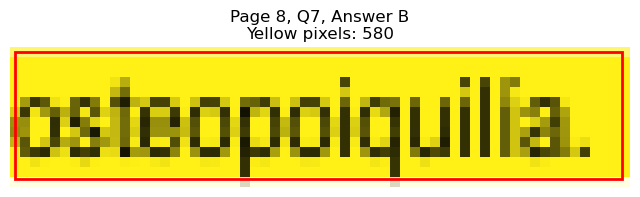

Page 8, Q7 - C: Detected box: x0=327.5, y0=442.8, x1=425.3, y1=455.5
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 530
Page 8, Q7, C: Yellow percentage: 0.0%


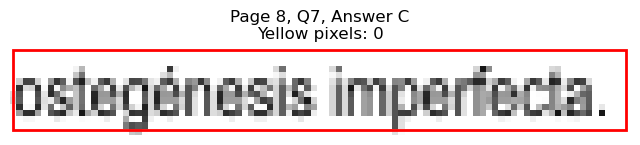

Page 8, Q7 - D: Detected box: x0=327.5, y0=455.5, x1=470.5, y1=468.1
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 760
Page 8, Q7, D: Yellow percentage: 0.0%


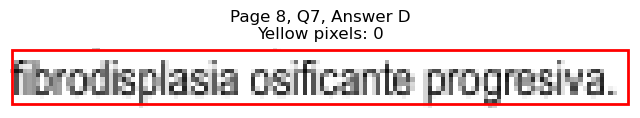


Page 8, Q7 - Selected Answer: B (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=506.0, x1=152.5, y1=518.6
Page 8, Q8, A: Yellow pixels: 779
Page 8, Q8, A: Total non-white pixels: 1190
Page 8, Q8, A: Yellow percentage: 65.5%


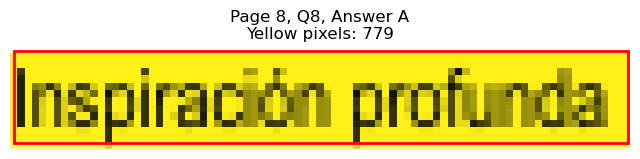

Page 8, Q8 - B: Detected box: x0=68.3, y0=518.6, x1=120.5, y1=531.2
Page 8, Q8, B: Yellow pixels: 53
Page 8, Q8, B: Total non-white pixels: 327
Page 8, Q8, B: Yellow percentage: 16.2%


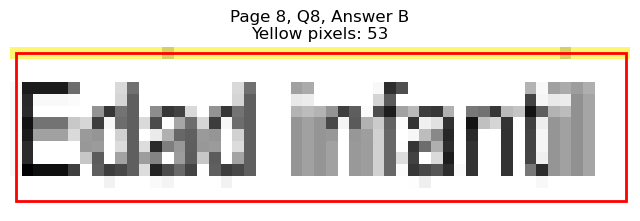

Page 8, Q8 - C: Detected box: x0=327.5, y0=506.0, x1=394.7, y1=518.6
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 343
Page 8, Q8, C: Yellow percentage: 0.0%


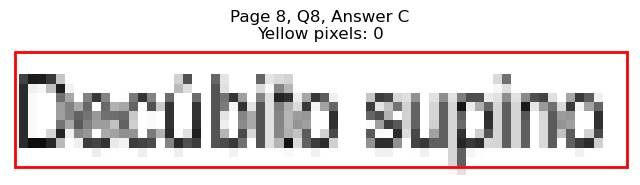

Page 8, Q8 - D: Detected box: x0=327.5, y0=518.6, x1=357.7, y1=531.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 160
Page 8, Q8, D: Yellow percentage: 0.0%


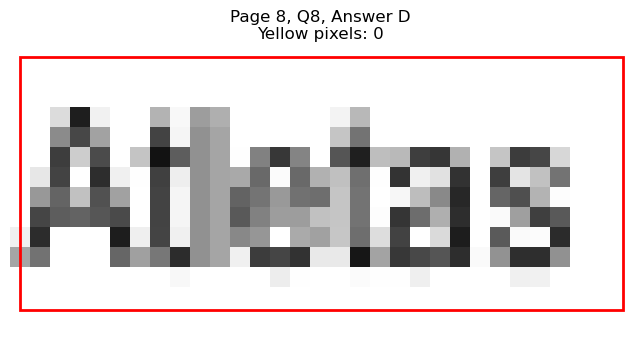


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=569.1, x1=99.4, y1=581.8
Page 8, Q9, A: Yellow pixels: 297
Page 8, Q9, A: Total non-white pixels: 416
Page 8, Q9, A: Yellow percentage: 71.4%


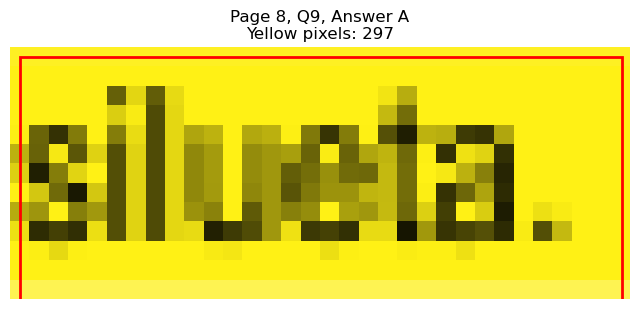

Page 8, Q9 - B: Detected box: x0=68.3, y0=581.7, x1=107.9, y1=594.4
Page 8, Q9, B: Yellow pixels: 40
Page 8, Q9, B: Total non-white pixels: 225
Page 8, Q9, B: Yellow percentage: 17.8%


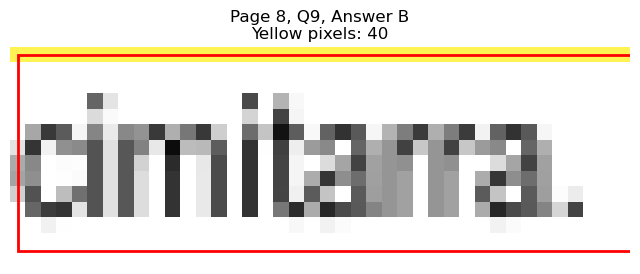

Page 8, Q9 - C: Detected box: x0=327.5, y0=569.1, x1=393.8, y1=581.8
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 304
Page 8, Q9, C: Yellow percentage: 0.0%


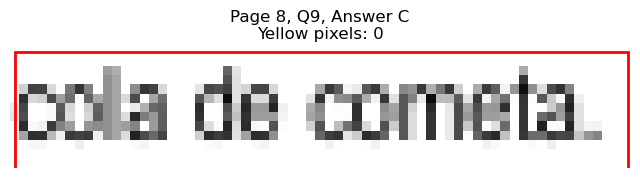

Page 8, Q9 - D: Detected box: x0=327.5, y0=581.7, x1=394.3, y1=594.4
Page 8, Q9, D: Yellow pixels: 0
Page 8, Q9, D: Total non-white pixels: 315
Page 8, Q9, D: Yellow percentage: 0.0%


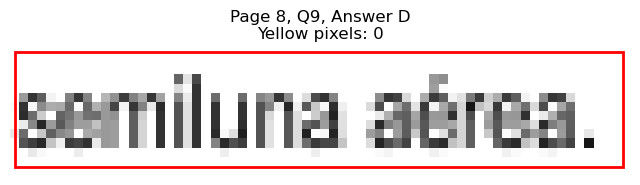


Page 8, Q9 - Selected Answer: A (based on yellow pixel count)




Page 8, Q10 - A: Detected box: x0=68.3, y0=632.2, x1=108.4, y1=644.9
Page 8, Q10, A: Yellow pixels: 367
Page 8, Q10, A: Total non-white pixels: 533
Page 8, Q10, A: Yellow percentage: 68.9%


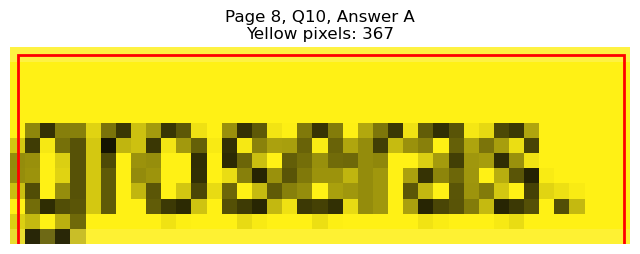

Page 8, Q10 - B: Detected box: x0=68.3, y0=644.9, x1=113.9, y1=657.5
Page 8, Q10, B: Yellow pixels: 0
Page 8, Q10, B: Total non-white pixels: 250
Page 8, Q10, B: Yellow percentage: 0.0%


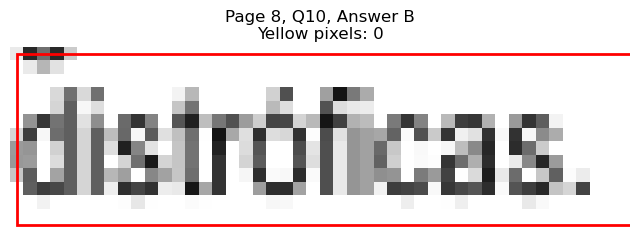

Page 8, Q10 - C: Detected box: x0=327.5, y0=632.2, x1=367.1, y1=644.9
Page 8, Q10, C: Yellow pixels: 0
Page 8, Q10, C: Total non-white pixels: 171
Page 8, Q10, C: Yellow percentage: 0.0%


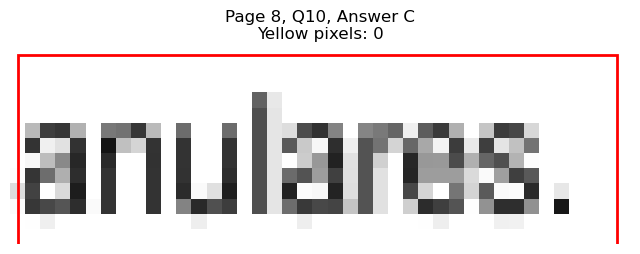

Page 8, Q10 - D: Detected box: x0=327.5, y0=644.9, x1=384.2, y1=657.5
Page 8, Q10, D: Yellow pixels: 0
Page 8, Q10, D: Total non-white pixels: 279
Page 8, Q10, D: Yellow percentage: 0.0%


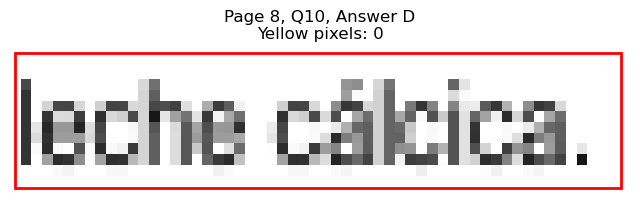


Page 8, Q10 - Selected Answer: A (based on yellow pixel count)




Page 8, Q11 - A: Detected box: x0=68.3, y0=695.4, x1=172.6, y1=708.0
Page 8, Q11, A: Yellow pixels: 0
Page 8, Q11, A: Total non-white pixels: 512
Page 8, Q11, A: Yellow percentage: 0.0%


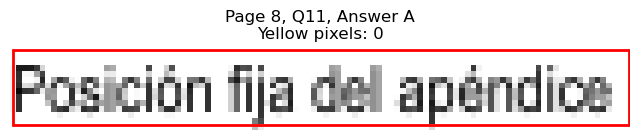

Page 8, Q11 - B: Detected box: x0=68.3, y0=708.0, x1=174.1, y1=720.6
Page 8, Q11, B: Yellow pixels: 0
Page 8, Q11, B: Total non-white pixels: 529
Page 8, Q11, B: Yellow percentage: 0.0%


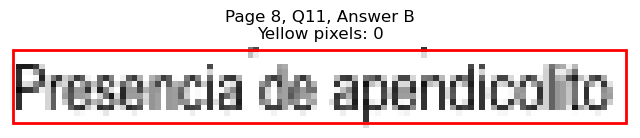

Page 8, Q11 - C: Detected box: x0=327.5, y0=695.4, x1=497.6, y1=708.0
Page 8, Q11, C: Yellow pixels: 171
Page 8, Q11, C: Total non-white pixels: 1179
Page 8, Q11, C: Yellow percentage: 14.5%


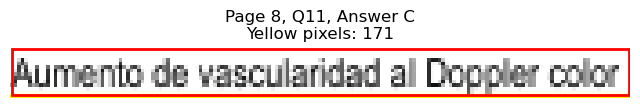

Page 8, Q11 - D: Detected box: x0=327.5, y0=708.0, x1=431.8, y1=720.6
Page 8, Q11, D: Yellow pixels: 968
Page 8, Q11, D: Total non-white pixels: 1470
Page 8, Q11, D: Yellow percentage: 65.9%


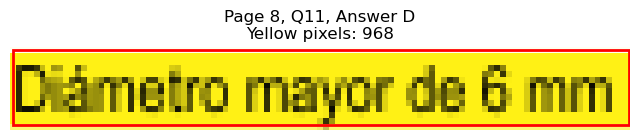


Page 8, Q11 - Selected Answer: D (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=115.5, y1=114.7
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 228
Page 9, Q1, A: Yellow percentage: 0.0%


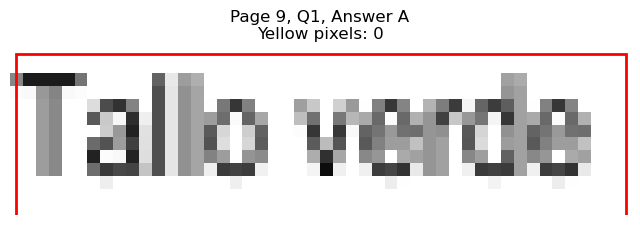

Page 9, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=109.5, y1=127.3
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 207
Page 9, Q1, B: Yellow percentage: 0.0%


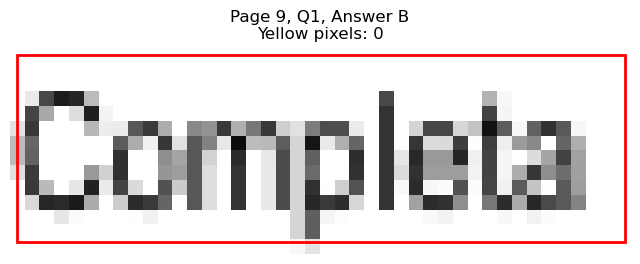

Page 9, Q1 - C: Detected box: x0=327.5, y0=102.0, x1=373.7, y1=114.7
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 270
Page 9, Q1, C: Yellow percentage: 0.0%


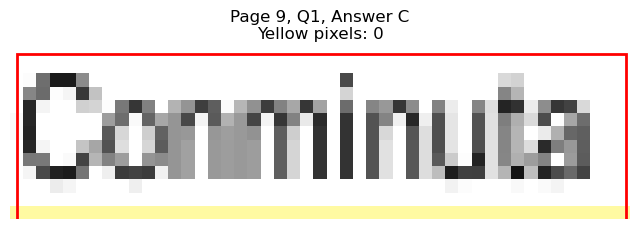

Page 9, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=353.1, y1=127.3
Page 9, Q1, D: Yellow pixels: 235
Page 9, Q1, D: Total non-white pixels: 378
Page 9, Q1, D: Yellow percentage: 62.2%


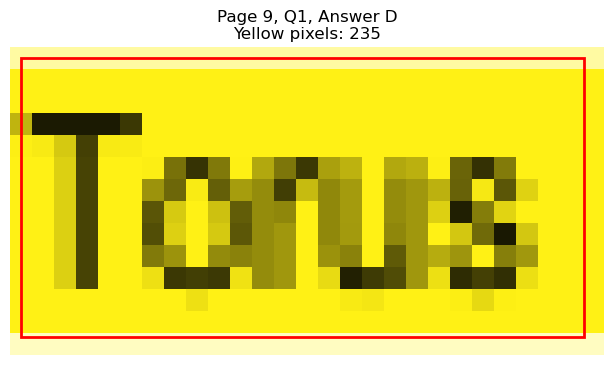


Page 9, Q1 - Selected Answer: D (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=81.4, y1=177.8
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 45
Page 9, Q2, A: Yellow percentage: 0.0%


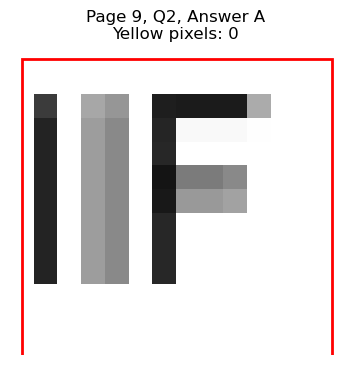

Page 9, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=78.4, y1=190.4
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 32
Page 9, Q2, B: Yellow percentage: 0.0%


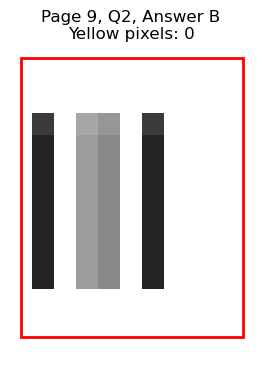

Page 9, Q2 - C: Detected box: x0=327.5, y0=165.1, x1=338.6, y1=177.8
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 54
Page 9, Q2, C: Yellow percentage: 0.0%


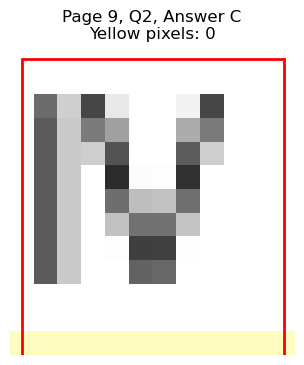

Page 9, Q2 - D: Detected box: x0=315.4, y0=177.7, x1=324.4, y1=190.4
Page 9, Q2, D: Yellow pixels: 90
Page 9, Q2, D: Total non-white pixels: 140
Page 9, Q2, D: Yellow percentage: 64.3%


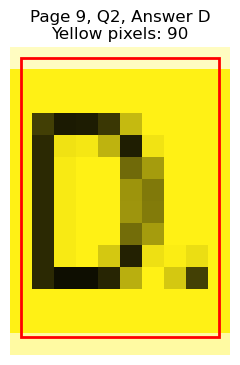


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=215.7, x1=117.5, y1=228.3
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 284
Page 9, Q3, A: Yellow percentage: 0.0%


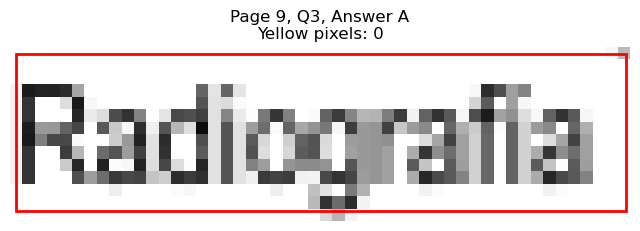

Page 9, Q3 - B: Detected box: x0=68.3, y0=228.3, x1=118.5, y1=240.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 248
Page 9, Q3, B: Yellow percentage: 0.0%


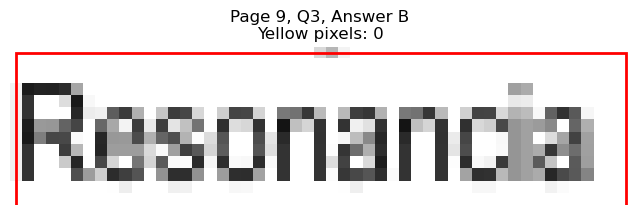

Page 9, Q3 - C: Detected box: x0=327.5, y0=215.7, x1=376.1, y1=228.3
Page 9, Q3, C: Yellow pixels: 417
Page 9, Q3, C: Total non-white pixels: 700
Page 9, Q3, C: Yellow percentage: 59.6%


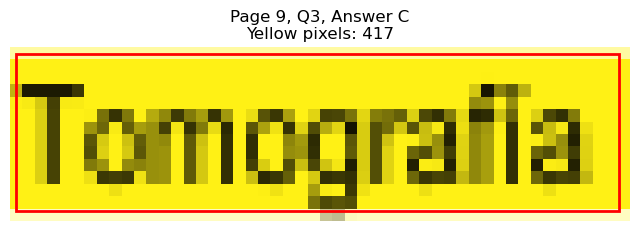

Page 9, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=368.7, y1=240.9
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 259
Page 9, Q3, D: Yellow percentage: 0.0%


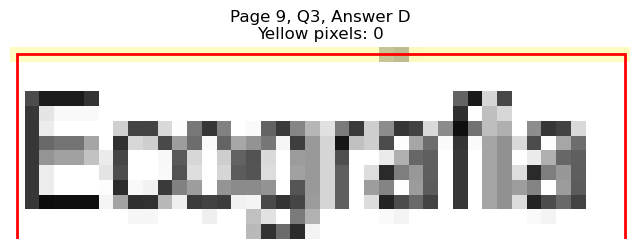


Page 9, Q3 - Selected Answer: C (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=266.1, x1=143.5, y1=278.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 410
Page 9, Q4, A: Yellow percentage: 0.0%


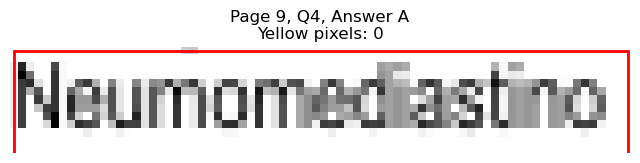

Page 9, Q4 - B: Detected box: x0=68.3, y0=278.8, x1=135.5, y1=291.5
Page 9, Q4, B: Yellow pixels: 598
Page 9, Q4, B: Total non-white pixels: 952
Page 9, Q4, B: Yellow percentage: 62.8%


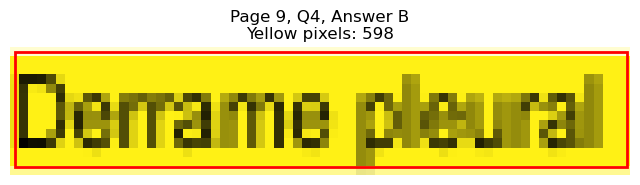

Page 9, Q4 - C: Detected box: x0=327.5, y0=266.1, x1=416.8, y1=278.7
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 455
Page 9, Q4, C: Yellow percentage: 0.0%


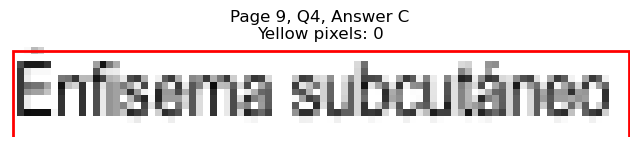

Page 9, Q4 - D: Detected box: x0=327.5, y0=278.8, x1=458.5, y1=291.5
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 660
Page 9, Q4, D: Yellow percentage: 0.0%


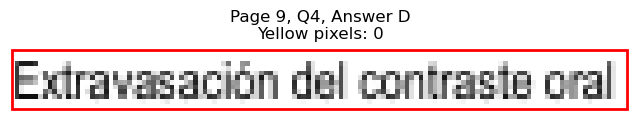


Page 9, Q4 - Selected Answer: B (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=316.6, x1=163.6, y1=329.3
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 475
Page 9, Q5, A: Yellow percentage: 0.0%


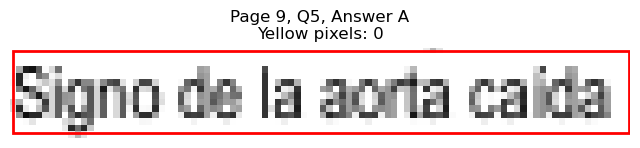

Page 9, Q5 - B: Detected box: x0=68.3, y0=329.2, x1=239.8, y1=341.9
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 857
Page 9, Q5, B: Yellow percentage: 0.0%


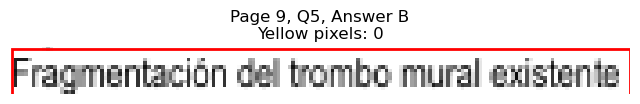

Page 9, Q5 - C: Detected box: x0=327.5, y0=316.6, x1=531.7, y1=329.3
Page 9, Q5, C: Yellow pixels: 1649
Page 9, Q5, C: Total non-white pixels: 2870
Page 9, Q5, C: Yellow percentage: 57.5%


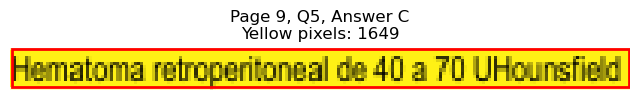

Page 9, Q5 - D: Detected box: x0=327.5, y0=329.2, x1=449.9, y1=341.9
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 738
Page 9, Q5, D: Yellow percentage: 0.0%


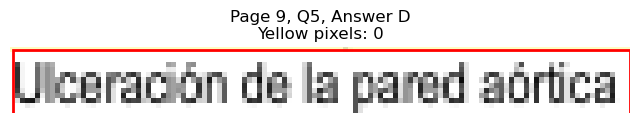


Page 9, Q5 - Selected Answer: C (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=392.3, x1=76.8, y1=405.0
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 37
Page 9, Q6, A: Yellow percentage: 0.0%


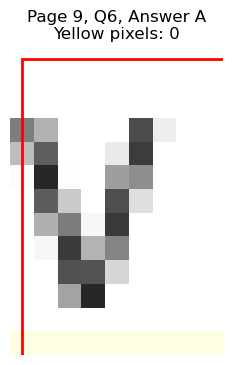

Page 9, Q6 - B: Detected box: x0=68.3, y0=404.9, x1=79.3, y1=417.6
Page 9, Q6, B: Yellow pixels: 125
Page 9, Q6, B: Total non-white pixels: 168
Page 9, Q6, B: Yellow percentage: 74.4%


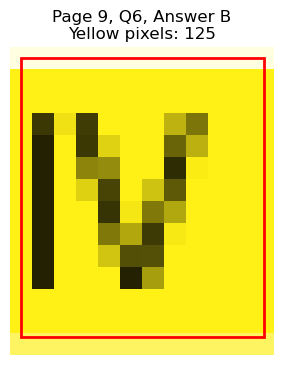

Page 9, Q6 - C: Detected box: x0=315.4, y0=392.3, x1=324.4, y1=405.0
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 37
Page 9, Q6, C: Yellow percentage: 0.0%


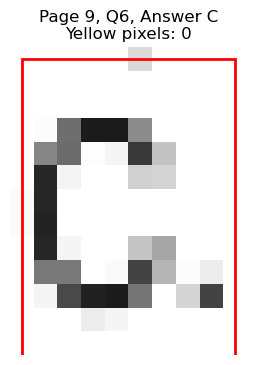

Page 9, Q6 - D: Detected box: x0=327.5, y0=404.9, x1=337.6, y1=417.6
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 48
Page 9, Q6, D: Yellow percentage: 0.0%


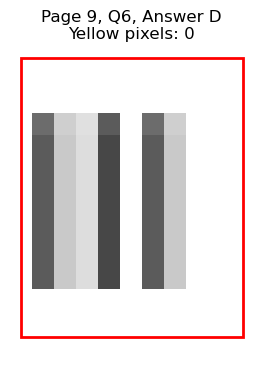


Page 9, Q6 - Selected Answer: B (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=56.6, y0=455.5, x1=65.2, y1=468.1
Page 9, Q7, A: Yellow pixels: 10
Page 9, Q7, A: Total non-white pixels: 45
Page 9, Q7, A: Yellow percentage: 22.2%


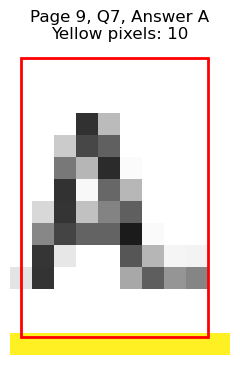

Page 9, Q7 - B: Detected box: x0=56.6, y0=468.1, x1=65.2, y1=480.7
Page 9, Q7, B: Yellow pixels: 93
Page 9, Q7, B: Total non-white pixels: 130
Page 9, Q7, B: Yellow percentage: 71.5%


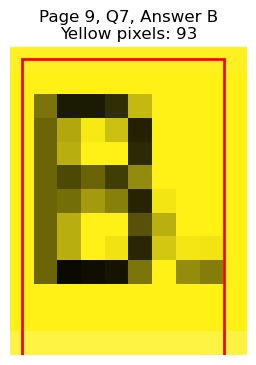

Page 9, Q7 - C: Detected box: x0=327.5, y0=455.5, x1=337.6, y1=468.1
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 48
Page 9, Q7, C: Yellow percentage: 0.0%


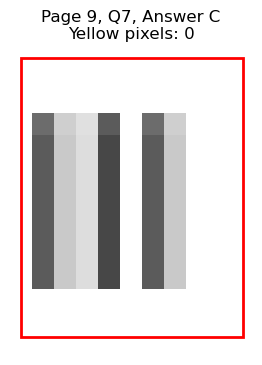

Page 9, Q7 - D: Detected box: x0=327.5, y0=468.1, x1=338.6, y1=480.7
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 42
Page 9, Q7, D: Yellow percentage: 0.0%


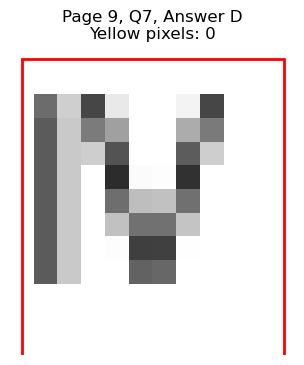


Page 9, Q7 - Selected Answer: B (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=518.6, x1=78.4, y1=531.2
Page 9, Q8, A: Yellow pixels: 11
Page 9, Q8, A: Total non-white pixels: 43
Page 9, Q8, A: Yellow percentage: 25.6%


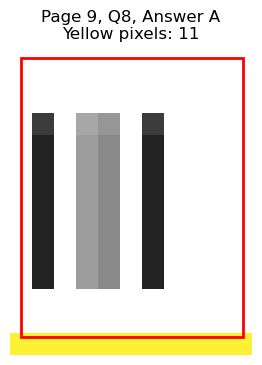

Page 9, Q8 - B: Detected box: x0=56.6, y0=531.2, x1=65.2, y1=543.8
Page 9, Q8, B: Yellow pixels: 93
Page 9, Q8, B: Total non-white pixels: 130
Page 9, Q8, B: Yellow percentage: 71.5%


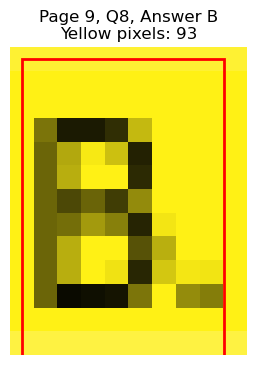

Page 9, Q8 - C: Detected box: x0=327.5, y0=165.1, x1=338.6, y1=177.8
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 54
Page 9, Q8, C: Yellow percentage: 0.0%


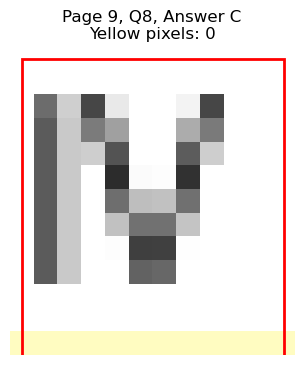

Page 9, Q8 - D: Detected box: x0=315.4, y0=177.7, x1=324.4, y1=190.4
Page 9, Q8, D: Yellow pixels: 90
Page 9, Q8, D: Total non-white pixels: 140
Page 9, Q8, D: Yellow percentage: 64.3%


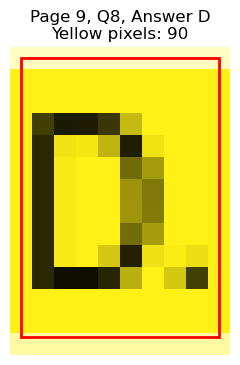


Page 9, Q8 - Selected Answer: B (based on yellow pixel count)






In [17]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [18]:
questions_df

,question
0,En el estudio de ecocardiografía de un niño. ¿...
1,En radiografía de manos: disminución de los es...
2,En la ecografía Doppler. ¿Cuál es un signo esp...
3,En el estudio TC de obstrucción intestinal por...
4,Mujer de 20 años con infecciones urinarias a r...
...,...
95,En TC. ¿Cuál es la manifestación más frecuente...
96,¿Cuál es un hallazgo tomográfico de ruptura ag...
97,"Varón de 45 años, con trauma abdominal cerrado..."
98,Mujer de 26 años con dolor en rodilla derecha ...


In [19]:
answers_df

,option_A,option_B,option_C,option_D
0,Subcostal eje largo,Apical,Paraesternal,Supraesternal
1,artritis reumatoidea.,enfermedad de Paget ósea.,artropatía degenerativa.,artritis psoriásica.
2,Trombo hiperecogénico,Dilatación venosa,Recanalización post tratamiento,Arterialización portal
3,del pico.,de la rueda.,de las heces.,de doble pared.
4,Megauréter,Ureterocele,Divertículo,Estenosis ureteral
...,...,...,...,...
95,Neumomediastino,Derrame pleural,Enfisema subcutáneo,Extravasación del contraste oral
96,Signo de la aorta caída,Fragmentación del trombo mural existente,Hematoma retroperitoneal de 40 a 70 UHounsfield,Ulceración de la pared aórtica
97,V,IV,II,III
98,II,I,III,IV


In [20]:
correct_answers_df

,correct_answer
0,A
1,C
2,D
3,B
4,B
...,...
95,B
96,C
97,B
98,B


In [21]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,correct_answer
0,En el estudio de ecocardiografía de un niño. ¿...,Subcostal eje largo,Apical,Paraesternal,Supraesternal,A
1,En radiografía de manos: disminución de los es...,artritis reumatoidea.,enfermedad de Paget ósea.,artropatía degenerativa.,artritis psoriásica.,C
2,En la ecografía Doppler. ¿Cuál es un signo esp...,Trombo hiperecogénico,Dilatación venosa,Recanalización post tratamiento,Arterialización portal,D
3,En el estudio TC de obstrucción intestinal por...,del pico.,de la rueda.,de las heces.,de doble pared.,B
4,Mujer de 20 años con infecciones urinarias a r...,Megauréter,Ureterocele,Divertículo,Estenosis ureteral,B
...,...,...,...,...,...,...
95,En TC. ¿Cuál es la manifestación más frecuente...,Neumomediastino,Derrame pleural,Enfisema subcutáneo,Extravasación del contraste oral,B
96,¿Cuál es un hallazgo tomográfico de ruptura ag...,Signo de la aorta caída,Fragmentación del trombo mural existente,Hematoma retroperitoneal de 40 a 70 UHounsfield,Ulceración de la pared aórtica,C
97,"Varón de 45 años, con trauma abdominal cerrado...",V,IV,II,III,B
98,Mujer de 26 años con dolor en rodilla derecha ...,II,I,III,IV,B


In [22]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2023/RADIOLOGÍA.csv
